In [ ]:
!pip install miceforest

In [ ]:
# ============================================
# 0. IMPORT LIBRARY
# ============================================
import numpy as np
import pandas as pd
import time

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, label_binarize

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import KNNImputer, IterativeImputer, SimpleImputer
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.linear_model import BayesianRidge
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

RANDOM_STATE = 42
POS_LABEL = "triggered"
NEG_LABEL = "no_effect"

In [ ]:
# ============================================
# 1. LOAD DATA & SPLIT TRAIN/TEST
# ============================================
#
train_path = "LTCDAR3_TRAIN.csv"
test_path  = "LTCDAR3_TEST.csv"

df_train = pd.read_csv(train_path)
df_test  = pd.read_csv(test_path)

print("Train shape:", df_train.shape)
print("Test shape :", df_test.shape)


TARGET_COL = "Cell death and Apoptosis responses"

X_train = df_train.drop(columns=[TARGET_COL])
y_train = df_train[TARGET_COL]

X_test = df_test.drop(columns=[TARGET_COL])
y_test = df_test[TARGET_COL]

# # Detection of numerical and categorical features
numeric_features = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["int64", "float64"]).columns.tolist()

print("Numeric Features:", numeric_features)
print("Categorical Features:", categorical_features)


print("X Train Shape:", X_train.shape)
print("X Test Shape :", X_test.shape)

Train shape: (225, 13)
Test shape : (19, 13)
Numeric Features: ['Core size (nm)', 'Zeta Potential (mV)', 'Specific surface area (m2/g) ', 'Exposure  dose (μg/ml)', 'Exposure duration  (h)']
Categorical Features: ['Nanoparticles', 'Shape', 'Surface  coatings', 'Tissue', 'Cell type', 'Cell line', 'Microarray Method_Transcriptomics']
X Train Shape: (225, 12)
X Test Shape : (19, 12)


In [ ]:
#Analisis Missingness
#Persentase Missing Value
import pandas as pd

def missing_percentage(df):

    missing = pd.DataFrame({
        'Missing_Count': df.isnull().sum(),
        'Missing_Percentage': round(
            df.isnull().mean()*100,2)
    })

    return missing.sort_values(
        'Missing_Percentage',
        ascending=False)

missing_table = missing_percentage(X_train)

print(missing_table)

                                   Missing_Count  Missing_Percentage
Zeta Potential (mV)                           20                8.89
Shape                                         17                7.56
Surface  coatings                             15                6.67
Specific surface area (m2/g)                  10                4.44
Cell type                                     10                4.44
Tissue                                         4                1.78
Cell line                                      4                1.78
Exposure  dose (μg/ml)                         3                1.33
Nanoparticles                                  0                0.00
Core size (nm)                                 0                0.00
Exposure duration  (h)                         0                0.00
Microarray Method_Transcriptomics              0                0.00


In [ ]:
missing_table.to_excel('missing_training.xlsx', index=True)
print("missing_table has been successfully saved to 'missing_training.xlsx'")

missing_table has been successfully saved to 'missing_training.xlsx'


In [ ]:
missing_test_table = missing_percentage(X_test)
print(missing_test_table)
missing_test_table.to_excel('missing_testing_.xlsx', index=True)
print("missing_table has been successfully saved to 'missing_testing.xlsx'")

                                   Missing_Count  Missing_Percentage
Zeta Potential (mV)                           10               52.63
Shape                                          5               26.32
Specific surface area (m2/g)                   5               26.32
Nanoparticles                                  0                0.00
Surface  coatings                              0                0.00
Core size (nm)                                 0                0.00
Exposure  dose (μg/ml)                         0                0.00
Exposure duration  (h)                         0                0.00
Tissue                                         0                0.00
Cell type                                      0                0.00
Cell line                                      0                0.00
Microarray Method_Transcriptomics              0                0.00
missing_table has been successfully saved to 'missing_testing.xlsx'


In [ ]:
import pandas as pd

# Define old and new column names
old_col = 'Specific surface area (m2/g) '
new_col = 'Specific surface area (m²/g)'

X_train = X_train.rename(columns={old_col: new_col})
X_test = X_test.rename(columns={old_col: new_col})

numeric_features = [new_col if col == old_col else col for col in numeric_features]

print("Columns successfully updated!")
print("Current numerical features:", numeric_features)

Columns successfully updated!
Current numerical features: ['Core size (nm)', 'Zeta Potential (mV)', 'Specific surface area (m²/g)', 'Exposure  dose (μg/ml)', 'Exposure duration  (h)']


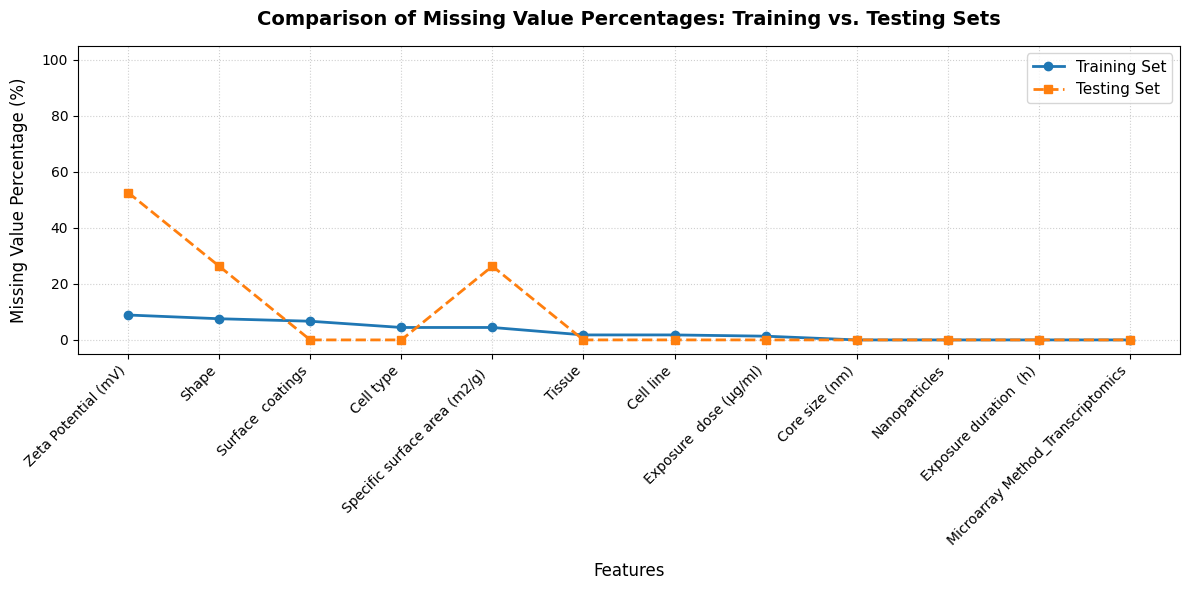

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Aligning training and testing data based on the latest index (features)
df_missing_train = missing_table.copy().rename(columns={'Missing_Percentage': 'Training'})
df_missing_test = missing_test_table.copy().rename(columns={'Missing_Percentage': 'Testing'})

# Merging the two dataframes based on a feature
df_compare = pd.merge(df_missing_train[['Training']], df_missing_test[['Testing']], left_index=True, right_index=True, how='outer').fillna(0)

# Sort by percentage value in training data to make the graph neater
df_compare = df_compare.sort_values(by='Training', ascending=False)

# creating a plot
plt.figure(figsize=(12, 6))
plt.plot(df_compare.index, df_compare['Training'], marker='o', label='Training Set', color='#1f77b4', linewidth=2)
plt.plot(df_compare.index, df_compare['Testing'], marker='s', label='Testing Set', color='#ff7f0e', linewidth=2, linestyle='--')

# Chart customization
plt.title('Comparison of Missing Value Percentages: Training vs. Testing Sets', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Features', fontsize=12, labelpad=10)
plt.ylabel('Missing Value Percentage (%)', fontsize=12, labelpad=10)
plt.xticks(rotation=45, ha='right')
plt.ylim(-5, 105)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()

# Show graph
plt.show()

/tmp/ipykernel_7819/2526327740.py:37: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  r, p = pearsonr(miss_df[col_miss], filled_val)
/tmp/ipykernel_7819/2526327740.py:37: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  r, p = pearsonr(miss_df[col_miss], filled_val)
/tmp/ipykernel_7819/2526327740.py:37: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  r, p = pearsonr(miss_df[col_miss], filled_val)
/tmp/ipykernel_7819/2526327740.py:37: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  r, p = pearsonr(miss_df[col_miss], filled_val)



=== Korelasi Numerik (Pearson) ===
                         Feature_missing               Correlated_with  \
15             Surface  coatings_missing                Core size (nm)   
13                         Shape_missing        Exposure  dose (μg/ml)   
28  Specific surface area (m²/g)_missing        Exposure  dose (μg/ml)   
17             Surface  coatings_missing  Specific surface area (m²/g)   
22           Zeta Potential (mV)_missing  Specific surface area (m²/g)   
46                     Cell type_missing           Zeta Potential (mV)   
23           Zeta Potential (mV)_missing        Exposure  dose (μg/ml)   
41                        Tissue_missing           Zeta Potential (mV)   
51                     Cell line_missing           Zeta Potential (mV)   
45                     Cell type_missing                Core size (nm)   
34        Exposure  dose (μg/ml)_missing        Exposure duration  (h)   
48                     Cell type_missing        Exposure  dose (μg/ml)   
26

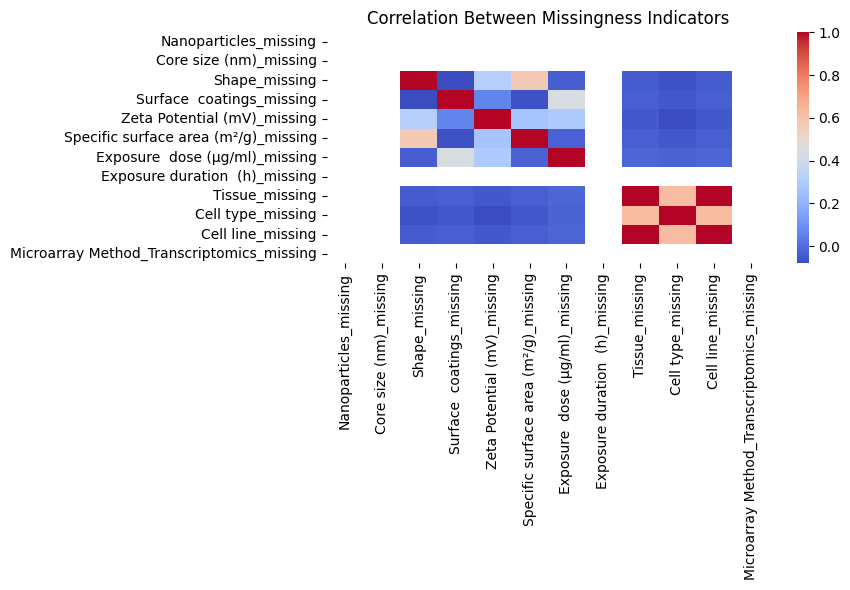

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr
from scipy.stats import chi2_contingency

# Combine the train and test data present in the kernel
df = pd.concat([df_train, df_test], axis=0).reset_index(drop=True)
target_col = TARGET_COL

rename_dict = {}
for col in df.columns:
    if 'Specific surface area' in col:
        rename_dict[col] = 'Specific surface area (m²/g)'
if rename_dict:
    df = df.rename(columns=rename_dict)

X = df.drop(columns=[target_col])  # fitur saja

# Step 1: Create a missing indicator for each feature
miss_indicators = X.isna().astype(int)
miss_indicators.columns = [col + "_missing" for col in X.columns]

# Step 2: Combine for analysis
miss_df = pd.concat([X, miss_indicators], axis=1)

# ---------------------------------------------
#  Numerical Correlation → Pearson
# ---------------------------------------------
pearson_results = []

for col_miss in miss_indicators.columns:
    for col_val in X.select_dtypes(include=["float32","float64","int64","int32"]).columns:
        # Isi missing value sementara dengan mean untuk perhitungan korelasi
        filled_val = miss_df[col_val].fillna(miss_df[col_val].mean())
        r, p = pearsonr(miss_df[col_miss], filled_val)
        pearson_results.append([col_miss, col_val, r, p])

pearson_df = pd.DataFrame(pearson_results, columns=["Feature_missing", "Correlated_with", "Pearson_r", "p_value"])
pearson_df["Significant"] = pearson_df["p_value"] < 0.05

print("\n=== Korelasi Numerik (Pearson) ===")
print(pearson_df.sort_values("p_value").head(20))

# ---------------------------------------------
#  Categorical Correlation → Chi-Square
# ---------------------------------------------
chi_results = []

cat_cols_now = X.select_dtypes(include=["object","category"]).columns.tolist()

for col_miss in miss_indicators.columns:
    for col_val in cat_cols_now:
        if miss_df[col_val].nunique() > 1:
            contingency = pd.crosstab(miss_df[col_miss], miss_df[col_val])
            chi2, p, dof, ex = chi2_contingency(contingency, correction=False)
            chi_results.append([col_miss, col_val, chi2, p])

chi_df = pd.DataFrame(chi_results, columns=["Feature_missing", "Correlated_with", "chi2", "p_value"])
chi_df["Significant"] = chi_df["p_value"] < 0.05

print("\n=== Korelasi Kategorik (Chi-Square) ===")
print(chi_df.sort_values("p_value").head(20))

# ---------------------------------------------
#  Correlation Heatmap of Missingness between Features
# ---------------------------------------------
plt.figure(figsize=(9,6))
sns.heatmap(miss_indicators.corr(), annot=False, cmap="coolwarm")
plt.title("Correlation Between Missingness Indicators")
plt.tight_layout()
plt.show()

In [ ]:
# Features with a p-value < 0.05 → strong MAR
mar_pearson = pearson_df[pearson_df["Significant"]]
mar_chi = chi_df[chi_df["Significant"]]

print("\nNumerical features with missing values ​​that are influenced by other features:")
print(mar_pearson["Feature_missing"].unique())

print("\nCategorical Features whose Missing is influenced by other featuresn:")
print(mar_chi["Feature_missing"].unique())


Numerical features with missing values ​​that are influenced by other features:
['Shape_missing' 'Surface  coatings_missing' 'Zeta Potential (mV)_missing'
 'Specific surface area (m²/g)_missing' 'Cell type_missing']

Categorical Features whose Missing is influenced by other featuresn:
['Shape_missing' 'Surface  coatings_missing' 'Zeta Potential (mV)_missing'
 'Specific surface area (m²/g)_missing' 'Exposure  dose (μg/ml)_missing']


In [ ]:
# ==================================
#  MAR / MCAR / MNAR Classification
# ==================================

missing_types = {}

# Memastikan indikator yang digunakan konsisten dengan kolom di miss_df (menggunakan akhiran '_missing')
active_indicators = [col for col in miss_df.columns if col.endswith('_missing')]

for feat in active_indicators:
    # check for a significant association (p<0.05)
    pear_sig = pearson_df[(pearson_df["Feature_missing"] == feat) &
                          (pearson_df["Significant"] == True)]
    chi_sig = chi_df[(chi_df["Feature_missing"] == feat) &
                     (chi_df["Significant"] == True)]

    # check relationship with Target
    contingency = pd.crosstab(miss_df[feat], df[target_col])
    try:
        chi2, p_target, _, _ = chi2_contingency(contingency)
    except:
        p_target = 1.0

    # ---------------------------
    # Determination of category
    # ---------------------------
    if len(pear_sig) == 0 and len(chi_sig) == 0:
        missing_types[feat] = "MCAR"
    elif p_target < 0.05:
        missing_types[feat] = "MNAR"
    else:
        missing_types[feat] = "MAR"

# Create a summary DataFrame
missing_type_df = pd.DataFrame.from_dict(missing_types, orient="index", columns=["Missing_Type"])
missing_type_df.index.name = "Feature_missing"

missing_type_df["Feature"] = missing_type_df.index.str.replace("_missing","", regex=False)
missing_type_df = missing_type_df[["Feature", "Missing_Type"]]

print("\n=== Conclusion on Missingness Type per Feature ===\n")
print(missing_type_df)


=== Conclusion on Missingness Type per Feature ===

                                                                     Feature  \
Feature_missing                                                                
Nanoparticles_missing                                          Nanoparticles   
Core size (nm)_missing                                        Core size (nm)   
Shape_missing                                                          Shape   
Surface  coatings_missing                                  Surface  coatings   
Zeta Potential (mV)_missing                              Zeta Potential (mV)   
Specific surface area (m²/g)_missing            Specific surface area (m²/g)   
Exposure  dose (μg/ml)_missing                        Exposure  dose (μg/ml)   
Exposure duration  (h)_missing                        Exposure duration  (h)   
Tissue_missing                                                        Tissue   
Cell type_missing                                                  

In [ ]:
pip install statsmodels missingno scipy

In [ ]:
# ============================================
# 2. DEFINITIONS OF 3 IMPUTATION METHODS (NUMERICAL)
#    + SEPARATE CATEGORICAL IMPUTATION
# ============================================

# Only define the numeric simple imputer here, the categorical part is handled by preprocessor in the loop
simple_numeric_imputer = SimpleImputer(strategy='median')

knn_imputer = KNNImputer(n_neighbors=5)

iibr_imputer = IterativeImputer(
    estimator=BayesianRidge(),
    max_iter=50,
    random_state=RANDOM_STATE
)

mice_imputer = IterativeImputer(
    estimator=RandomForestRegressor(
        n_estimators=100,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    max_iter=10,
    random_state=RANDOM_STATE
)

imputers = {
    "SIMPLE": simple_numeric_imputer, # Changed from ColumnTransformer to just SimpleImputer for numeric
    "KNN": knn_imputer,
    "IIBR": iibr_imputer,
    "MICE": mice_imputer
}

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
import numpy as np # Ensure numpy is imported for np.logspace

# ============================================
# 3. DEFINISI 5 CLASSIFIER + PARAMETER TUNING
# ============================================
models_param = {
    "RandomForest": (
        RandomForestClassifier(
            random_state=RANDOM_STATE,
            n_jobs=-1,
            #class_weight="balanced"
        ),
        {
            "clf__n_estimators": [200, 400, 600],
            "clf__max_depth": [None, 10,20],
            "clf__min_samples_split": [2,5],
            "clf__min_samples_leaf": [1,2,4],
            "clf__max_features": ["sqrt", "log2"]
        }
    ),
    "DecisionTree": (
        DecisionTreeClassifier(
            random_state=RANDOM_STATE,
            #class_weight="balanced"
        ),
        {
            "clf__max_depth": [None, 5, 10, 20],
            "clf__min_samples_split": [2, 5, 10]
        }
    ),
    "SVM": (
        SVC(
            probability=True,
            random_state=RANDOM_STATE,
            #class_weight="balanced"
        ),
        {
            "clf__C": [0.1, 1, 10, 100],
            "clf__gamma": ["scale", "auto"],
            "clf__kernel": ["linear", "rbf"]
        }
    ),
    "NaiveBayes": (
        GaussianNB(), # Corrected: GaussianNB() takes no positional arguments for parameter tuning
        {
            'clf__var_smoothing': np.logspace(-12, -6, 100)
        }
    ),
    "ANN": (
        MLPClassifier(
            max_iter=500,
            random_state=RANDOM_STATE
        ),
        {
            "clf__hidden_layer_sizes": [(50,), (100,), (50, 50)],
            "clf__activation": ["relu", "tanh"],
            "clf__alpha": [0.0001, 0.001]
        }
    )
}

In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score
from sklearn.preprocessing import label_binarize

# ============================================
# 4. FUNCTION TO CALCULATE EVALUATION METRICS
# ============================================
def compute_metrics(y_true, y_pred, y_proba=None):
    classes = np.unique(y_true)
    n_classes = len(classes)

    # Initialize all metrics
    acc = np.nan
    prec = np.nan
    sen = np.nan
    f1 = np.nan
    spec = np.nan
    auc = np.nan
    error_rate = 1 - accuracy_score(y_true, y_pred) # Default error rate
    fpr = np.nan
    fnr = np.nan

    # Accuracy
    acc = accuracy_score(y_true, y_pred)

    # Precision, Sensitivity (Recall), F1 weighted
    prec = precision_score(y_true, y_pred, average="weighted", zero_division=0)
    sen = recall_score(y_true, y_pred, average="weighted", zero_division=0)
    f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)

    # Specificity and Diagnostic Error Metrics for binary classification
    cm = confusion_matrix(y_true, y_pred, labels=classes)
    if n_classes == 2:
        if POS_LABEL in classes and NEG_LABEL in classes:
            cm = confusion_matrix(y_true, y_pred, labels=[NEG_LABEL, POS_LABEL])

        tn, fp, fn, tp = cm.ravel()
        spec = tn / (tn + fp) if (tn + fp) > 0 else 0
        error_rate = (fp + fn) / (tp + tn + fp + fn) if (tp + tn + fp + fn) > 0 else 0
        fpr = fp / (fp + tn) if (fp + tn) > 0 else 0
        fnr = fn / (fn + tp) if (fn + tp) > 0 else 0

    # AUC
    if y_proba is not None:
        try:
            if n_classes == 2:
                if POS_LABEL in classes:
                    pos_label_idx = list(classes).index(POS_LABEL)
                    y_true_bin = (y_true == POS_LABEL).astype(int)
                    auc = roc_auc_score(y_true_bin, y_proba[:, pos_label_idx])
                else:
                    y_true_bin = label_binarize(y_true, classes=classes)[:, 0]
                    auc = roc_auc_score(y_true_bin, y_proba[:, 1])
            else:
                y_true_bin = label_binarize(y_true, classes=classes)
                auc = roc_auc_score(y_true_bin, y_proba, multi_class="ovr", average="weighted")
        except Exception as e:
            auc = np.nan

    return {
        "Accuracy": acc,
        "Precision": prec,
        "Sensitivity": sen,
        "F1": f1,
        "Specificity": spec,
        "AUC": auc,
        "Error_Rate": error_rate,
        "FPR": fpr,
        "FNR": fnr
    }

In [ ]:
import warnings
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import RandomizedSearchCV
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import accuracy_score

warnings.filterwarnings("ignore", category=ConvergenceWarning)

best_models = {}   # (Imputation, Classifier) → best estimator
results = []

for imp_name, imp in imputers.items():
    print(f"\n====================================")
    print(f"=== Imputation Methods: {imp_name} ===")
    print(f"======================================")

    # Numeric pipeline: imputasi + scaling
    numeric_transformer = SkPipeline(steps=[
        ("imputer", imp),
        ("scaler", StandardScaler())
    ])

    # Categorical pipeline: mode + OneHot (dense)
    categorical_transformer = SkPipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ])

    preprocessor = ColumnTransformer(
        transformers=[
            ("num", numeric_transformer, numeric_features),
            ("cat", categorical_transformer, categorical_features)
        ]
    )

    for model_name, (model, param_grid) in models_param.items():
        print(f"\n--> Training: Imputasi={imp_name}, Classifier={model_name}")

        pipe = SkPipeline(steps=[
            ("preprocess", preprocessor),
            ("clf", model)
        ])

        try:
            if len(param_grid) > 0:
                search = RandomizedSearchCV(
                    estimator=pipe,
                    param_distributions=param_grid,
                    n_iter=5,
                    cv=3,
                    scoring="roc_auc",
                    n_jobs=-1,
                    random_state=RANDOM_STATE,
                    error_score="raise"
                )
                search.fit(X_train, y_train)
                best_model = search.best_estimator_
                best_params = search.best_params_
                best_cv_score = search.best_score_
            else:
                search = None
                best_model = pipe.fit(X_train, y_train)
                best_params = {}
                best_cv_score = np.nan

            best_models[(imp_name, model_name)] = best_model

            y_pred = best_model.predict(X_test)
            if hasattr(best_model.named_steps["clf"], "predict_proba"):
                y_proba = best_model.predict_proba(X_test)
            else:
                y_proba = None

            metrics = compute_metrics(y_test, y_pred, y_proba)

            results.append({
                "Imputation": imp_name,
                "Classifier": model_name,
                "BestParams": best_params,
                "CV_ROC_AUC": best_cv_score,
                "Accuracy": metrics["Accuracy"],
                "Precision": metrics["Precision"],
                "Sensitivity": metrics["Sensitivity"],
                "F1": metrics["F1"],
                "Specificity": metrics["Specificity"],
                "AUC": metrics["AUC"],
                "Error_Rate": metrics["Error_Rate"],
                "FPR": metrics["FPR"],
                "FNR": metrics["FNR"]
            })

            print(f"   ✔ Done: {imp_name} + {model_name} (Accuracy={metrics['Accuracy']:.4f}, AUC={metrics['AUC']:.4f})")

        except Exception as e:
            print(f" Error in combination{imp_name} + {model_name}: {e}")
            best_models[(imp_name, model_name)] = None
            continue

results_df = pd.DataFrame(results)
results_df.to_excel("evaluation_results.xlsx", index=False)
print("\nFile 'evaluation_results.xlsx' successfully saved.")
print("Number of successful model combinations:", len(results_df))
print("Number of best_models entries:", len(best_models))
print("List of best_models keys:", list(best_models.keys()))


=== Imputation Methods: SIMPLE ===

--> Training: Imputasi=SIMPLE, Classifier=RandomForest
   ✔ Done: SIMPLE + RandomForest (Accuracy=1.0000, AUC=1.0000)

--> Training: Imputasi=SIMPLE, Classifier=DecisionTree
   ✔ Done: SIMPLE + DecisionTree (Accuracy=0.9474, AUC=1.0000)

--> Training: Imputasi=SIMPLE, Classifier=SVM
   ✔ Done: SIMPLE + SVM (Accuracy=0.7368, AUC=1.0000)

--> Training: Imputasi=SIMPLE, Classifier=NaiveBayes
   ✔ Done: SIMPLE + NaiveBayes (Accuracy=0.8421, AUC=0.7000)

--> Training: Imputasi=SIMPLE, Classifier=ANN
   ✔ Done: SIMPLE + ANN (Accuracy=0.7368, AUC=0.8111)

=== Imputation Methods: KNN ===

--> Training: Imputasi=KNN, Classifier=RandomForest
   ✔ Done: KNN + RandomForest (Accuracy=0.9474, AUC=1.0000)

--> Training: Imputasi=KNN, Classifier=DecisionTree
   ✔ Done: KNN + DecisionTree (Accuracy=0.9474, AUC=1.0000)

--> Training: Imputasi=KNN, Classifier=SVM
   ✔ Done: KNN + SVM (Accuracy=0.7368, AUC=0.9889)

--> Training: Imputasi=KNN, Classifier=NaiveBayes
   ✔

In [ ]:
from sklearn.model_selection import StratifiedKFold

# Initialize Stratified K-Fold for the outer loop
skf_outer = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)

nested_cv_results = []

print("Starting Nested Cross-Validation...")

for fold_idx, (train_index, val_index) in enumerate(skf_outer.split(X_train, y_train)):
    print(f"\n====== Outer Fold {fold_idx + 1}/10 ======")
    X_train_fold, X_val_fold = X_train.iloc[train_index], X_train.iloc[val_index]
    y_train_fold, y_val_fold = y_train.iloc[train_index], y_train.iloc[val_index]

    for imp_name, imp in imputers.items():
        for model_name, (model, param_grid) in models_param.items():
            print(f"  --> Fold {fold_idx + 1}, Imputation={imp_name}, Classifier={model_name}")

            # Numeric pipeline: imputation + scaling
            numeric_transformer = SkPipeline(steps=[
                ("imputer", imp),
                ("scaler", StandardScaler())
            ])

            # Categorical pipeline: mode + OneHot (dense)
            categorical_transformer = SkPipeline(steps=[
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
            ])

            preprocessor = ColumnTransformer(
                transformers=[
                    ("num", numeric_transformer, numeric_features),
                    ("cat", categorical_transformer, categorical_features)
                ]
            )

            pipe = SkPipeline(steps=[
                ("preprocess", preprocessor),
                ("clf", model)
            ])

            try:
                if len(param_grid) > 0:
                    search = RandomizedSearchCV(
                        estimator=pipe,
                        param_distributions=param_grid,
                        n_iter=5,
                        cv=3, # Inner CV folds
                        scoring="roc_auc",
                        n_jobs=-1,
                        random_state=RANDOM_STATE,
                        error_score="raise"
                    )
                    search.fit(X_train_fold, y_train_fold)
                    best_estimator_inner = search.best_estimator_
                    best_params_inner = search.best_params_
                    best_cv_score_inner = search.best_score_
                else:
                    best_estimator_inner = pipe.fit(X_train_fold, y_train_fold)
                    best_params_inner = {}
                    best_cv_score_inner = np.nan

                # Evaluate best model from inner CV on outer validation set
                y_pred_val = best_estimator_inner.predict(X_val_fold)
                if hasattr(best_estimator_inner.named_steps["clf"], "predict_proba"):
                    y_proba_val = best_estimator_inner.predict_proba(X_val_fold)
                else:
                    y_proba_val = None

                metrics_val = compute_metrics(y_val_fold, y_pred_val, y_proba_val)

                nested_cv_results.append({
                    "Fold": fold_idx + 1,
                    "Imputation": imp_name,
                    "Classifier": model_name,
                    "BestParams_InnerCV": best_params_inner,
                    "CV_ROC_AUC_InnerCV": best_cv_score_inner,
                    "Accuracy_OuterVal": metrics_val["Accuracy"],
                    "Precision_OuterVal": metrics_val["Precision"],
                    "Sensitivity_OuterVal": metrics_val["Sensitivity"],
                    "F1_OuterVal": metrics_val["F1"],
                    "Specificity_OuterVal": metrics_val["Specificity"],
                    "AUC_OuterVal": metrics_val["AUC"],
                    "Error_Rate_OuterVal": metrics_val["Error_Rate"],
                    "FPR_OuterVal": metrics_val["FPR"],
                    "FNR_OuterVal": metrics_val["FNR"]
                })
                print(f"    ✔ Done: (Acc={metrics_val['Accuracy']:.4f}, AUC={metrics_val['AUC']:.4f})")

            except Exception as e:
                print(f" Error pada kombinasi {imp_name} + {model_name} di Fold {fold_idx + 1}: {e}")
                nested_cv_results.append({
                    "Fold": fold_idx + 1,
                    "Imputation": imp_name,
                    "Classifier": model_name,
                    "BestParams_InnerCV": None,
                    "CV_ROC_AUC_InnerCV": np.nan,
                    "Accuracy_OuterVal": np.nan,
                    "Precision_OuterVal": np.nan,
                    "Sensitivity_OuterVal": np.nan,
                    "F1_OuterVal": np.nan,
                    "Specificity_OuterVal": np.nan,
                    "AUC_OuterVal": np.nan,
                    "Error_Rate_OuterVal": np.nan,
                    "FPR_OuterVal": np.nan,
                    "FNR_OuterVal": np.nan
                })
                continue

nested_cv_df = pd.DataFrame(nested_cv_results)

# Calculate mean and std deviation for each metric across folds
summary_nested_cv = nested_cv_df.groupby(['Imputation', 'Classifier']).agg({
    'Accuracy_OuterVal': ['mean', 'std'],
    'Precision_OuterVal': ['mean', 'std'],
    'Sensitivity_OuterVal': ['mean', 'std'],
    'F1_OuterVal': ['mean', 'std'],
    'Specificity_OuterVal': ['mean', 'std'],
    'AUC_OuterVal': ['mean', 'std'],
    'Error_Rate_OuterVal': ['mean', 'std'],
    'FPR_OuterVal': ['mean', 'std'],
    'FNR_OuterVal': ['mean', 'std']
}).reset_index()

# Flatten multi-level columns
summary_nested_cv.columns = ['_'.join(col).strip() if isinstance(col, tuple) else col for col in summary_nested_cv.columns.values]
summary_nested_cv.rename(columns={'Imputation_': 'Imputation', 'Classifier_': 'Classifier'}, inplace=True)

print("\nNested Cross-Validation Summary:")
display(summary_nested_cv)

nested_cv_df.to_excel("nested_cv_detailed_results.xlsx", index=False)
summary_nested_cv.to_excel("nested_cv_summary_results.xlsx", index=False)
print("Detailed Nested CV results saved to 'nested_cv_summary_results.xlsx'.")
print("Summary Nested CV results saved to 'nested_cv_summary_results.xlsx'.")

Starting Nested Cross-Validation...

====== Outer Fold 1/10 ======
  --> Fold 1, Imputation=SIMPLE, Classifier=RandomForest
    ✔ Done: (Acc=0.9130, AUC=0.9615)
  --> Fold 1, Imputation=SIMPLE, Classifier=DecisionTree
    ✔ Done: (Acc=0.8261, AUC=0.9000)
  --> Fold 1, Imputation=SIMPLE, Classifier=SVM
    ✔ Done: (Acc=0.9130, AUC=0.9385)
  --> Fold 1, Imputation=SIMPLE, Classifier=NaiveBayes
    ✔ Done: (Acc=0.6087, AUC=0.7385)
  --> Fold 1, Imputation=SIMPLE, Classifier=ANN
    ✔ Done: (Acc=0.6087, AUC=0.7846)
  --> Fold 1, Imputation=KNN, Classifier=RandomForest
    ✔ Done: (Acc=0.9130, AUC=0.9538)
  --> Fold 1, Imputation=KNN, Classifier=DecisionTree
    ✔ Done: (Acc=0.8696, AUC=0.8769)
  --> Fold 1, Imputation=KNN, Classifier=SVM
    ✔ Done: (Acc=0.9130, AUC=0.9154)
  --> Fold 1, Imputation=KNN, Classifier=NaiveBayes
    ✔ Done: (Acc=0.6087, AUC=0.7385)
  --> Fold 1, Imputation=KNN, Classifier=ANN
    ✔ Done: (Acc=0.6087, AUC=0.7308)
  --> Fold 1, Imputation=IIBR, Classifier=Random

,Imputation,Classifier,Accuracy_OuterVal_mean,Accuracy_OuterVal_std,Precision_OuterVal_mean,Precision_OuterVal_std,Sensitivity_OuterVal_mean,Sensitivity_OuterVal_std,F1_OuterVal_mean,F1_OuterVal_std,Specificity_OuterVal_mean,Specificity_OuterVal_std,AUC_OuterVal_mean,AUC_OuterVal_std,Error_Rate_OuterVal_mean,Error_Rate_OuterVal_std,FPR_OuterVal_mean,FPR_OuterVal_std,FNR_OuterVal_mean,FNR_OuterVal_std
0,IIBR,ANN,0.653755,0.073403,0.698101,0.108770,0.653755,0.073403,0.640456,0.068246,0.657692,0.198987,0.794338,0.061775,0.346245,0.073403,0.342308,0.198987,0.358889,0.266566
1,IIBR,DecisionTree,0.903162,0.081111,0.913284,0.071905,0.903162,0.081111,0.902896,0.081502,0.884615,0.121626,0.936581,0.066616,0.096838,0.081111,0.115385,0.121626,0.072222,0.086424
2,IIBR,NaiveBayes,0.675494,0.065299,0.766577,0.079944,0.675494,0.065299,0.660025,0.071270,0.533333,0.179609,0.753793,0.077216,0.324506,0.065299,0.466667,0.179609,0.137778,0.211740
3,IIBR,RandomForest,0.911067,0.051400,0.918758,0.045593,0.911067,0.051400,0.910675,0.051642,0.915385,0.092094,0.970855,0.042626,0.088933,0.051400,0.084615,0.092094,0.095556,0.081515
4,IIBR,SVM,0.858103,0.096485,0.863125,0.098668,0.858103,0.096485,0.856573,0.098286,0.892308,0.082690,0.872607,0.111599,0.141897,0.096485,0.107692,0.082690,0.187778,0.160542
5,KNN,ANN,0.653557,0.071475,0.691692,0.099986,0.653557,0.071475,0.641238,0.066571,0.665385,0.191923,0.784124,0.063454,0.346443,0.071475,0.334615,0.191923,0.370000,0.251855
6,KNN,DecisionTree,0.880830,0.073652,0.888421,0.071614,0.880830,0.073652,0.880781,0.073561,0.860897,0.086850,0.913098,0.074315,0.119170,0.073652,0.139103,0.086850,0.094444,0.105181
7,KNN,NaiveBayes,0.675494,0.065299,0.766577,0.079944,0.675494,0.065299,0.660025,0.071270,0.533333,0.179609,0.759263,0.063932,0.324506,0.065299,0.466667,0.179609,0.137778,0.211740
8,KNN,RandomForest,0.893478,0.059504,0.900372,0.054353,0.893478,0.059504,0.892886,0.059904,0.900000,0.089192,0.965812,0.049858,0.106522,0.059504,0.100000,0.089192,0.116667,0.098166
9,KNN,SVM,0.827273,0.117290,0.829779,0.118930,0.827273,0.117290,0.824227,0.122143,0.869231,0.072976,0.856624,0.123104,0.172727,0.117290,0.130769,0.072976,0.227778,0.207027


Detailed Nested CV results saved to 'nested_cv_summary_results.xlsx'.
Summary Nested CV results saved to 'nested_cv_summary_results.xlsx'.


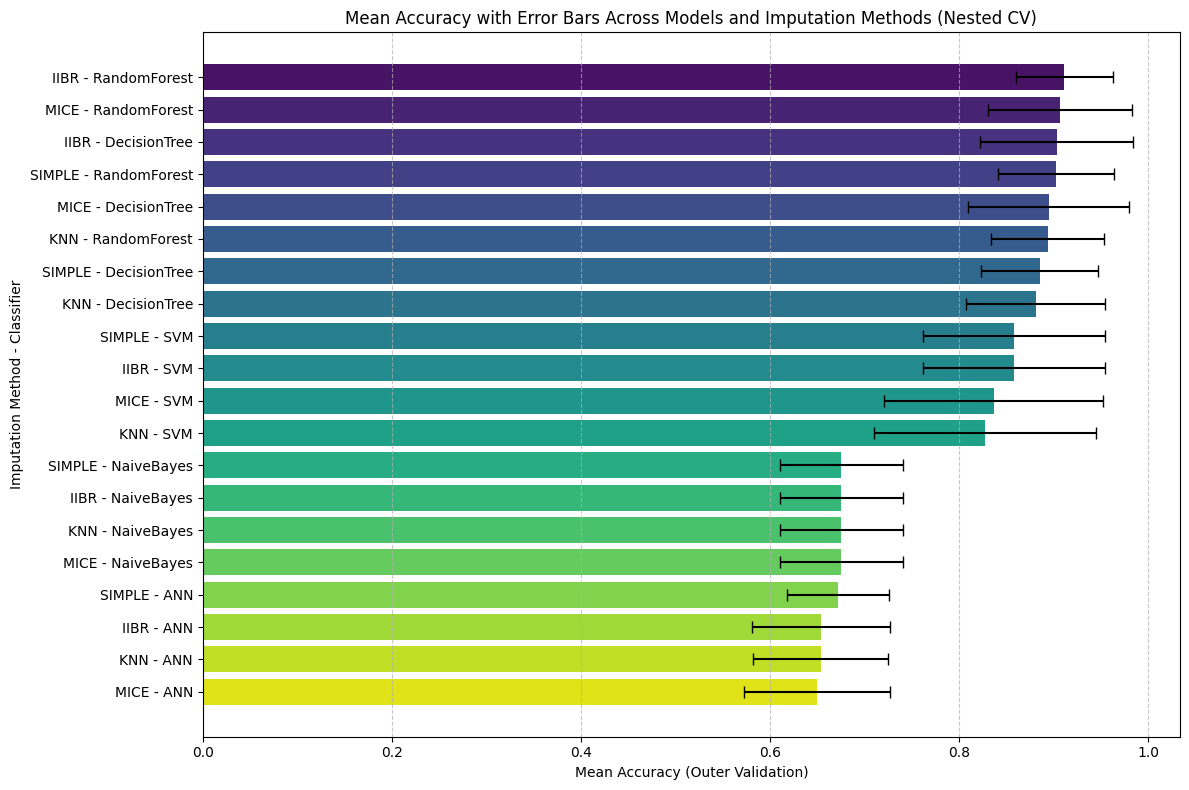

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a combined label for better readability on the y-axis
summary_nested_cv['Model_Combination'] = summary_nested_cv['Imputation'] + ' - ' + summary_nested_cv['Classifier']

# Sort the data by mean accuracy for better visualization
plot_data = summary_nested_cv.sort_values(by='Accuracy_OuterVal_mean', ascending=False).reset_index(drop=True)

plt.figure(figsize=(12, 8))
plt.barh(
    y=plot_data['Model_Combination'],
    width=plot_data['Accuracy_OuterVal_mean'],
    xerr=plot_data['Accuracy_OuterVal_std'], # Add standard deviation as error bars
    capsize=4, # Size of the caps on the error bars
    color=sns.color_palette('viridis', n_colors=len(plot_data))
)

plt.xlabel('Mean Accuracy (Outer Validation)')
plt.ylabel('Imputation Method - Classifier')
plt.title('Mean Accuracy with Error Bars Across Models and Imputation Methods (Nested CV)')
plt.gca().invert_yaxis() # Invert y-axis to have the highest accuracy at the top
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import ParameterSampler

for model_name, (model, param_grid) in models_param.items():
    print(f"\n--- Model: {model_name} ---")
    if len(param_grid) > 0:
        # ParameterSampler allows us to get the actual sampled parameters

        dummy_pipe = SkPipeline(steps=[("clf", model)])
        param_sampler = list(ParameterSampler(
            param_distributions=param_grid,
            n_iter=5, # Requesting 5 samples
            random_state=RANDOM_STATE # Ensure reproducibility for sampling
        ))
        for i, params in enumerate(param_sampler):
            print(f" Combination {i+1}: {params}")
    else:
        print("No `param_grid` is defined for this model.")


--- Model: RandomForest ---
 Combination 1: {'clf__n_estimators': 600, 'clf__min_samples_split': 5, 'clf__min_samples_leaf': 1, 'clf__max_features': 'sqrt', 'clf__max_depth': 20}
 Combination 2: {'clf__n_estimators': 400, 'clf__min_samples_split': 5, 'clf__min_samples_leaf': 2, 'clf__max_features': 'sqrt', 'clf__max_depth': None}
 Combination 3: {'clf__n_estimators': 400, 'clf__min_samples_split': 5, 'clf__min_samples_leaf': 1, 'clf__max_features': 'sqrt', 'clf__max_depth': None}
 Combination 4: {'clf__n_estimators': 600, 'clf__min_samples_split': 5, 'clf__min_samples_leaf': 2, 'clf__max_features': 'sqrt', 'clf__max_depth': 20}
 Combination 5: {'clf__n_estimators': 600, 'clf__min_samples_split': 2, 'clf__min_samples_leaf': 2, 'clf__max_features': 'log2', 'clf__max_depth': 10}

--- Model: DecisionTree ---
 Combination 1: {'clf__min_samples_split': 5, 'clf__max_depth': 20}
 Combination 2: {'clf__min_samples_split': 2, 'clf__max_depth': 20}
 Combination 3: {'clf__min_samples_split': 2, '

In [ ]:
from sklearn.model_selection import ParameterSampler
import pandas as pd

sampled_params_list = []

print("\nCollecting 5 sampled hyperparameter combinations for each model...")

for model_name, (model, param_grid) in models_param.items():
    if len(param_grid) > 0:
        dummy_pipe = SkPipeline(steps=[("clf", model)])
        param_sampler = list(ParameterSampler(
            param_distributions=param_grid,
            n_iter=5, # Requesting 5 samples
            random_state=RANDOM_STATE # Ensure reproducibility for sampling
        ))
        for i, params in enumerate(param_sampler):
            # Prepend model name and combination number to each dictionary
            sampled_params_list.append({
                "Model": model_name,
                "Combination": i + 1,
                **params
            })
    else:
        sampled_params_list.append({
            "Model": model_name,
            "Combination": 1, # Even if no params, record it
            "Note": "No `param_grid` is defined for this model."
        })

# Convert the list of sampled parameters to a DataFrame
sampled_params_df = pd.DataFrame(sampled_params_list)

# Save the DataFrame to an Excel file
output_filename = "sampled_hyperparameters.xlsx"
sampled_params_df.to_excel(output_filename, index=False)

print(f"\n5 sampled hyperparameter combinations for each model saved to '{output_filename}'.")
display(sampled_params_df.head(5))



5 sampled hyperparameter combinations for each model saved to 'sampled_hyperparameters.xlsx'.


,Model,Combination,clf__n_estimators,clf__min_samples_split,clf__min_samples_leaf,clf__max_features,clf__max_depth,clf__kernel,clf__gamma,clf__C,clf__var_smoothing,clf__hidden_layer_sizes,clf__alpha,clf__activation
0,RandomForest,1,600.0,5.0,1.0,sqrt,20.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,RandomForest,2,400.0,5.0,2.0,sqrt,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,RandomForest,3,400.0,5.0,1.0,sqrt,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,RandomForest,4,600.0,5.0,2.0,sqrt,20.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,RandomForest,5,600.0,2.0,2.0,log2,10.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
import warnings
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import RandomizedSearchCV
from sklearn.exceptions import ConvergenceWarning
import pandas as pd
from sklearn.impute import SimpleImputer
import numpy as np

warnings.filterwarnings("ignore", category=ConvergenceWarning)

test_results = []

print(f"\n===================================================")
print(f"=== Model Evaluation on Test Data with Imputation ===")
print(f"\n===================================================")

for imp_name, imp in imputers.items():
    print(f"\n====================================")
    print(f"=== Imputation Methods: {imp_name} ===")
    print(f"\n====================================")

    # Numeric pipeline: imputation + scaling
    numeric_transformer = SkPipeline(steps=[
        ("imputer", imp),
        ("scaler", StandardScaler())
    ])

    # Categorical pipeline: mode + OneHot (dense)
    categorical_transformer = SkPipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ])

    preprocessor = ColumnTransformer(
        transformers=[
            ("num", numeric_transformer, numeric_features),
            ("cat", categorical_transformer, categorical_features)
        ]
    )

    for model_name, (model, param_grid) in models_param.items():
        print(f"\n--> Training and Evaluating: Imputation={imp_name}, Classifier={model_name} on Test Data")

        pipe = SkPipeline(steps=[
            ("preprocess", preprocessor),
            ("clf", model)
        ])

        try:
            best_model = None
            best_params = {}
            best_cv_score = np.nan

            if len(param_grid) > 0:
                search = RandomizedSearchCV(
                    estimator=pipe,
                    param_distributions=param_grid,
                    n_iter=5,
                    cv=3,
                    scoring="roc_auc",
                    n_jobs=-1,
                    random_state=RANDOM_STATE,
                    error_score="raise"
                )
                search.fit(X_train, y_train)
                best_model = search.best_estimator_
                best_params = search.best_params_
                best_cv_score = search.best_score_
            else:
                best_model = pipe.fit(X_train, y_train)

            # Predict on the test data
            y_pred_test = best_model.predict(X_test)
            if hasattr(best_model.named_steps["clf"], "predict_proba"):
                y_proba_test = best_model.predict_proba(X_test)
            else:
                y_proba_test = None

            # Compute metrics on the test data
            metrics_test = compute_metrics(y_test, y_pred_test, y_proba_test)

            test_results.append({
                "Imputation": imp_name,
                "Classifier": model_name,
                "BestParams": best_params,
                "CV_ROC_AUC": best_cv_score,
                "Accuracy": metrics_test["Accuracy"],
                "Precision": metrics_test["Precision"],
                "Sensitivity": metrics_test["Sensitivity"],
                "F1": metrics_test["F1"],
                "Specificity": metrics_test["Specificity"],
                "AUC": metrics_test["AUC"],
                "Error_Rate": metrics_test["Error_Rate"],
                "FPR": metrics_test["FPR"],
                "FNR": metrics_test["FNR"]
            })

            print(f"   ✔ Done: {imp_name} + {model_name} (Accuracy={metrics_test['Accuracy']:.4f}, AUC={metrics_test['AUC']:.4f})")

        except Exception as e:
            print(f" Error pada kombinasi {imp_name} + {model_name} saat evaluasi (Test Data): {e}")
            test_results.append({
                "Imputation": imp_name,
                "Classifier": model_name,
                "BestParams": None,
                "CV_ROC_AUC": np.nan,
                "Accuracy": np.nan,
                "Precision": np.nan,
                "Sensitivity": np.nan,
                "F1": np.nan,
                "Specificity": np.nan,
                "AUC": np.nan,
                "Error_Rate": np.nan,
                "FPR": np.nan,
                "FNR": np.nan
            })
            continue

# Convert results to DataFrame
test_results_df = pd.DataFrame(test_results)

# Format relevant columns as percentages (removed MCC from percentage columns list)
percentage_cols = [
    "Accuracy", "Precision", "Sensitivity", "F1", "Specificity",
    "AUC", "Error_Rate", "FPR", "FNR"
]

for col in percentage_cols:
    if col in test_results_df.columns:
        test_results_df[col] = pd.to_numeric(test_results_df[col], errors='coerce')
        test_results_df[col] = test_results_df[col].apply(lambda x: f"{x:.2%}" if pd.notna(x) else x)

print("\nModel Performance Metrics on Test Data (with Imputation):")
display(test_results_df)

# Save the test results to an Excel file
test_results_df.to_excel("model_evaluation_results_on_test_data_with_imputation.xlsx", index=False)
print("\nTest performance results saved to 'model_evaluation_results_on_test_data_with_imputation.xlsx'.")


=== Model Evaluation on Test Data with Imputation ===


=== Imputation Methods: SIMPLE ===


--> Training and Evaluating: Imputation=SIMPLE, Classifier=RandomForest on Test Data
   ✔ Done: SIMPLE + RandomForest (Accuracy=1.0000, AUC=1.0000)

--> Training and Evaluating: Imputation=SIMPLE, Classifier=DecisionTree on Test Data
   ✔ Done: SIMPLE + DecisionTree (Accuracy=0.9474, AUC=1.0000)

--> Training and Evaluating: Imputation=SIMPLE, Classifier=SVM on Test Data
   ✔ Done: SIMPLE + SVM (Accuracy=0.7368, AUC=1.0000)

--> Training and Evaluating: Imputation=SIMPLE, Classifier=NaiveBayes on Test Data
   ✔ Done: SIMPLE + NaiveBayes (Accuracy=0.8421, AUC=0.7000)

--> Training and Evaluating: Imputation=SIMPLE, Classifier=ANN on Test Data
   ✔ Done: SIMPLE + ANN (Accuracy=0.7368, AUC=0.8111)

=== Imputation Methods: KNN ===


--> Training and Evaluating: Imputation=KNN, Classifier=RandomForest on Test Data
   ✔ Done: KNN + RandomForest (Accuracy=0.9474, AUC=1.0000)

--> Training and Evaluat

,Imputation,Classifier,BestParams,CV_ROC_AUC,Accuracy,Precision,Sensitivity,F1,Specificity,AUC,Error_Rate,FPR,FNR
0,SIMPLE,RandomForest,"{'clf__n_estimators': 400, 'clf__min_samples_s...",0.748547,100.00%,100.00%,100.00%,100.00%,100.00%,100.00%,0.00%,0.00%,0.00%
1,SIMPLE,DecisionTree,"{'clf__min_samples_split': 10, 'clf__max_depth...",0.828609,94.74%,95.26%,94.74%,94.74%,100.00%,100.00%,5.26%,0.00%,10.00%
2,SIMPLE,SVM,"{'clf__kernel': 'rbf', 'clf__gamma': 'scale', ...",0.644138,73.68%,83.08%,73.68%,72.16%,100.00%,100.00%,26.32%,0.00%,50.00%
3,SIMPLE,NaiveBayes,{'clf__var_smoothing': 1.6297508346206469e-09},0.575097,84.21%,88.16%,84.21%,83.95%,100.00%,70.00%,15.79%,0.00%,30.00%
4,SIMPLE,ANN,"{'clf__hidden_layer_sizes': (50, 50), 'clf__al...",0.631298,73.68%,83.08%,73.68%,72.16%,100.00%,81.11%,26.32%,0.00%,50.00%
5,KNN,RandomForest,"{'clf__n_estimators': 400, 'clf__min_samples_s...",0.741279,94.74%,95.22%,94.74%,94.71%,88.89%,100.00%,5.26%,11.11%,0.00%
6,KNN,DecisionTree,"{'clf__min_samples_split': 10, 'clf__max_depth...",0.783430,94.74%,95.26%,94.74%,94.74%,100.00%,100.00%,5.26%,0.00%,10.00%
7,KNN,SVM,"{'clf__kernel': 'rbf', 'clf__gamma': 'scale', ...",0.631541,73.68%,83.08%,73.68%,72.16%,100.00%,98.89%,26.32%,0.00%,50.00%
8,KNN,NaiveBayes,{'clf__var_smoothing': 1.6297508346206469e-09},0.579942,84.21%,88.16%,84.21%,83.95%,100.00%,70.00%,15.79%,0.00%,30.00%
9,KNN,ANN,"{'clf__hidden_layer_sizes': (50, 50), 'clf__al...",0.659763,73.68%,83.08%,73.68%,72.16%,100.00%,84.44%,26.32%,0.00%,50.00%



Test performance results saved to 'model_evaluation_results_on_test_data_with_imputation.xlsx'.


In [ ]:
# Add a 'Best_Metric' column to each DataFrame
best_auc_models['Best_Metric'] = 'AUC'
best_accuracy_models['Best_Metric'] = 'Accuracy'

# Concatenate the DataFrames
all_best_models = pd.concat([best_auc_models, best_accuracy_models])

# Drop duplicate rows (e.g., if a model is best for multiple metrics)
all_best_models = all_best_models.drop_duplicates().reset_index(drop=True)

# Reorder columns to have 'Best_Metric' first, then 'Imputation', 'Classifier'
all_best_models = all_best_models[['Best_Metric', 'Imputation', 'Classifier'] + [col for col in all_best_models.columns if col not in ['Best_Metric', 'Imputation', 'Classifier']]]

# Save the concatenated DataFrame to an Excel file
output_filename = "best_models_nested_cv_summary.xlsx"
all_best_models.to_excel(output_filename, index=False)

print(f"\nSummary of best models saved to '{output_filename}'.")
display(all_best_models)

In [ ]:
display(all_best_models)

,Best_Metric,Imputation,Classifier,Accuracy_OuterVal_mean,Accuracy_OuterVal_std,Precision_OuterVal_mean,Precision_OuterVal_std,Sensitivity_OuterVal_mean,Sensitivity_OuterVal_std,F1_OuterVal_mean,...,Specificity_OuterVal_std,AUC_OuterVal_mean,AUC_OuterVal_std,Error_Rate_OuterVal_mean,Error_Rate_OuterVal_std,FPR_OuterVal_mean,FPR_OuterVal_std,FNR_OuterVal_mean,FNR_OuterVal_std,Model_Combination
0,AUC,IIBR,RandomForest,0.911067,0.051400,0.918758,0.045593,0.911067,0.051400,0.910675,...,0.092094,0.970855,0.042626,0.088933,0.051400,0.084615,0.092094,0.095556,0.081515,IIBR - RandomForest
1,AUC,MICE,RandomForest,0.906917,0.075986,0.913568,0.066977,0.906917,0.075986,0.906487,...,0.113518,0.970085,0.049433,0.093083,0.075986,0.092308,0.113518,0.095556,0.081515,MICE - RandomForest
2,AUC,SIMPLE,RandomForest,0.902372,0.061482,0.907941,0.057579,0.902372,0.061482,0.902009,...,0.092094,0.967607,0.048321,0.097628,0.061482,0.084615,0.092094,0.115556,0.079986,SIMPLE - RandomForest
3,Accuracy,IIBR,RandomForest,0.911067,0.051400,0.918758,0.045593,0.911067,0.051400,0.910675,...,0.092094,0.970855,0.042626,0.088933,0.051400,0.084615,0.092094,0.095556,0.081515,IIBR - RandomForest
4,Accuracy,MICE,RandomForest,0.906917,0.075986,0.913568,0.066977,0.906917,0.075986,0.906487,...,0.113518,0.970085,0.049433,0.093083,0.075986,0.092308,0.113518,0.095556,0.081515,MICE - RandomForest
5,Accuracy,IIBR,DecisionTree,0.903162,0.081111,0.913284,0.071905,0.903162,0.081111,0.902896,...,0.121626,0.936581,0.066616,0.096838,0.081111,0.115385,0.121626,0.072222,0.086424,IIBR - DecisionTree



=== Confusion Matrices on Test Data ===

--- Classifier: ('SIMPLE', 'RandomForest') ---


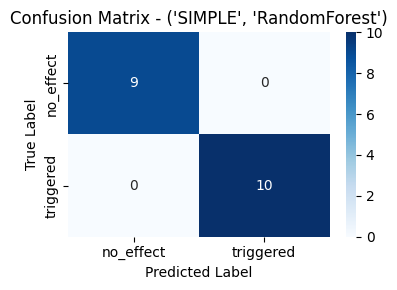


--- Classifier: ('SIMPLE', 'DecisionTree') ---


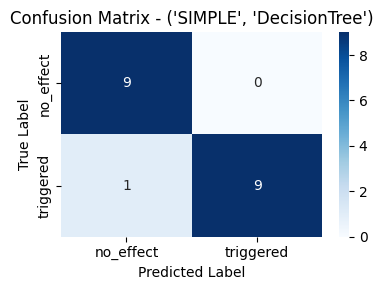


--- Classifier: ('SIMPLE', 'SVM') ---


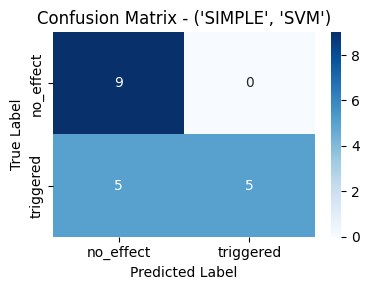


--- Classifier: ('SIMPLE', 'NaiveBayes') ---


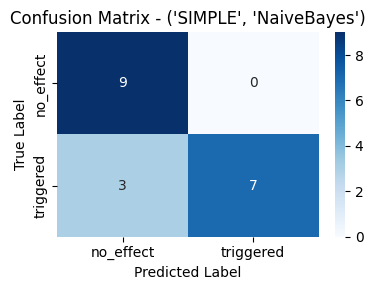


--- Classifier: ('SIMPLE', 'ANN') ---


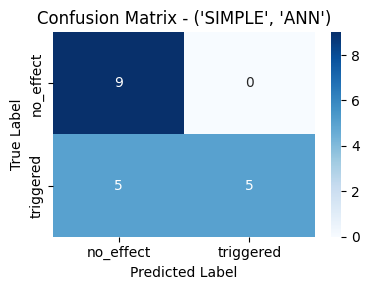


--- Classifier: ('KNN', 'RandomForest') ---


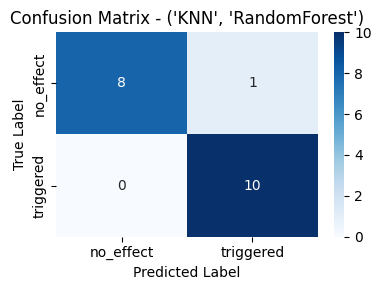


--- Classifier: ('KNN', 'DecisionTree') ---


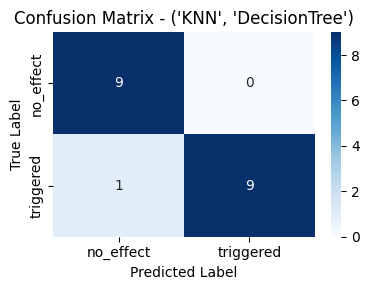


--- Classifier: ('KNN', 'SVM') ---


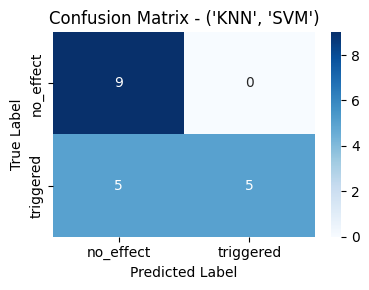


--- Classifier: ('KNN', 'NaiveBayes') ---


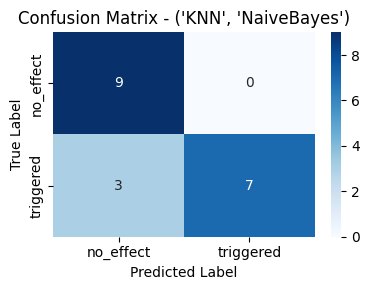


--- Classifier: ('KNN', 'ANN') ---


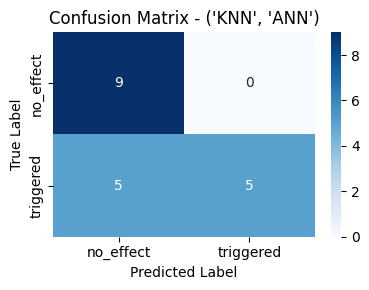


--- Classifier: ('IIBR', 'RandomForest') ---


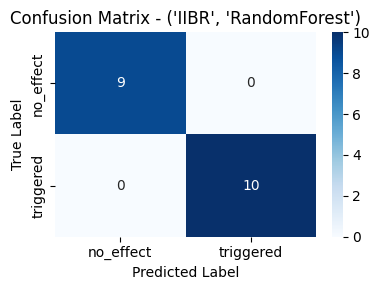


--- Classifier: ('IIBR', 'DecisionTree') ---


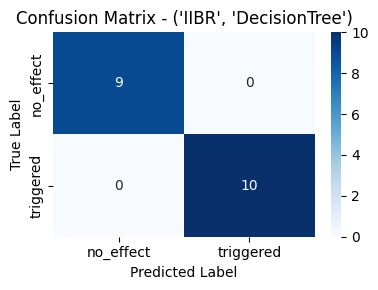


--- Classifier: ('IIBR', 'SVM') ---


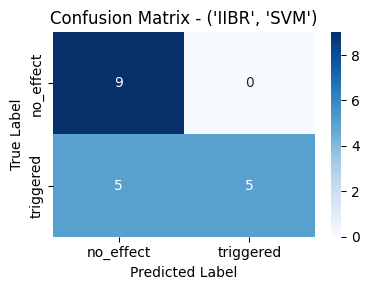


--- Classifier: ('IIBR', 'NaiveBayes') ---


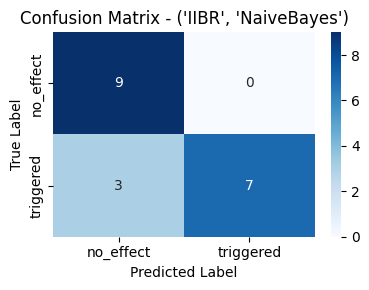


--- Classifier: ('IIBR', 'ANN') ---


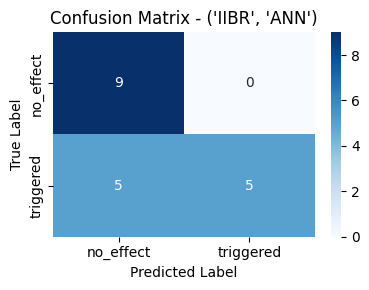


--- Classifier: ('MICE', 'RandomForest') ---


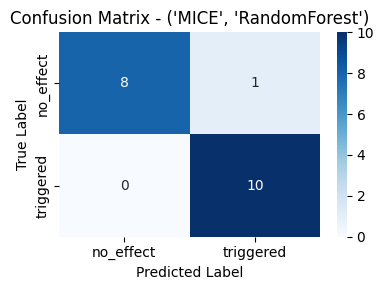


--- Classifier: ('MICE', 'DecisionTree') ---


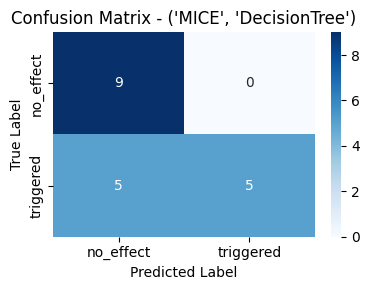


--- Classifier: ('MICE', 'SVM') ---


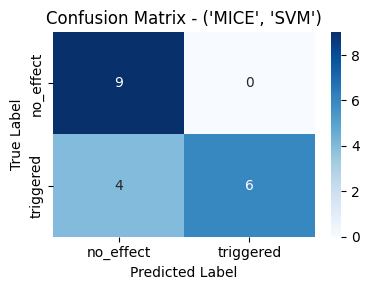


--- Classifier: ('MICE', 'NaiveBayes') ---


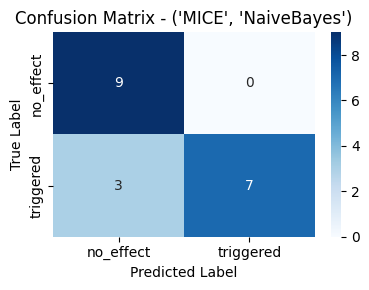


--- Classifier: ('MICE', 'ANN') ---


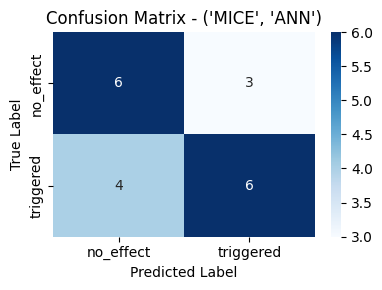

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming best_models contains the fitted pipelines and X_test, y_test are available

print("\n=========================================")
print("=== Confusion Matrices on Test Data ===")
print("=========================================")

for model_name, best_model in best_models.items():
    print(f"\n--- Classifier: {model_name} ---")

    # Predict on the test data
    y_pred_test = best_model.predict(X_test)

    # Get unique classes, ensuring consistent order for confusion matrix
    classes = sorted(y_test.unique())

    # Calculate Confusion Matrix
    cm = confusion_matrix(y_test, y_pred_test, labels=classes)

    # Display Confusion Matrix using seaborn and matplotlib
    plt.figure(figsize=(4, 3))
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=classes,
        yticklabels=classes
    )
    plt.title(f'Confusion Matrix - {model_name}')
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.tight_layout()
    plt.show()

In [ ]:
display(summary_nested_cv)

,Imputation,Classifier,Accuracy_OuterVal_mean,Accuracy_OuterVal_std,Precision_OuterVal_mean,Precision_OuterVal_std,Sensitivity_OuterVal_mean,Sensitivity_OuterVal_std,F1_OuterVal_mean,F1_OuterVal_std,...,Specificity_OuterVal_std,AUC_OuterVal_mean,AUC_OuterVal_std,Error_Rate_OuterVal_mean,Error_Rate_OuterVal_std,FPR_OuterVal_mean,FPR_OuterVal_std,FNR_OuterVal_mean,FNR_OuterVal_std,Model_Combination
0,IIBR,ANN,0.653755,0.073403,0.698101,0.108770,0.653755,0.073403,0.640456,0.068246,...,0.198987,0.794338,0.061775,0.346245,0.073403,0.342308,0.198987,0.358889,0.266566,IIBR - ANN
1,IIBR,DecisionTree,0.903162,0.081111,0.913284,0.071905,0.903162,0.081111,0.902896,0.081502,...,0.121626,0.936581,0.066616,0.096838,0.081111,0.115385,0.121626,0.072222,0.086424,IIBR - DecisionTree
2,IIBR,NaiveBayes,0.675494,0.065299,0.766577,0.079944,0.675494,0.065299,0.660025,0.071270,...,0.179609,0.753793,0.077216,0.324506,0.065299,0.466667,0.179609,0.137778,0.211740,IIBR - NaiveBayes
3,IIBR,RandomForest,0.911067,0.051400,0.918758,0.045593,0.911067,0.051400,0.910675,0.051642,...,0.092094,0.970855,0.042626,0.088933,0.051400,0.084615,0.092094,0.095556,0.081515,IIBR - RandomForest
4,IIBR,SVM,0.858103,0.096485,0.863125,0.098668,0.858103,0.096485,0.856573,0.098286,...,0.082690,0.872607,0.111599,0.141897,0.096485,0.107692,0.082690,0.187778,0.160542,IIBR - SVM
5,KNN,ANN,0.653557,0.071475,0.691692,0.099986,0.653557,0.071475,0.641238,0.066571,...,0.191923,0.784124,0.063454,0.346443,0.071475,0.334615,0.191923,0.370000,0.251855,KNN - ANN
6,KNN,DecisionTree,0.880830,0.073652,0.888421,0.071614,0.880830,0.073652,0.880781,0.073561,...,0.086850,0.913098,0.074315,0.119170,0.073652,0.139103,0.086850,0.094444,0.105181,KNN - DecisionTree
7,KNN,NaiveBayes,0.675494,0.065299,0.766577,0.079944,0.675494,0.065299,0.660025,0.071270,...,0.179609,0.759263,0.063932,0.324506,0.065299,0.466667,0.179609,0.137778,0.211740,KNN - NaiveBayes
8,KNN,RandomForest,0.893478,0.059504,0.900372,0.054353,0.893478,0.059504,0.892886,0.059904,...,0.089192,0.965812,0.049858,0.106522,0.059504,0.100000,0.089192,0.116667,0.098166,KNN - RandomForest
9,KNN,SVM,0.827273,0.117290,0.829779,0.118930,0.827273,0.117290,0.824227,0.122143,...,0.072976,0.856624,0.123104,0.172727,0.117290,0.130769,0.072976,0.227778,0.207027,KNN - SVM


In [ ]:
import time
import pandas as pd
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import RandomizedSearchCV
from sklearn.exceptions import ConvergenceWarning
import warnings

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import KNNImputer, IterativeImputer
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.linear_model import BayesianRidge
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
import numpy as np

# Define RANDOM_STATE for robustness
RANDOM_STATE = 42

# Define POS_LABEL and NEG_LABEL for consistency with compute_metrics function
POS_LABEL = "triggered"
NEG_LABEL = "no_effect"

warnings.filterwarnings("ignore", category=ConvergenceWarning)

# --- Data Loading and Splitting  ---
train_path = "LTCDAR3_TRAIN.csv"
test_path  = "LTCDAR3_TEST.csv"

df_train = pd.read_csv(train_path)
df_test  = pd.read_csv(test_path)

TARGET_COL = "Cell death and Apoptosis responses"

X_train = df_train.drop(columns=[TARGET_COL])
y_train = df_train[TARGET_COL]

X_test = df_test.drop(columns=[TARGET_COL])
y_test = df_test[TARGET_COL]

# Detection of numerical and categorical features
numeric_features = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["int64", "float64"]).columns.tolist()

simple_imputer = SimpleImputer(strategy='median')
knn_imputer = KNNImputer(n_neighbors=5)
iibr_imputer = IterativeImputer(
    estimator=BayesianRidge(),
    max_iter=50,
    random_state=RANDOM_STATE
)
mice_imputer = IterativeImputer(
    estimator=RandomForestRegressor(
        n_estimators=100,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    max_iter=10,
    random_state=RANDOM_STATE
)

imputers = {
    "SIMPLE": simple_imputer,
    "KNN": knn_imputer,
    "IIBR": iibr_imputer,
    "MICE": mice_imputer
}

models_param = {
    "RandomForest": (
        RandomForestClassifier(
            random_state=RANDOM_STATE,
            n_jobs=-1,
        ),
        {
            "clf__n_estimators": [200, 400, 600],
            "clf__max_depth": [None, 10,20],
            "clf__min_samples_split": [2,5],
            "clf__min_samples_leaf": [1,2,4],
            "clf__max_features": ["sqrt", "log2"]
        }
    ),
    "DecisionTree": (
        DecisionTreeClassifier(
            random_state=RANDOM_STATE,
        ),
        {
            "clf__max_depth": [None, 5, 10, 20],
            "clf__min_samples_split": [2, 5, 10]
        }
    ),
    "SVM": (
        SVC(
            probability=True,
            random_state=RANDOM_STATE,
        ),
        {
            "clf__C": [0.1, 1, 10, 100],
            "clf__gamma": ["scale", "auto"],
            "clf__kernel": ["linear", "rbf"]
        }
    ),
    "NaiveBayes": (
        GaussianNB(),
        {
            "clf__var_smoothing": np.logspace(-12, -6, 100)
        }
    ),
    "ANN": (
        MLPClassifier(
            max_iter=500,
            random_state=RANDOM_STATE
        ),
        {
            "clf__hidden_layer_sizes": [(50,), (100,), (50, 50)],
            "clf__activation": ["relu", "tanh"],
            "clf__alpha": [0.0001, 0.001]
        }
    )
}

timing_results = []

print("Starting pipeline timing analysis...")

for imp_name, imp in imputers.items():
    for model_name, (model, param_grid) in models_param.items():
        combination_start_time = time.time()

        # Numeric pipeline: imputasi + scaling
        numeric_transformer = SkPipeline(steps=[
            ("imputer", imp),
            ("scaler", StandardScaler())
        ])

        # Categorical pipeline: mode + OneHot (dense)
        categorical_transformer = SkPipeline(steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
        ])

        preprocessor = ColumnTransformer(
            transformers=[
                ("num", numeric_transformer, numeric_features),
                ("cat", categorical_transformer, categorical_features)
            ]
        )

        pipe = SkPipeline(steps=[
            ("preprocess", preprocessor),
            ("clf", model)
        ])

        try:
            if len(param_grid) > 0:
                search = RandomizedSearchCV(
                    estimator=pipe,
                    param_distributions=param_grid,
                    n_iter=5,
                    cv=3,
                    scoring="roc_auc",
                    n_jobs=-1,
                    random_state=RANDOM_STATE,
                    error_score='raise'
                )
                search.fit(X_train, y_train)
            else:
                pipe.fit(X_train, y_train)

            combination_end_time = time.time()
            duration = combination_end_time - combination_start_time
            timing_results.append({
                "Imputation": imp_name,
                "Classifier": model_name,
                "Duration": duration
            })
            print(f"  ✔ Timed: {imp_name} + {model_name} in {duration:.2f} seconds")

        except Exception as e:
            combination_end_time = time.time()
            duration = combination_end_time - combination_start_time
            timing_results.append({
                "Imputation": imp_name,
                "Classifier": model_name,
                "Duration": duration, # Still record duration even if error
                "Error": str(e)
            })
            print(f" Error timing {imp_name} + {model_name} after {duration:.2f} seconds: {e}")

df_timing = pd.DataFrame(timing_results)

print("\nTotal Pipeline Time per Classifier (across all imputation methods):")
total_time_per_classifier = df_timing.groupby('Classifier')['Duration'].sum().sort_values(ascending=False)
display(total_time_per_classifier)

print("\nIndividual Pipeline Times:")
display(df_timing.sort_values(by='Duration', ascending=False))

Starting pipeline timing analysis...
  ✔ Timed: SIMPLE + RandomForest in 18.85 seconds
  ✔ Timed: SIMPLE + DecisionTree in 0.39 seconds
  ✔ Timed: SIMPLE + SVM in 0.49 seconds
  ✔ Timed: SIMPLE + NaiveBayes in 0.47 seconds
  ✔ Timed: SIMPLE + ANN in 9.03 seconds
  ✔ Timed: KNN + RandomForest in 16.78 seconds
  ✔ Timed: KNN + DecisionTree in 0.60 seconds
  ✔ Timed: KNN + SVM in 0.54 seconds
  ✔ Timed: KNN + NaiveBayes in 0.39 seconds
  ✔ Timed: KNN + ANN in 6.25 seconds
  ✔ Timed: IIBR + RandomForest in 16.92 seconds
  ✔ Timed: IIBR + DecisionTree in 0.78 seconds
  ✔ Timed: IIBR + SVM in 1.41 seconds
  ✔ Timed: IIBR + NaiveBayes in 1.29 seconds
  ✔ Timed: IIBR + ANN in 7.99 seconds
  ✔ Timed: MICE + RandomForest in 104.82 seconds
  ✔ Timed: MICE + DecisionTree in 88.08 seconds
  ✔ Timed: MICE + SVM in 87.52 seconds
  ✔ Timed: MICE + NaiveBayes in 87.61 seconds
  ✔ Timed: MICE + ANN in 96.09 seconds

Total Pipeline Time per Classifier (across all imputation methods):


,Duration
Classifier,
RandomForest,157.364850
ANN,119.372586
SVM,89.967912
DecisionTree,89.853670
NaiveBayes,89.758924



Individual Pipeline Times:


,Imputation,Classifier,Duration
15,MICE,RandomForest,104.822077
19,MICE,ANN,96.093212
16,MICE,DecisionTree,88.081025
18,MICE,NaiveBayes,87.606069
17,MICE,SVM,87.524539
0,SIMPLE,RandomForest,18.845464
10,IIBR,RandomForest,16.920109
5,KNN,RandomForest,16.777200
4,SIMPLE,ANN,9.034795
14,IIBR,ANN,7.992925


In [ ]:
df_timing.to_excel("individual_pipeline_timess.xlsx", index=False)
print("Individual pipeline times saved to 'individual_pipeline_times.xlsx'")

Individual pipeline times saved to 'individual_pipeline_times.xlsx'


In [ ]:
total_time_per_classifier.to_excel("total_pipeline_time._per_classifier.xlsx")
print("Total pipeline time per classifier saved to 'total_pipeline_time_per_classifier.xlsx'")

Total pipeline time per classifier saved to 'total_pipeline_time_per_classifier.xlsx'


In [ ]:
# PFI (PCS) CALCULATION FUNCTION
from sklearn.metrics import accuracy_score
import numpy as np
import pandas as pd
from sklearn.preprocessing import label_binarize

def compute_pfi(model, X_preprocessed, y_true, feature_names, scoring_metric='accuracy', n_repeats=5, random_state=RANDOM_STATE):

    # Initialize random number generator for reproducibility
    rng = np.random.default_rng(random_state)

    # Get baseline predictions and probabilities
    y_pred = model.predict(X_preprocessed)
    y_proba = None
    if hasattr(model, 'predict_proba'):
        y_proba = model.predict_proba(X_preprocessed)

    # Calculate baseline score using the specified metric
    baseline_metrics = compute_metrics(y_true, y_pred, y_proba)
    if scoring_metric == 'accuracy':
        baseline_score = baseline_metrics['Accuracy']
    elif scoring_metric == 'roc_auc':
        baseline_score = baseline_metrics['AUC']
    else:
        raise ValueError(f"Unsupported scoring_metric: {scoring_metric}")


    N, F = X_preprocessed.shape
    pfi_importances = []

    for j in range(F):
        feature_pfi_scores = []
        for _ in range(n_repeats):
            X_perm = X_preprocessed.copy()
            # Permute feature j using the local reproduciable generator
            rng.shuffle(X_perm[:, j])

            # Get permuted predictions and probabilities
            y_pred_perm = model.predict(X_perm)
            y_proba_perm = None
            if hasattr(model, 'predict_proba'):
                y_proba_perm = model.predict_proba(X_perm)

            # Calculate permuted score
            perm_metrics = compute_metrics(y_true, y_pred_perm, y_proba_perm)
            if scoring_metric == 'accuracy':
                perm_score = perm_metrics['Accuracy']
            elif scoring_metric == 'roc_auc':
                perm_score = perm_metrics['AUC']
            feature_pfi_scores.append(baseline_score - perm_score)

        pfi_importances.append({
            'Feature': feature_names[j],
            'Importance': np.mean(feature_pfi_scores)
        })

    pfi_df = pd.DataFrame(pfi_importances)
    return pfi_df, baseline_score

In [ ]:
best_accuracy_per_imputation = results_df.loc[results_df.groupby('Imputation')['Accuracy'].idxmax()]

print("Best Classifier for Each Imputation Method Based on Accuracy:")
display(best_accuracy_per_imputation)

# Save the best accuracy per imputation to an Excel file
output_filename_best_acc_imp = "best_classifier_per_imputation_accuracy.xlsx"
best_accuracy_per_imputation.to_excel(output_filename_best_acc_imp, index=False)
print(f"\nResults saved to '{output_filename_best_acc_imp}'.")

Best Classifier for Each Imputation Method Based on Accuracy:


,Imputation,Classifier,BestParams,CV_ROC_AUC,Accuracy,Precision,Sensitivity,F1,Specificity,AUC,Error_Rate,FPR,FNR
10,IIBR,RandomForest,"{'clf__n_estimators': 400, 'clf__min_samples_s...",0.735707,1.000000,1.000000,1.000000,1.000000,1.000000,1.0,0.000000,0.000000,0.0
5,KNN,RandomForest,"{'clf__n_estimators': 400, 'clf__min_samples_s...",0.741279,0.947368,0.952153,0.947368,0.947074,0.888889,1.0,0.052632,0.111111,0.0
15,MICE,RandomForest,"{'clf__n_estimators': 400, 'clf__min_samples_s...",0.734738,0.947368,0.952153,0.947368,0.947074,0.888889,1.0,0.052632,0.111111,0.0
0,SIMPLE,RandomForest,"{'clf__n_estimators': 400, 'clf__min_samples_s...",0.748547,1.000000,1.000000,1.000000,1.000000,1.000000,1.0,0.000000,0.000000,0.0



Results saved to 'best_classifier_per_imputation_accuracy.xlsx'.


In [ ]:
best_accuracy_per_imputation_nested_cv = summary_nested_cv.loc[summary_nested_cv.groupby('Imputation')['Accuracy_OuterVal_mean'].idxmax()]

print("Best Classifier for Each Imputation Method Based on Mean Nested CV Accuracy:")
display(best_accuracy_per_imputation_nested_cv)

# Save the best accuracy per imputation from nested CV to an Excel file
output_filename_best_acc_imp_nested_cv = "best_classifier_per_imputation_nested_cv_accuracy.xlsx"
best_accuracy_per_imputation_nested_cv.to_excel(output_filename_best_acc_imp_nested_cv, index=False)
print(f"\nResults saved to '{output_filename_best_acc_imp_nested_cv}'.")

Best Classifier for Each Imputation Method Based on Mean Nested CV Accuracy:


,Imputation,Classifier,Accuracy_OuterVal_mean,Accuracy_OuterVal_std,Precision_OuterVal_mean,Precision_OuterVal_std,Sensitivity_OuterVal_mean,Sensitivity_OuterVal_std,F1_OuterVal_mean,F1_OuterVal_std,...,Specificity_OuterVal_std,AUC_OuterVal_mean,AUC_OuterVal_std,Error_Rate_OuterVal_mean,Error_Rate_OuterVal_std,FPR_OuterVal_mean,FPR_OuterVal_std,FNR_OuterVal_mean,FNR_OuterVal_std,Model_Combination
3,IIBR,RandomForest,0.911067,0.051400,0.918758,0.045593,0.911067,0.051400,0.910675,0.051642,...,0.092094,0.970855,0.042626,0.088933,0.051400,0.084615,0.092094,0.095556,0.081515,IIBR - RandomForest
8,KNN,RandomForest,0.893478,0.059504,0.900372,0.054353,0.893478,0.059504,0.892886,0.059904,...,0.089192,0.965812,0.049858,0.106522,0.059504,0.100000,0.089192,0.116667,0.098166,KNN - RandomForest
13,MICE,RandomForest,0.906917,0.075986,0.913568,0.066977,0.906917,0.075986,0.906487,0.076475,...,0.113518,0.970085,0.049433,0.093083,0.075986,0.092308,0.113518,0.095556,0.081515,MICE - RandomForest
18,SIMPLE,RandomForest,0.902372,0.061482,0.907941,0.057579,0.902372,0.061482,0.902009,0.061501,...,0.092094,0.967607,0.048321,0.097628,0.061482,0.084615,0.092094,0.115556,0.079986,SIMPLE - RandomForest



Results saved to 'best_classifier_per_imputation_nested_cv_accuracy.xlsx'.


In [ ]:
import pandas as pd
import numpy as np
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Helper function to get original feature name
def get_original_feature_name_from_preprocessed(feature_name):
    if feature_name.startswith('num__'):
        return feature_name[5:]
    elif feature_name.startswith('cat__'):
        parts = feature_name[5:].split('_', 1)
        original_name = parts[0]
        if 'Microarray Method' in feature_name:
            return 'Microarray Method_Transcriptomics'
        return original_name
    else:
        return feature_name

original_feature_pfi_results = []

print("Calculating PFI for original features based on best nested CV accuracy models...")

# Iterate through the best models identified by Nested CV Accuracy
for index, row in best_accuracy_per_imputation_nested_cv.iterrows():
    imp_name = row['Imputation']
    clf_name = row['Classifier']

    print(f"  --> Processing Imputation={imp_name}, Classifier={clf_name}")

    pipeline_key = (imp_name, clf_name)
    if pipeline_key in best_models:
        full_pipeline = best_models[pipeline_key]

        # Extract preprocessor and classifier
        preprocess_step = full_pipeline.named_steps["preprocess"]
        clf_model = full_pipeline.named_steps["clf"]

        X_train_adjusted = X_train.copy()

        fitted_cols = []
        for trans_name, trans_obj, trans_cols in preprocess_step.transformers_:
            if trans_name != 'remainder':
                fitted_cols.extend(trans_cols)

        # Perform flexible normalization of column names between 'm2/g' and 'm²/g'
        rename_dict = {}
        for col in fitted_cols:
            # Clean up whitespace for safe matching
            col_clean = col.strip()
            if 'Specific surface area' in col_clean:
                # Find the corresponding column in X_train_adjusted
                for orig_col in X_train_adjusted.columns:
                    if 'Specific surface area' in orig_col:
                        rename_dict[orig_col] = col

        if rename_dict:
            X_train_adjusted = X_train_adjusted.rename(columns=rename_dict)

        for col in fitted_cols:
            if col not in X_train_adjusted.columns:
                X_train_adjusted[col] = np.nan

        X_train_adjusted = X_train_adjusted[fitted_cols]

        X_train_preprocessed = preprocess_step.transform(X_train_adjusted)

        try:
            preprocessor_fitted_for_feature_names = full_pipeline.named_steps['preprocess']
            feature_names_out_current_model = preprocessor_fitted_for_feature_names.get_feature_names_out().tolist()
        except Exception as e:
            print(f" Warning: Could not get feature names from preprocessor for {imp_name} + {clf_name}: {e}")
            feature_names_out_current_model = [f'feature_{i}' for i in range(X_train_preprocessed.shape[1])]

        # Compute PFI for individual features using 'accuracy' metric
        pfi_df_current_model, baseline_accuracy = compute_pfi(
            clf_model,
            X_train_preprocessed,
            y_train.values,
            feature_names_out_current_model,
            scoring_metric='accuracy'
        )

        # Map preprocessed features to original features and aggregate importances
        for _, pfi_row in pfi_df_current_model.iterrows():
            preprocessed_feature = pfi_row['Feature']
            importance = pfi_row['Importance']
            original_feature = get_original_feature_name_from_preprocessed(preprocessed_feature)

            original_feature_pfi_results.append({
                "Imputation": imp_name,
                "Classifier": clf_name,
                "Original_Feature": original_feature,
                "Importance": importance,
                "Baseline_Accuracy": baseline_accuracy
            })
    else:
        print(f" Warning: Model {pipeline_key} not found in best_models dictionary. Skipping.")

# Convert results to DataFrame
df_original_feature_pfi = pd.DataFrame(original_feature_pfi_results)

# Aggregate by original feature to get mean and standard deviation of importance across best models
df_global_original_feature_pfi = df_original_feature_pfi.groupby('Original_Feature')['Importance'].agg(['mean', 'std']).reset_index()
df_global_original_feature_pfi.rename(columns={'mean': 'Mean_Importance', 'std': 'Std_Importance'}, inplace=True)

# Sesuaikan kembali string nama kolom Specific surface area di hasil akhir agar rapi
df_global_original_feature_pfi['Original_Feature'] = df_global_original_feature_pfi['Original_Feature'].replace('Specific surface area (m2/g) ', 'Specific surface area (m"/g)')
df_global_original_feature_pfi['Original_Feature'] = df_global_original_feature_pfi['Original_Feature'].replace('Specific surface area (m"/g) ', 'Specific surface area (m"/g)')
df_global_original_feature_pfi = df_global_original_feature_pfi.sort_values(by='Mean_Importance', ascending=False).reset_index(drop=True)

print("\nGlobal PFI for Original Features (Mean and Std Importance across Best Models):")
display(df_global_original_feature_pfi)

# Save to Excel
output_filename_global_original_pfi = "global_original_feature_pfi_accuracy_nested_cv.xlsx"
df_global_original_feature_pfi.to_excel(output_filename_global_original_pfi, index=False)
print(f"\nGlobal original feature PFI results saved to '{output_filename_global_original_pfi}'.")

Calculating PFI for original features based on best nested CV accuracy models...
  --> Processing Imputation=IIBR, Classifier=RandomForest
  --> Processing Imputation=KNN, Classifier=RandomForest
  --> Processing Imputation=MICE, Classifier=RandomForest
  --> Processing Imputation=SIMPLE, Classifier=RandomForest

Global PFI for Original Features (Mean and Std Importance across Best Models):


,Original_Feature,Mean_Importance,Std_Importance
0,Exposure dose (μg/ml),0.170667,0.003164
1,Core size (nm),0.016444,0.001148
2,Zeta Potential (mV),0.010667,0.004869
3,Specific surface area (m²/g),0.004222,0.002222
4,Cell line,0.003991,0.018794
5,Cell type,0.002667,0.000950
6,Surface coatings,0.000632,0.001880
7,Tissue,-0.000020,0.000677
8,Shape,-0.000148,0.000502
9,Nanoparticles,-0.000444,0.001931



Global original feature PFI results saved to 'global_original_feature_pfi_accuracy_nested_cv.xlsx'.


In [ ]:
display(df_original_feature_pfi)

,Imputation,Classifier,Original_Feature,Importance,Baseline_Accuracy
0,IIBR,RandomForest,Core size (nm),0.016889,0.977778
1,IIBR,RandomForest,Zeta Potential (mV),0.012444,0.977778
2,IIBR,RandomForest,Specific surface area (m²/g),0.000889,0.977778
3,IIBR,RandomForest,Exposure dose (μg/ml),0.168000,0.977778
4,IIBR,RandomForest,Exposure duration (h),0.000000,0.977778
...,...,...,...,...,...
319,SIMPLE,RandomForest,Cell line,0.000000,0.982222
320,SIMPLE,RandomForest,Microarray Method_Transcriptomics,0.000000,0.982222
321,SIMPLE,RandomForest,Microarray Method_Transcriptomics,-0.004444,0.982222
322,SIMPLE,RandomForest,Microarray Method_Transcriptomics,0.000000,0.982222


In [ ]:
output_filename_individual_pfi = "individual_pfi_original_features.xlsx"
df_original_feature_pfi.to_excel(output_filename_individual_pfi, index=False)
print(f"Individual PFI results saved to '{output_filename_individual_pfi}'.")

Individual PFI results saved to 'individual_pfi_original_features.xlsx'.


In [ ]:
import warnings
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import RandomizedSearchCV
from sklearn.exceptions import ConvergenceWarning
import pandas as pd
import numpy as np

warnings.filterwarnings("ignore", category=ConvergenceWarning)

pfi_ncv_results = [] # To store PFI results for each NCV fold

print(f"\n===========================================================")
print(f"=== Permutation Feature Importance (Nested CV - Per Fold) ===")
print(f"=============================================================")

numeric_transformer_base = SkPipeline(steps=[
    ("scaler", StandardScaler())
])
categorical_transformer_base = SkPipeline(steps=[
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])
preprocessor_base = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer_base, numeric_features),
        ("cat", categorical_transformer_base, categorical_features)
    ],
    remainder='passthrough'
)

preprocessor_base.fit(X_train)
feature_names_out = preprocessor_base.get_feature_names_out().tolist()

skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)

classifiers_to_evaluate = ['RandomForest']

for imp_name, imp_obj in imputers.items():
    print(f"\n===== Calculating PFI for Imputation Method: {imp_name} ====")
    for model_name in classifiers_to_evaluate:
        model_base_clf, param_grid = models_param[model_name]
        print(f"\n--> Calculating PFI for {model_name} with {imp_name} across 10-Fold CV")

        # Define the preprocessor that will be part of the pipeline for each fold
        # This ensures each fold has its own imputer instance, preventing data leakage across folds.
        numeric_transformer_fold = SkPipeline(steps=[
            ("imputer", imp_obj),
            ("scaler", StandardScaler())
        ])
        categorical_transformer_fold = SkPipeline(steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
        ])
        preprocessor_fold = ColumnTransformer(
            transformers=[
                ("num", numeric_transformer_fold, numeric_features),
                ("cat", categorical_transformer_fold, categorical_features)
            ],
            remainder='passthrough'
        )

        pipe_template = SkPipeline(steps=[
            ("preprocess", preprocessor_fold),
            ("clf", model_base_clf)
        ])

        for fold_idx, (train_index, val_index) in enumerate(skf.split(X_train, y_train)):
            X_fold_train, X_fold_val = X_train.iloc[train_index], X_train.iloc[val_index]
            y_fold_train, y_fold_val = y_train.iloc[train_index], y_train.iloc[val_index]

            try:
                best_model_for_fold_pipeline = None
                if len(param_grid) > 0:
                    # Perform RandomizedSearchCV within each fold for tuning (nested CV)
                    search_inner = RandomizedSearchCV(
                        estimator=pipe_template,
                        param_distributions=param_grid,
                        n_iter=5, # Number of parameter settings that are sampled
                        cv=3,     # Inner cross-validation for tuning
                        scoring="roc_auc",
                        n_jobs=-1,
                        random_state=RANDOM_STATE,
                        error_score="raise"
                    )
                    search_inner.fit(X_fold_train, y_fold_train)
                    best_model_for_fold_pipeline = search_inner.best_estimator_
                else:
                    # If no param_grid, fit the pipeline directly
                    best_model_for_fold_pipeline = pipe_template.fit(X_fold_train, y_fold_train)

                # --- Extract preprocessor and classifier for PFI ---
                # The best_model_for_fold_pipeline is a fitted pipeline, so extract its steps
                preprocess_step = best_model_for_fold_pipeline.named_steps["preprocess"]
                clf_model = best_model_for_fold_pipeline.named_steps["clf"]

                # Preprocess the validation data using the fitted preprocessor from the pipeline
                X_val_fold_preprocessed = preprocess_step.transform(X_fold_val)

                # --- Calculate PFI for 'accuracy' metric ---
                pfi_df_acc, baseline_acc = compute_pfi(
                    clf_model, # Pass the classifier model
                    X_val_fold_preprocessed, # Pass the preprocessed validation data
                    y_fold_val,
                    feature_names_out, # Pass the feature names after preprocessing
                    scoring_metric='accuracy'
                )
                pfi_ncv_results.append({
                    "Imputation": imp_name, # Add imputation method here
                    "Classifier": model_name,
                    "Fold": fold_idx + 1,
                    "Scoring_Metric": "accuracy",
                    "Baseline_Score": baseline_acc,
                    "PFI_Results": pfi_df_acc.to_dict('records')
                })
                print(f"   Fold {fold_idx+1}/10 ({model_name} with {imp_name} - Accuracy) Baseline: {baseline_acc:.4f}")

                # --- Calculate PFI for 'roc_auc' metric ---
                pfi_df_auc, baseline_auc = compute_pfi(
                    clf_model,
                    X_val_fold_preprocessed,
                    y_fold_val,
                    feature_names_out,
                    scoring_metric='roc_auc'
                )
                pfi_ncv_results.append({
                    "Imputation": imp_name, # Add imputation method here
                    "Classifier": model_name,
                    "Fold": fold_idx + 1,
                    "Scoring_Metric": "roc_auc",
                    "Baseline_Score": baseline_auc,
                    "PFI_Results": pfi_df_auc.to_dict('records')
                })
                print(f"   Fold {fold_idx+1}/10 ({model_name} with {imp_name} - ROC-AUC) Baseline: {baseline_auc:.4f}")

            except Exception as e:
                print(f"  Error calculating PFI for {model_name} with {imp_name} during Fold {fold_idx+1}: {e}")
                # Append NaN or empty results if an error occurs
                pfi_ncv_results.append({
                    "Imputation": imp_name, # Add imputation method here
                    "Classifier": model_name,
                    "Fold": fold_idx + 1,
                    "Scoring_Metric": "error", # Indicate an error occurred
                    "Baseline_Score": np.nan,   # No baseline score if error
                    "PFI_Results": None,        # No PFI results if error
                    "Error_Message": str(e)     # Store the error message
                })


=== Permutation Feature Importance (Nested CV - Per Fold) ===

===== Calculating PFI for Imputation Method: SIMPLE ====

--> Calculating PFI for RandomForest with SIMPLE across 10-Fold CV
   Fold 1/10 (RandomForest with SIMPLE - Accuracy) Baseline: 0.9130
   Fold 1/10 (RandomForest with SIMPLE - ROC-AUC) Baseline: 0.9615
   Fold 2/10 (RandomForest with SIMPLE - Accuracy) Baseline: 0.8696
   Fold 2/10 (RandomForest with SIMPLE - ROC-AUC) Baseline: 0.9615
   Fold 3/10 (RandomForest with SIMPLE - Accuracy) Baseline: 0.7826
   Fold 3/10 (RandomForest with SIMPLE - ROC-AUC) Baseline: 0.8462
   Fold 4/10 (RandomForest with SIMPLE - Accuracy) Baseline: 0.9565
   Fold 4/10 (RandomForest with SIMPLE - ROC-AUC) Baseline: 1.0000
   Fold 5/10 (RandomForest with SIMPLE - Accuracy) Baseline: 0.9565
   Fold 5/10 (RandomForest with SIMPLE - ROC-AUC) Baseline: 0.9923
   Fold 6/10 (RandomForest with SIMPLE - Accuracy) Baseline: 0.9545
   Fold 6/10 (RandomForest with SIMPLE - ROC-AUC) Baseline: 1.0000
 

In [ ]:
pfi_ncv_df = pd.DataFrame(pfi_ncv_results)
# Explode the 'PFI_Results' column to have one row per feature importance entry
pfi_ncv_df_exploded = pfi_ncv_df.explode('PFI_Results')

# Extract 'Feature' and 'Importance' from the 'PFI_Results' dictionary
# Handle cases where PFI_Results might be None due to errors during PFI calculation
pfi_ncv_df_exploded['Feature'] = pfi_ncv_df_exploded['PFI_Results'].apply(lambda x: x.get('Feature') if isinstance(x, dict) else None)
pfi_ncv_df_exploded['Importance'] = pfi_ncv_df_exploded['PFI_Results'].apply(lambda x: x.get('Importance') if isinstance(x, dict) else None)

# Drop the original 'PFI_Results' column as its content has been extracted
pfi_ncv_df_processed = pfi_ncv_df_exploded.drop(columns=['PFI_Results'])

# Filter out rows where Feature or Importance might be None after processing (e.g., from error cases)
pfi_ncv_df_processed = pfi_ncv_df_processed.dropna(subset=['Feature', 'Importance'])

# Now perform the aggregation on the processed DataFrame
aggregated_pfi_ncv = pfi_ncv_df_processed.groupby(['Imputation', 'Classifier', 'Scoring_Metric', 'Feature'])['Importance'].agg(['mean', 'std']).reset_index()

# Sort and display as in the original intent
aggregated_pfi_ncv = aggregated_pfi_ncv.sort_values(by=['Imputation', 'Classifier', 'Scoring_Metric', 'mean'], ascending=[True, True, True, False])
display(aggregated_pfi_ncv.head())

,Imputation,Classifier,Scoring_Metric,Feature,mean,std
77,IIBR,RandomForest,accuracy,num__Exposure dose (μg/ml),0.175613,0.074569
10,IIBR,RandomForest,accuracy,cat__Cell line_IMR-90,0.048577,0.065613
76,IIBR,RandomForest,accuracy,num__Core size (nm),0.023360,0.043119
9,IIBR,RandomForest,accuracy,cat__Cell line_HMEC 184,0.017628,0.025487
8,IIBR,RandomForest,accuracy,cat__Cell line_HMDM,0.017391,0.054996


In [ ]:
pfi_ncv_df.to_excel('pfi_ncv_results.xlsx', index=False)
print("pfi_ncv_results saved to 'pfi_ncv_results.xlsx'")

pfi_ncv_results saved to 'pfi_ncv_results.xlsx'


In [ ]:
import pandas as pd

# Filter for the best classifier, which was RandomForest based on previous analysis
rf_pfi_per_imputation = df_original_feature_pfi[df_original_feature_pfi['Classifier'] == 'RandomForest'].copy()

# Standardize Imputation column values to UPPERCASE before pivot to guarantee consistency
rf_pfi_per_imputation['Imputation'] = rf_pfi_per_imputation['Imputation'].astype(str).str.upper()

# Pivot the table to have Imputation methods as columns and Features as rows
pfi_pivot = rf_pfi_per_imputation.pivot_table(
    index='Original_Feature',
    columns='Imputation',
    values='Importance',
    aggfunc='first'
)

# Standardize pivoted column headers to uppercase just in case
pfi_pivot.columns = [col.upper() for col in pfi_pivot.columns]

# Safely extract and order columns that actually exist in the index
expected_cols = ['IIBR', 'KNN', 'MICE', 'SIMPLE']
available_cols = [col for col in expected_cols if col in pfi_pivot.columns]

pfi_pivot = pfi_pivot[available_cols]
pfi_pivot = pfi_pivot.fillna(0)

# Calculate Mean_Importance and Std_Importance dynamically across available columns
pfi_pivot['Mean_Importance'] = pfi_pivot[available_cols].mean(axis=1)
pfi_pivot['Std_Importance'] = pfi_pivot[available_cols].std(axis=1).fillna(0)

# Sort by Mean_Importance in descending order
pfi_pivot = pfi_pivot.sort_values(by='Mean_Importance', ascending=False)

# Display the top 12 original features
display(pfi_pivot.head(12))

,IIBR,KNN,MICE,SIMPLE,Mean_Importance,Std_Importance
Original_Feature,,,,,,
Exposure dose (μg/ml),0.168000,0.174222,0.168000,0.172444,0.170667,3.163579e-03
Core size (nm),0.016889,0.016000,0.017778,0.015111,0.016444,1.147551e-03
Zeta Potential (mV),0.012444,0.004444,0.009778,0.016000,0.010667,4.868645e-03
Specific surface area (m²/g),0.000889,0.005333,0.005333,0.005333,0.004222,2.222222e-03
Cell type,0.001778,0.001778,0.001778,0.001778,0.001778,2.553935e-17
Surface coatings,0.000000,0.000000,0.000000,0.004444,0.001111,2.222222e-03
Tissue,0.000000,0.000000,0.000000,0.002667,0.000667,1.333333e-03
Cell line,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00
Shape,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00


In [ ]:
output_filename_pfi_pivot_head = "pfi_pivot_head_best_model.xlsx"
pfi_pivot.head(12).to_excel(output_filename_pfi_pivot_head, index=True)
print(f"The head of pfi_pivot has been saved to '{output_filename_pfi_pivot_head}'.")

The head of pfi_pivot has been saved to 'pfi_pivot_head_best_model.xlsx'.


In [ ]:
pfi_pivot_head_12 = pfi_pivot.head(12).reset_index().copy()
pfi_pivot_head_12['Rank'] = range(1, len(pfi_pivot_head_12) + 1)
# Dynamically determining the average column based on the available columns
mean_col = 'Mean_Importance' if 'Mean_Importance' in pfi_pivot_head_12.columns else ('Mean_PFI' if 'Mean_PFI' in pfi_pivot_head_12.columns else None)

if mean_col:
    pfi_pivot_head_12_display = pfi_pivot_head_12[['Rank', 'Original_Feature', mean_col]].rename(columns={mean_col: 'PCS'})
else:
    pfi_pivot_head_12_display = pfi_pivot_head_12[['Rank', 'Original_Feature']]

display(pfi_pivot_head_12_display)

,Rank,Original_Feature,PCS
0,1,Exposure dose (μg/ml),0.170667
1,2,Core size (nm),0.016444
2,3,Zeta Potential (mV),0.010667
3,4,Specific surface area (m²/g),0.004222
4,5,Cell type,0.001778
5,6,Surface coatings,0.001111
6,7,Tissue,0.000667
7,8,Cell line,0.000000
8,9,Shape,0.000000
9,10,Microarray Method_Transcriptomics,0.000000


In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler

# Safely copying the DataFrame pfi_pivot_head_12
df_pfi = pfi_pivot_head_12.copy()

# Dynamically determining columns for imputation methods
exclude_cols = ['Original_Feature', 'Rank', 'index', 'Imputation']
imputation_cols = [col for col in df_pfi.columns if col not in exclude_cols and pd.api.types.is_numeric_dtype(df_pfi[col])]

if len(imputation_cols) > 0:
    print(f"Detecting imputation columns for statistical calculations: {imputation_cols}")

    # 1. Calculating the mean and SD directly from the imputation column
    df_pfi['Mean_PFI'] = df_pfi[imputation_cols].mean(axis=1)
    df_pfi['SD_PFI'] = df_pfi[imputation_cols].std(axis=1).fillna(0.0)

    # 2. Normalization is performed independently using MinMaxScaler so that the scales are comparable (0–1)
    scaler = MinMaxScaler()
    df_pfi['Mean_Norm'] = scaler.fit_transform(df_pfi[['Mean_PFI']])
    df_pfi['SD_Norm'] = scaler.fit_transform(df_pfi[['SD_PFI']])

    # 3. Applying the alpha-weighted PCS formula (alpha = 0.5 for optimal balance)
    alpha = 0.5
    df_pfi["PCS"] = alpha * df_pfi["Mean_Norm"] + (1 - alpha) * (1 - df_pfi["SD_Norm"])

    # 4. Determining the ranking based on the new PCS score in a dense manner (dense rank)
    df_pfi["Rank"] = (
        df_pfi["PCS"]
        .rank(ascending=False, method="dense")
        .astype(int)
    )

    # Sort by highest PCS score
    df_pfi = df_pfi.sort_values("PCS", ascending=False).reset_index(drop=True)
    print("\n[SUCCESS] Successfully updated the calculation in this cell using a weighted linear combination formula (alpha=0.5):")
    display(df_pfi[['Rank', 'Original_Feature', 'Mean_PFI', 'SD_PFI', 'Mean_Norm', 'SD_Norm', 'PCS']])
else:
    print("Warning: Numerical columns for imputation were not automatically detected.")

Detecting imputation columns for statistical calculations: ['IIBR', 'KNN', 'MICE', 'SIMPLE', 'Mean_Importance', 'Std_Importance']

[SUCCESS] Successfully updated the calculation in this cell using a weighted linear combination formula (alpha=0.5):


,Rank,Original_Feature,Mean_PFI,SD_PFI,Mean_Norm,SD_Norm,PCS
0,1,Core size (nm),0.013895,0.006308,0.104356,0.092184,0.506086
1,2,Zeta Potential (mV),0.009700,0.004453,0.075200,0.065070,0.505065
2,3,Shape,0.000000,0.000000,0.007775,0.000000,0.503888
3,3,Cell line,0.000000,0.000000,0.007775,0.000000,0.503888
4,3,Microarray Method_Transcriptomics,0.000000,0.000000,0.007775,0.000000,0.503888
5,4,Cell type,0.001481,0.000726,0.018073,0.010607,0.503733
6,5,Specific surface area (m²/g),0.003889,0.001905,0.034806,0.027842,0.503482
7,6,Exposure dose (μg/ml),0.142749,0.068427,1.000000,1.000000,0.500000
8,7,Tissue,0.000778,0.001068,0.013181,0.015609,0.498786
9,8,Surface coatings,0.001296,0.001780,0.016785,0.026015,0.495385


In [ ]:
df_pfi.to_excel('df_PFI_PCS_results_.xlsx', index=False)
print("df_pfi results saved to 'df_PFI_PCS_results.xlsx'.")

df_pfi results saved to 'df_PFI_PCS_results.xlsx'.


In [ ]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

df_pfi["Mean_Norm"] = scaler.fit_transform(
    df_pfi[["Mean_PFI"]]
)

df_pfi["SD_Norm"] = scaler.fit_transform(
    df_pfi[["SD_PFI"]]
)

df_pfi["PCS"] = (
    df_pfi["Mean_Norm"] *
    (1 - df_pfi["SD_Norm"])
)

alpha = 0.7

df_pfi["PCS"] = (
    alpha * df_pfi["Mean_Norm"] +
    (1-alpha) *
    (1-df_pfi["SD_Norm"])
)

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler

# Safely copying the DataFrame pfi_pivot_head_12
df_pfi = pfi_pivot_head_12.copy()

# Dynamically determining columns for imputation methods
exclude_cols = ['Original_Feature', 'Rank', 'index', 'Imputation']
imputation_cols = [col for col in df_pfi.columns if col not in exclude_cols and pd.api.types.is_numeric_dtype(df_pfi[col])]

if len(imputation_cols) > 0:
    print(f"Detecting imputation columns for statistical calculations: {imputation_cols}")

    # Calculate the Mean and SD directly from the imputation column if they don't already exist
    df_pfi['Mean_PFI'] = df_pfi[imputation_cols].mean(axis=1)
    df_pfi['SD_PFI'] = df_pfi[imputation_cols].std(axis=1).fillna(0.0)
else:
    df_pfi = df_pfi.rename(columns={'Mean_Importance': 'Mean_PFI', 'Std_Importance': 'SD_PFI'})

# Re-initialize alpha and MinMaxScaler
alpha = 0.7
scaler = MinMaxScaler()

# Normalization using MinMaxScaler independently
df_pfi["Mean_Norm"] = scaler.fit_transform(df_pfi[["Mean_PFI"]])
df_pfi["SD_Norm"] = scaler.fit_transform(df_pfi[["SD_PFI"]])

# Calculating alpha-weighted PCS
df_pfi["PCS"] = (
    alpha * df_pfi["Mean_Norm"] +
    (1-alpha) *
    (1-df_pfi["SD_Norm"])
)

# Determining the ranking
df_pfi["Rank"] = (
    df_pfi["PCS"]
    .rank(ascending=False,
          method="dense")
    .astype(int)
)

# Sorting a DataFrame
df_pfi = df_pfi.sort_values(
    "PCS",
    ascending=False
).reset_index(drop=True)

print("The 'df_pfi' DataFrame with alpha-weighted PCS (alpha=0.7) has been successfully corrected:")
display(df_pfi[['Rank', 'Original_Feature', 'Mean_PFI', 'SD_PFI', 'Mean_Norm', 'SD_Norm', 'PCS']])

Detecting imputation columns for statistical calculations: ['IIBR', 'KNN', 'MICE', 'SIMPLE', 'Mean_Importance', 'Std_Importance']
The 'df_pfi' DataFrame with alpha-weighted PCS (alpha=0.7) has been successfully corrected:


,Rank,Original_Feature,Mean_PFI,SD_PFI,Mean_Norm,SD_Norm,PCS
0,1,Exposure dose (μg/ml),0.142749,0.068427,1.000000,1.000000,0.700000
1,2,Core size (nm),0.013895,0.006308,0.104356,0.092184,0.345394
2,3,Zeta Potential (mV),0.009700,0.004453,0.075200,0.065070,0.333119
3,4,Specific surface area (m²/g),0.003889,0.001905,0.034806,0.027842,0.316012
4,5,Cell type,0.001481,0.000726,0.018073,0.010607,0.309469
5,6,Cell line,0.000000,0.000000,0.007775,0.000000,0.305443
6,6,Microarray Method_Transcriptomics,0.000000,0.000000,0.007775,0.000000,0.305443
7,6,Shape,0.000000,0.000000,0.007775,0.000000,0.305443
8,7,Tissue,0.000778,0.001068,0.013181,0.015609,0.304544
9,8,Surface coatings,0.001296,0.001780,0.016785,0.026015,0.303945


In [ ]:
output_filename_alpha_pcs_ranked = 'df_PFI_PCS_alpha_weighted_ranked_results.xlsx'
df_pfi.to_excel(output_filename_alpha_pcs_ranked, index=False)
print(f"The alpha-weighted PCS file with updated ratings is saved to '{output_filename_alpha_pcs_ranked}'.")

The alpha-weighted PCS file with updated ratings is saved to 'df_PFI_PCS_alpha_weighted_ranked_results.xlsx'.


In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler

df_pfi_alpha_ranked = pfi_pivot_head_12.copy()

# Mapping column names dynamically and securely
if 'Mean_Importance' in df_pfi_alpha_ranked.columns:
    df_pfi_alpha_ranked = df_pfi_alpha_ranked.rename(columns={'Mean_Importance': 'Mean_PFI', 'Std_Importance': 'SD_PFI'})
elif 'Mean_PCS' in df_pfi_alpha_ranked.columns:
    df_pfi_alpha_ranked = df_pfi_alpha_ranked.rename(columns={'Mean_PCS': 'Mean_PFI', 'Std_PCS': 'SD_PFI'})

# If an average column does not yet exist, calculate it dynamically from the available imputation method columns
if 'Mean_PFI' not in df_pfi_alpha_ranked.columns:
    imputation_cols = [col for col in df_pfi_alpha_ranked.columns if col in ['IIBR', 'KNN', 'MICE', 'SIMPLE']]
    if len(imputation_cols) > 0:
        df_pfi_alpha_ranked['Mean_PFI'] = df_pfi_alpha_ranked[imputation_cols].mean(axis=1)
        df_pfi_alpha_ranked['SD_PFI'] = df_pfi_alpha_ranked[imputation_cols].std(axis=1).fillna(0.0)
    else:
        raise KeyError("The PFI statistics column ('Mean_PFI'/'Mean_Importance') could not be found or calculated!")

# Initialize scaler and alpha
scaler = MinMaxScaler()
alpha = 0.7

# Calculating Mean_Norm and SD_Norm
df_pfi_alpha_ranked["Mean_Norm"] = scaler.fit_transform(
    df_pfi_alpha_ranked[["Mean_PFI"]]
)
df_pfi_alpha_ranked["SD_Norm"] = scaler.fit_transform(
    df_pfi_alpha_ranked[["SD_PFI"]]
)

# Recalculating alpha-weighted PCS
df_pfi_alpha_ranked["PCS"] = (
    alpha * df_pfi_alpha_ranked["Mean_Norm"] +
    (1-alpha) *
    (1-df_pfi_alpha_ranked["SD_Norm"])
)

# Calculating rankings based on the new alpha-weighted PCS
df_pfi_alpha_ranked["Rank"] = (
    df_pfi_alpha_ranked["PCS"]
    .rank(ascending=False,
          method="dense")
    .astype(int)
)

# Sorting a DataFrame based on PCS
df_pfi_alpha_ranked = df_pfi_alpha_ranked.sort_values(
    "PCS",
    ascending=False
)

print("DataFrame 'df_pfi_alpha_ranked' with alpha-weighted PCS:")
display(df_pfi_alpha_ranked)

output_filename_alpha_pcs_ranked_new = 'df_PFI_PCS_alpha_weighted_updated_ranks.xlsx'
df_pfi_alpha_ranked.to_excel(output_filename_alpha_pcs_ranked_new, index=False)
print(f"Alpha-weighted PCS files are saved to '{output_filename_alpha_pcs_ranked_new}'.")

DataFrame 'df_pfi_alpha_ranked' with alpha-weighted PCS:


,Original_Feature,IIBR,KNN,MICE,SIMPLE,Mean_PFI,SD_PFI,Rank,Mean_Norm,SD_Norm,PCS
0,Exposure dose (μg/ml),0.168000,0.174222,0.168000,0.172444,0.170667,3.163579e-03,1,1.000000,6.497863e-01,0.805064
4,Cell type,0.001778,0.001778,0.001778,0.001778,0.001778,2.553935e-17,2,0.020619,5.245679e-15,0.314433
7,Cell line,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,3,0.010309,0.000000e+00,0.307216
9,Microarray Method_Transcriptomics,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,3,0.010309,0.000000e+00,0.307216
8,Shape,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,3,0.010309,0.000000e+00,0.307216
1,Core size (nm),0.016889,0.016000,0.017778,0.015111,0.016444,1.147551e-03,4,0.105670,2.357023e-01,0.303258
6,Tissue,0.000000,0.000000,0.000000,0.002667,0.000667,1.333333e-03,5,0.014175,2.738613e-01,0.227764
10,Nanoparticles,-0.002667,0.000889,-0.000889,-0.000889,-0.000889,1.451549e-03,6,0.005155,2.981424e-01,0.214166
3,Specific surface area (m²/g),0.000889,0.005333,0.005333,0.005333,0.004222,2.222222e-03,7,0.034794,4.564355e-01,0.187425
5,Surface coatings,0.000000,0.000000,0.000000,0.004444,0.001111,2.222222e-03,8,0.016753,4.564355e-01,0.174796


Alpha-weighted PCS files are saved to 'df_PFI_PCS_alpha_weighted_updated_ranks.xlsx'.


In [ ]:
import pandas as pd

# Load the Excel file containing the alpha-weighted PCS results
df_alpha_weighted_ranked = pd.read_excel('df_PFI_PCS_alpha_weighted_updated_ranks.xlsx')

print("The following is the content of the file 'df_PFI_PCS_alpha_weighted_updated_ranks'.xlsx' (Alpha-weighted PCS with updated rankings):")
display(df_alpha_weighted_ranked)

The following is the content of the file 'df_PFI_PCS_alpha_weighted_updated_ranks'.xlsx' (Alpha-weighted PCS with updated rankings):


,Original_Feature,IIBR,KNN,MICE,SIMPLE,Mean_PFI,SD_PFI,Rank,Mean_Norm,SD_Norm,PCS
0,Exposure dose (μg/ml),0.168000,0.174222,0.168000,0.172444,0.170667,3.163579e-03,1,1.000000,6.497863e-01,0.805064
1,Cell type,0.001778,0.001778,0.001778,0.001778,0.001778,2.553935e-17,2,0.020619,5.245679e-15,0.314433
2,Cell line,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,3,0.010309,0.000000e+00,0.307216
3,Microarray Method_Transcriptomics,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,3,0.010309,0.000000e+00,0.307216
4,Shape,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,3,0.010309,0.000000e+00,0.307216
5,Core size (nm),0.016889,0.016000,0.017778,0.015111,0.016444,1.147551e-03,4,0.105670,2.357023e-01,0.303258
6,Tissue,0.000000,0.000000,0.000000,0.002667,0.000667,1.333333e-03,5,0.014175,2.738613e-01,0.227764
7,Nanoparticles,-0.002667,0.000889,-0.000889,-0.000889,-0.000889,1.451549e-03,6,0.005155,2.981424e-01,0.214166
8,Specific surface area (m²/g),0.000889,0.005333,0.005333,0.005333,0.004222,2.222222e-03,7,0.034794,4.564355e-01,0.187425
9,Surface coatings,0.000000,0.000000,0.000000,0.004444,0.001111,2.222222e-03,8,0.016753,4.564355e-01,0.174796


In [ ]:
display(df_pfi_alpha_ranked)

,Original_Feature,IIBR,KNN,MICE,SIMPLE,Mean_PFI,SD_PFI,Rank,Mean_Norm,SD_Norm,PCS
0,Exposure dose (μg/ml),0.168000,0.174222,0.168000,0.172444,0.170667,3.163579e-03,1,1.000000,6.497863e-01,0.805064
4,Cell type,0.001778,0.001778,0.001778,0.001778,0.001778,2.553935e-17,2,0.020619,5.245679e-15,0.314433
7,Cell line,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,3,0.010309,0.000000e+00,0.307216
9,Microarray Method_Transcriptomics,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,3,0.010309,0.000000e+00,0.307216
8,Shape,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,3,0.010309,0.000000e+00,0.307216
1,Core size (nm),0.016889,0.016000,0.017778,0.015111,0.016444,1.147551e-03,4,0.105670,2.357023e-01,0.303258
6,Tissue,0.000000,0.000000,0.000000,0.002667,0.000667,1.333333e-03,5,0.014175,2.738613e-01,0.227764
10,Nanoparticles,-0.002667,0.000889,-0.000889,-0.000889,-0.000889,1.451549e-03,6,0.005155,2.981424e-01,0.214166
3,Specific surface area (m²/g),0.000889,0.005333,0.005333,0.005333,0.004222,2.222222e-03,7,0.034794,4.564355e-01,0.187425
5,Surface coatings,0.000000,0.000000,0.000000,0.004444,0.001111,2.222222e-03,8,0.016753,4.564355e-01,0.174796


In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler

df_pfi_alpha_0_5 = pfi_pivot_head_12.copy()

# Dynamically map column names if the original columns from pfi_pivot exist
if 'Mean_Importance' in df_pfi_alpha_0_5.columns:
    df_pfi_alpha_0_5 = df_pfi_alpha_0_5.rename(columns={'Mean_Importance': 'Mean_PFI', 'Std_Importance': 'SD_PFI'})

# If the average statistics column does not yet exist, calculate it dynamically from the detected imputation method column
if 'Mean_PFI' not in df_pfi_alpha_0_5.columns:
    imputation_cols = [col for col in df_pfi_alpha_0_5.columns if col in ['IIBR', 'KNN', 'MICE', 'SIMPLE']]
    if len(imputation_cols) > 0:
        df_pfi_alpha_0_5['Mean_PFI'] = df_pfi_alpha_0_5[imputation_cols].mean(axis=1)
        df_pfi_alpha_0_5['SD_PFI'] = df_pfi_alpha_0_5[imputation_cols].std(axis=1).fillna(0.0)
    else:
        raise KeyError("The PFI statistics column ('Mean_PFI'/'Mean_Importance') could not be found or calculated!")

scaler = MinMaxScaler()
alpha = 0.5

df_pfi_alpha_0_5["Mean_Norm"] = scaler.fit_transform(
    df_pfi_alpha_0_5[["Mean_PFI"]]
)
df_pfi_alpha_0_5["SD_Norm"] = scaler.fit_transform(
    df_pfi_alpha_0_5[["SD_PFI"]]
)

# Recalculating the alpha-weighted PCS with alpha = 0.5
df_pfi_alpha_0_5["PCS"] = (
    alpha * df_pfi_alpha_0_5["Mean_Norm"] +
    (1-alpha) * (1-df_pfi_alpha_0_5["SD_Norm"])
)

# Determine new rankings based on PCS scores
df_pfi_alpha_0_5["Rank"] = (
    df_pfi_alpha_0_5["PCS"]
    .rank(ascending=False,
          method="dense")
    .astype(int)
)

# Sort by highest PCS score
df_pfi_alpha_0_5 = df_pfi_alpha_0_5.sort_values(
    "PCS",
    ascending=False
).reset_index(drop=True)

print("DataFrame 'df_pfi_alpha_0_5' with PCS weighted by alpha=0.5:")
display(df_pfi_alpha_0_5[['Rank', 'Original_Feature', 'Mean_PFI', 'SD_PFI', 'Mean_Norm', 'SD_Norm', 'PCS']])

output_filename_alpha_0_5_pcs_ranked = 'df_PFI_PCS_alpha_0_5_weighted_ranked.xlsx'
df_pfi_alpha_0_5.to_excel(output_filename_alpha_0_5_pcs_ranked, index=False)
print(f"PCS file with alpha weight=0.5 was successfully saved to '{output_filename_alpha_0_5_pcs_ranked}'.")

DataFrame 'df_pfi_alpha_0_5' with PCS weighted by alpha=0.5:


,Rank,Original_Feature,Mean_PFI,SD_PFI,Mean_Norm,SD_Norm,PCS
0,1,Exposure dose (μg/ml),0.170667,3.163579e-03,1.000000,6.497863e-01,0.675107
1,2,Cell type,0.001778,2.553935e-17,0.020619,5.245679e-15,0.510309
2,3,Cell line,0.000000,0.000000e+00,0.010309,0.000000e+00,0.505155
3,3,Microarray Method_Transcriptomics,0.000000,0.000000e+00,0.010309,0.000000e+00,0.505155
4,3,Shape,0.000000,0.000000e+00,0.010309,0.000000e+00,0.505155
5,4,Core size (nm),0.016444,1.147551e-03,0.105670,2.357023e-01,0.434984
6,5,Tissue,0.000667,1.333333e-03,0.014175,2.738613e-01,0.370157
7,6,Nanoparticles,-0.000889,1.451549e-03,0.005155,2.981424e-01,0.353506
8,7,Specific surface area (m²/g),0.004222,2.222222e-03,0.034794,4.564355e-01,0.289179
9,8,Surface coatings,0.001111,2.222222e-03,0.016753,4.564355e-01,0.280159


PCS file with alpha weight=0.5 was successfully saved to 'df_PFI_PCS_alpha_0_5_weighted_ranked.xlsx'.


In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler

df_pfi_alpha_0_3 = pfi_pivot_head_12.copy()

# Dynamically map column names if the original columns from pfi_pivot exist
if 'Mean_Importance' in df_pfi_alpha_0_3.columns:
    df_pfi_alpha_0_3 = df_pfi_alpha_0_3.rename(columns={'Mean_Importance': 'Mean_PFI', 'Std_Importance': 'SD_PFI'})

# If the average statistics column does not yet exist, calculate it dynamically from the detected imputation method column
if 'Mean_PFI' not in df_pfi_alpha_0_3.columns:
    imputation_cols = [col for col in df_pfi_alpha_0_3.columns if col in ['IIBR', 'KNN', 'MICE', 'SIMPLE']]
    if len(imputation_cols) > 0:
        df_pfi_alpha_0_3['Mean_PFI'] = df_pfi_alpha_0_3[imputation_cols].mean(axis=1)
        df_pfi_alpha_0_3['SD_PFI'] = df_pfi_alpha_0_3[imputation_cols].std(axis=1).fillna(0.0)
    else:
        raise KeyError("The PFI statistics column ('Mean_PFI'/'Mean_Importance') could not be found or calculated!")

# Initialize scaler and alpha
scaler = MinMaxScaler()
alpha = 0.3

# Calculating Mean_Norm and SD_Norm safely
df_pfi_alpha_0_3["Mean_Norm"] = scaler.fit_transform(
    df_pfi_alpha_0_3[["Mean_PFI"]]
)
df_pfi_alpha_0_3["SD_Norm"] = scaler.fit_transform(
    df_pfi_alpha_0_3[["SD_PFI"]]
)

# Recalculating alpha-weighted PCS (alpha = 0.3)
df_pfi_alpha_0_3["PCS"] = (
    alpha * df_pfi_alpha_0_3["Mean_Norm"] +
    (1-alpha) * (1 - df_pfi_alpha_0_3["SD_Norm"])
)

# Calculating new ranks using dense ranking
df_pfi_alpha_0_3["Rank"] = (
    df_pfi_alpha_0_3["PCS"]
    .rank(ascending=False,
          method="dense")
    .astype(int)
)

# Sorting the DataFrame based on the highest PCS value
df_pfi_alpha_0_3 = df_pfi_alpha_0_3.sort_values(
    "PCS",
    ascending=False
).reset_index(drop=True)

print("DataFrame 'df_pfi_alpha_0_3' with alpha=0.3 weighted PCS and updated rankings:")
display(df_pfi_alpha_0_3[['Rank', 'Original_Feature', 'Mean_PFI', 'SD_PFI', 'Mean_Norm', 'SD_Norm', 'PCS']])

# Saving the results to a new Excel file
output_filename_alpha_0_3_pcs_ranked = 'df_PFI_PCS_alpha_0_3_weighted_ranked.xlsx'
df_pfi_alpha_0_3.to_excel(output_filename_alpha_0_3_pcs_ranked, index=False)
print(f"PCS file with alpha weight=0.3 was successfully saved to '{output_filename_alpha_0_3_pcs_ranked}'.")

DataFrame 'df_pfi_alpha_0_3' with alpha=0.3 weighted PCS and updated rankings:


,Rank,Original_Feature,Mean_PFI,SD_PFI,Mean_Norm,SD_Norm,PCS
0,1,Cell type,0.001778,2.553935e-17,0.020619,5.245679e-15,0.706186
1,2,Shape,0.000000,0.000000e+00,0.010309,0.000000e+00,0.703093
2,2,Cell line,0.000000,0.000000e+00,0.010309,0.000000e+00,0.703093
3,2,Microarray Method_Transcriptomics,0.000000,0.000000e+00,0.010309,0.000000e+00,0.703093
4,3,Core size (nm),0.016444,1.147551e-03,0.105670,2.357023e-01,0.566709
5,4,Exposure dose (μg/ml),0.170667,3.163579e-03,1.000000,6.497863e-01,0.545150
6,5,Tissue,0.000667,1.333333e-03,0.014175,2.738613e-01,0.512550
7,6,Nanoparticles,-0.000889,1.451549e-03,0.005155,2.981424e-01,0.492847
8,7,Specific surface area (m²/g),0.004222,2.222222e-03,0.034794,4.564355e-01,0.390933
9,8,Exposure duration (h),-0.001778,2.177324e-03,0.000000,4.472136e-01,0.386950


PCS file with alpha weight=0.3 was successfully saved to 'df_PFI_PCS_alpha_0_3_weighted_ranked.xlsx'.


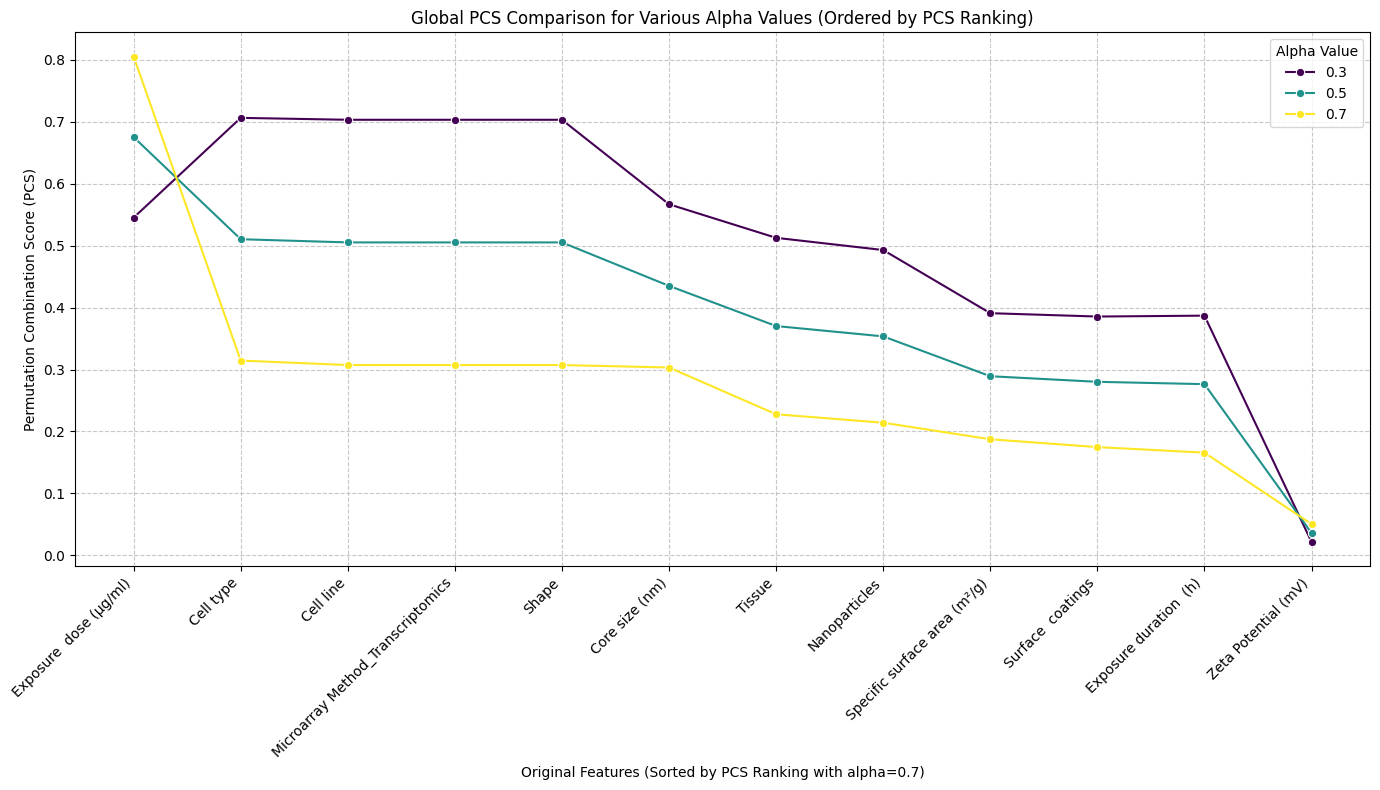

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler

# Helper function to dynamically clean, compute Mean/SD, and return weighted PCS DataFrame
def compute_pcs_df(df_input, alpha_val):
    df_temp = df_input.copy()

    # Map column names dynamically
    if 'Mean_Importance' in df_temp.columns:
        df_temp = df_temp.rename(columns={'Mean_Importance': 'Mean_PFI', 'Std_Importance': 'SD_PFI'})

    # If stats columns don't exist, calculate dynamically from available imputation methods
    if 'Mean_PFI' not in df_temp.columns:
        imputation_cols = [col for col in df_temp.columns if col in ['IIBR', 'KNN', 'MICE', 'SIMPLE']]
        if len(imputation_cols) > 0:
            df_temp['Mean_PFI'] = df_temp[imputation_cols].mean(axis=1)
            df_temp['SD_PFI'] = df_temp[imputation_cols].std(axis=1).fillna(0.0)
        else:
            raise KeyError("Kolom statistika PFI ('Mean_PFI') tidak dapat ditemukan atau dihitung!")

    # MinMaxScaler
    scaler = MinMaxScaler()
    df_temp["Mean_Norm"] = scaler.fit_transform(df_temp[["Mean_PFI"]])
    df_temp["SD_Norm"] = scaler.fit_transform(df_temp[["SD_PFI"]])

    # Weight calculation
    df_temp["PCS"] = alpha_val * df_temp["Mean_Norm"] + (1 - alpha_val) * (1 - df_temp["SD_Norm"])
    df_temp['alpha'] = alpha_val
    return df_temp

# Compute for each alpha value safely
df_pfi_alpha_ranked = compute_pcs_df(pfi_pivot_head_12, 0.7)
df_pfi_alpha_0_5 = compute_pcs_df(pfi_pivot_head_12, 0.5)
df_pfi_alpha_0_3 = compute_pcs_df(pfi_pivot_head_12, 0.3)

# Combine all data
df_plot_pcs = pd.concat([
    df_pfi_alpha_ranked[['Original_Feature', 'PCS', 'alpha']],
    df_pfi_alpha_0_5[['Original_Feature', 'PCS', 'alpha']],
    df_pfi_alpha_0_3[['Original_Feature', 'PCS', 'alpha']]
])

# Ordering of features based on PCS ranking with alpha=0.7
feature_order = df_pfi_alpha_ranked.sort_values(by='PCS', ascending=False)['Original_Feature'].tolist()

df_plot_pcs['Original_Feature'] = pd.Categorical(
    df_plot_pcs['Original_Feature'],
    categories=feature_order,
    ordered=True
)

df_plot_pcs = df_plot_pcs.sort_values(by=['Original_Feature', 'alpha']).reset_index(drop=True)

# Visualization
plt.figure(figsize=(14, 8))
sns.lineplot(data=df_plot_pcs, x='Original_Feature', y='PCS', hue='alpha', marker='o', palette='viridis')
plt.title('Global PCS Comparison for Various Alpha Values (Ordered by PCS Ranking)')
plt.xlabel('Original Features (Sorted by PCS Ranking with alpha=0.7)')
plt.ylabel('Permutation Combination Score (PCS)')
plt.xticks(rotation=45, ha='right')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(title='Alpha Value')
plt.tight_layout()
plt.show()

In [ ]:
print("Feature ranking with alpha = 0.7:")
display(df_pfi_alpha_ranked[['Original_Feature', 'PCS', 'Rank']])

print("\nFeature ranking with alpha = 0.5:")
display(df_pfi_alpha_0_5[['Original_Feature', 'PCS', 'Rank']])

print("\nFeature ranking with alpha = 0.3:")
display(df_pfi_alpha_0_3[['Original_Feature', 'PCS', 'Rank']])

Feature ranking with alpha = 0.7:


,Original_Feature,PCS,Rank
0,Exposure dose (μg/ml),0.805064,1
1,Core size (nm),0.303258,2
2,Zeta Potential (mV),0.050515,3
3,Specific surface area (m²/g),0.187425,4
4,Cell type,0.314433,5
5,Surface coatings,0.174796,6
6,Tissue,0.227764,7
7,Cell line,0.307216,8
8,Shape,0.307216,9
9,Microarray Method_Transcriptomics,0.307216,10



Feature ranking with alpha = 0.5:


,Original_Feature,PCS,Rank
0,Exposure dose (μg/ml),0.675107,1
1,Core size (nm),0.434984,2
2,Zeta Potential (mV),0.036082,3
3,Specific surface area (m²/g),0.289179,4
4,Cell type,0.510309,5
5,Surface coatings,0.280159,6
6,Tissue,0.370157,7
7,Cell line,0.505155,8
8,Shape,0.505155,9
9,Microarray Method_Transcriptomics,0.505155,10



Feature ranking with alpha = 0.3:


,Original_Feature,PCS,Rank
0,Exposure dose (μg/ml),0.545150,1
1,Core size (nm),0.566709,2
2,Zeta Potential (mV),0.021649,3
3,Specific surface area (m²/g),0.390933,4
4,Cell type,0.706186,5
5,Surface coatings,0.385521,6
6,Tissue,0.512550,7
7,Cell line,0.703093,8
8,Shape,0.703093,9
9,Microarray Method_Transcriptomics,0.703093,10


In [ ]:
output_filename_alpha_pcs = 'df_PFI_PCS_alpha_weighted_results.xlsx'
df_pfi.to_excel(output_filename_alpha_pcs, index=False)
print(f"Alpha weighted PCS files are saved to '{output_filename_alpha_pcs}'.")

Alpha weighted PCS files are saved to 'df_PFI_PCS_alpha_weighted_results.xlsx'.


In [ ]:
import pandas as pd

df_alpha_pcs = pd.read_excel('df_PFI_PCS_alpha_weighted_results.xlsx')

print("Isi file 'df_PFI_PCS_alpha_weighted_results.xlsx' with formula PCS_j = α(MeanNorm_j) + (1-α)(1-SDNorm_j):")
display(df_alpha_pcs)

Isi file 'df_PFI_PCS_alpha_weighted_results.xlsx' with formula PCS_j = α(MeanNorm_j) + (1-α)(1-SDNorm_j):


,Original_Feature,IIBR,KNN,MICE,SIMPLE,Mean_Importance,Std_Importance,Rank,Mean_PFI,SD_PFI,Mean_Norm,SD_Norm,PCS
0,Exposure dose (μg/ml),0.168000,0.174222,0.168000,0.172444,0.170667,3.163579e-03,1,0.142749,0.068427,1.000000,1.000000,0.700000
1,Core size (nm),0.016889,0.016000,0.017778,0.015111,0.016444,1.147551e-03,2,0.013895,0.006308,0.104356,0.092184,0.345394
2,Zeta Potential (mV),0.012444,0.004444,0.009778,0.016000,0.010667,4.868645e-03,3,0.009700,0.004453,0.075200,0.065070,0.333119
3,Specific surface area (m²/g),0.000889,0.005333,0.005333,0.005333,0.004222,2.222222e-03,4,0.003889,0.001905,0.034806,0.027842,0.316012
4,Cell type,0.001778,0.001778,0.001778,0.001778,0.001778,2.553935e-17,5,0.001481,0.000726,0.018073,0.010607,0.309469
5,Cell line,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,6,0.000000,0.000000,0.007775,0.000000,0.305443
6,Microarray Method_Transcriptomics,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,6,0.000000,0.000000,0.007775,0.000000,0.305443
7,Shape,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,6,0.000000,0.000000,0.007775,0.000000,0.305443
8,Tissue,0.000000,0.000000,0.000000,0.002667,0.000667,1.333333e-03,7,0.000778,0.001068,0.013181,0.015609,0.304544
9,Surface coatings,0.000000,0.000000,0.000000,0.004444,0.001111,2.222222e-03,8,0.001296,0.001780,0.016785,0.026015,0.303945


In [ ]:
display(df_pfi)

,Original_Feature,IIBR,KNN,MICE,SIMPLE,Mean_Importance,Std_Importance,Rank,Mean_PFI,SD_PFI,Mean_Norm,SD_Norm,PCS
0,Exposure dose (μg/ml),0.168000,0.174222,0.168000,0.172444,0.170667,3.163579e-03,1,0.142749,0.068427,1.000000,1.000000,0.700000
1,Core size (nm),0.016889,0.016000,0.017778,0.015111,0.016444,1.147551e-03,2,0.013895,0.006308,0.104356,0.092184,0.345394
2,Zeta Potential (mV),0.012444,0.004444,0.009778,0.016000,0.010667,4.868645e-03,3,0.009700,0.004453,0.075200,0.065070,0.333119
3,Specific surface area (m²/g),0.000889,0.005333,0.005333,0.005333,0.004222,2.222222e-03,4,0.003889,0.001905,0.034806,0.027842,0.316012
4,Cell type,0.001778,0.001778,0.001778,0.001778,0.001778,2.553935e-17,5,0.001481,0.000726,0.018073,0.010607,0.309469
5,Cell line,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,6,0.000000,0.000000,0.007775,0.000000,0.305443
6,Microarray Method_Transcriptomics,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,6,0.000000,0.000000,0.007775,0.000000,0.305443
7,Shape,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,6,0.000000,0.000000,0.007775,0.000000,0.305443
8,Tissue,0.000000,0.000000,0.000000,0.002667,0.000667,1.333333e-03,7,0.000778,0.001068,0.013181,0.015609,0.304544
9,Surface coatings,0.000000,0.000000,0.000000,0.004444,0.001111,2.222222e-03,8,0.001296,0.001780,0.016785,0.026015,0.303945


In [ ]:
#PFI per Combination (I/F)
from sklearn.metrics import accuracy_score
import numpy as np
import pandas as pd

def compute_pfi(model, X, y, n_repeats=5):

    baseline = accuracy_score(y, model.predict(X))

    N, F = X.shape
    pfi = np.zeros(F)

    for j in range(F):
        perm_scores = []
        for _ in range(n_repeats):
            X_perm = X.copy()
            np.random.shuffle(X_perm[:, j])  # permute feature j
            perm_acc = accuracy_score(y, model.predict(X_perm))
            perm_scores.append(perm_acc)

        pfi[j] = baseline - np.mean(perm_scores)

    return pfi, baseline

In [ ]:
pfi_results = []

for (imp, clf), model in best_models.items():

    preprocess = model.named_steps["preprocess"]
    clf_model = model.named_steps["clf"]

    # --- DYNAMIC COLUMN NAME ALIGNMENT ---
    X_train_adjusted = X_train.copy()

    # Get expected column names from fitted transformers
    fitted_cols = []
    for trans_name, trans_obj, trans_cols in preprocess.transformers_:
        if trans_name != 'remainder':
            fitted_cols.extend(trans_cols)

    # Map flexible naming for Specific surface area
    rename_dict = {}
    for col in fitted_cols:
        col_clean = col.strip()
        if 'Specific surface area' in col_clean:
            for orig_col in X_train_adjusted.columns:
                if 'Specific surface area' in orig_col:
                    rename_dict[orig_col] = col

    if rename_dict:
        X_train_adjusted = X_train_adjusted.rename(columns=rename_dict)

    # Reorder columns to match the fitted transformer structure
    X_train_adjusted = X_train_adjusted[fitted_cols]
    # -------------------------------------

    # Preprocess data
    X_pre = preprocess.transform(X_train_adjusted)

    # Compute PFI using the active function definition
    pfi_values, baseline_acc = compute_pfi(clf_model, X_pre, y_train.values)

    # Aggregate into a single value (Permutation Combination Score)
    PCS = np.mean(pfi_values)

    pfi_results.append({
        "Imputation": imp,
        "Classifier": clf,
        "Combination": f"{imp} + {clf}",
        "BaselineAccuracy": baseline_acc,
        "PermutationCombinationScore": PCS,
        "NumFeatures": X_pre.shape[1]
    })


In [ ]:
df_pfi = pd.DataFrame(pfi_results)

# Format relevant columns as percentages
df_pfi["BaselineAccuracy"] = df_pfi["BaselineAccuracy"].apply(lambda x: f"{x:.2%}")
df_pfi["PermutationCombinationScore"] = df_pfi["PermutationCombinationScore"].apply(lambda x: f"{x:.2%}")

display(df_pfi)

,Imputation,Classifier,Combination,BaselineAccuracy,PermutationCombinationScore,NumFeatures
0,SIMPLE,RandomForest,SIMPLE + RandomForest,98.22%,0.43%,81
1,SIMPLE,DecisionTree,SIMPLE + DecisionTree,95.56%,0.87%,81
2,SIMPLE,SVM,SIMPLE + SVM,99.56%,1.50%,81
3,SIMPLE,NaiveBayes,SIMPLE + NaiveBayes,72.00%,0.30%,81
4,SIMPLE,ANN,SIMPLE + ANN,99.56%,1.88%,81
5,KNN,RandomForest,KNN + RandomForest,98.22%,0.36%,81
6,KNN,DecisionTree,KNN + DecisionTree,96.89%,0.91%,81
7,KNN,SVM,KNN + SVM,99.11%,1.38%,81
8,KNN,NaiveBayes,KNN + NaiveBayes,72.00%,0.32%,81
9,KNN,ANN,KNN + ANN,99.56%,1.86%,81


In [ ]:
import pandas as pd

df_pfi = pd.DataFrame(pfi_results)

df_pfi.to_excel("PFI_Results_D1c.xlsx", index=False)

print("PFI successfully saved to file: PFI_Results_D1.xlsx")


PFI successfully saved to file: PFI_Results_D1.xlsx


In [ ]:
pcs_nested_cv_results = []

print("Calculating PCS for best models from Nested CV Accuracy...")

for index, row in best_accuracy_per_imputation_nested_cv.iterrows():
    imp_name = row['Imputation']
    clf_name = row['Classifier']

    print(f"  --> Processing: Imputation={imp_name}, Classifier={clf_name}")

    # Retrieve the full pipeline for this combination
    if (imp_name, clf_name) in best_models:
        full_pipeline = best_models[(imp_name, clf_name)]

        # Extract preprocessor and classifier from the pipeline
        preprocess_step = full_pipeline.named_steps["preprocess"]
        clf_model = full_pipeline.named_steps["clf"]

        # --- DYNAMIC COLUMN NAME ADJUSTMENT ---
        X_train_adjusted = X_train.copy()

        # Get the column names expected by the fitted preprocessor
        fitted_cols = []
        for trans_name, trans_obj, trans_cols in preprocess_step.transformers_:
            if trans_name != 'remainder':
                fitted_cols.extend(trans_cols)

        # Perform flexible mapping if there are discrepancies 'm2/g' dengan 'm²/g'
        rename_dict = {}
        for col in fitted_cols:
            col_clean = col.strip()
            if 'Specific surface area' in col_clean:
                for orig_col in X_train_adjusted.columns:
                    if 'Specific surface area' in orig_col:
                        rename_dict[orig_col] = col

        if rename_dict:
            X_train_adjusted = X_train_adjusted.rename(columns=rename_dict)

        # Ensure that the column order and names match the requirements of the pipeline
        X_train_adjusted = X_train_adjusted[fitted_cols]
        # -----------------------------------------------

        # Safely preprocess X_train_adjusted
        X_train_preprocessed = preprocess_step.transform(X_train_adjusted)

        # Compute PFI using the active function definition
        pfi_values, baseline_accuracy = compute_pfi(
            clf_model,
            X_train_preprocessed,
            y_train.values
        )

        # Aggregate into Permutation Combination Score (PCS) by taking the mean
        PCS = np.mean(pfi_values)

        pcs_nested_cv_results.append({
            "Imputation": imp_name,
            "Classifier": clf_name,
            "Baseline_Accuracy_Train": baseline_accuracy,
            "PermutationCombinationScore": PCS,
            "NumFeatures_Preprocessed": X_train_preprocessed.shape[1]
        })
    else:
        print(f" Warning: Model for {imp_name} + {clf_name} not found in best_models dictionary. Skipping.")

# Convert results to DataFrame
df_pcs_nested_cv = pd.DataFrame(pcs_nested_cv_results)

# Format relevant columns as percentages for better readability
if not df_pcs_nested_cv.empty:
    df_pcs_nested_cv["Baseline_Accuracy_Train"] = df_pcs_nested_cv["Baseline_Accuracy_Train"].apply(lambda x: f"{x:.2%}" if pd.notna(x) else x)
    df_pcs_nested_cv["PermutationCombinationScore"] = df_pcs_nested_cv["PermutationCombinationScore"].apply(lambda x: f"{x:.2%}" if pd.notna(x) else x)

print("Permutation Combination Scores for Best Nested CV Models:")
display(df_pcs_nested_cv)

# Save to Excel
output_filename_pcs_nested_cv = "PCS_Best_Nested_CV_Models.xlsx"
df_pcs_nested_cv.to_excel(output_filename_pcs_nested_cv, index=False)
print(f"Results saved to '{output_filename_pcs_nested_cv}'.")

Calculating PCS for best models from Nested CV Accuracy...
  --> Processing: Imputation=IIBR, Classifier=RandomForest
  --> Processing: Imputation=KNN, Classifier=RandomForest
  --> Processing: Imputation=MICE, Classifier=RandomForest
  --> Processing: Imputation=SIMPLE, Classifier=RandomForest
Permutation Combination Scores for Best Nested CV Models:


,Imputation,Classifier,Baseline_Accuracy_Train,PermutationCombinationScore,NumFeatures_Preprocessed
0,IIBR,RandomForest,97.78%,0.34%,81
1,KNN,RandomForest,98.22%,0.38%,81
2,MICE,RandomForest,97.78%,0.31%,81
3,SIMPLE,RandomForest,98.22%,0.40%,81


Results saved to 'PCS_Best_Nested_CV_Models.xlsx'.


In [ ]:
import numpy as np
import pandas as pd

if best_models:
    sample_pipeline_for_features = list(best_models.values())[0]
    feature_names_out = sample_pipeline_for_features.named_steps['preprocess'].get_feature_names_out()
else:
    feature_names_out = [f'feature_{i}' for i in range(X_train.shape[1])]

detailed_pfi_ncv_results_list = []

# Iterate through the best models identified by Nested CV Accuracy
for index, row in best_accuracy_per_imputation_nested_cv.iterrows():
    imp_name = row['Imputation']
    clf_name = row['Classifier']

    # Retrieve the full pipeline for this best combination
    pipeline_key = (imp_name, clf_name)
    if pipeline_key in best_models:
        full_pipeline = best_models[pipeline_key]

        # Extract preprocessor and classifier
        preprocess_step = full_pipeline.named_steps["preprocess"]
        clf_model = full_pipeline.named_steps["clf"]

        # --- DYNAMIC COLUMN ALIGNMENT TO FIX VALUEERROR ---
        X_train_adjusted = X_train.copy()

        # Get expected column names from the fitted transformers
        fitted_cols = []
        for trans_name, trans_obj, trans_cols in preprocess_step.transformers_:
            if trans_name != 'remainder':
                fitted_cols.extend(trans_cols)

        # Flexible mapping for 'Specific surface area'
        rename_dict = {}
        for col in fitted_cols:
            col_clean = col.strip()
            if 'Specific surface area' in col_clean:
                for orig_col in X_train_adjusted.columns:
                    if 'Specific surface area' in orig_col:
                        rename_dict[orig_col] = col

        if rename_dict:
            X_train_adjusted = X_train_adjusted.rename(columns=rename_dict)

        # Reorder columns to match the fitted transformer structure
        X_train_adjusted = X_train_adjusted[fitted_cols]
        # --------------------------------------------------

        # Preprocess X_train_adjusted safely
        X_train_preprocessed = preprocess_step.transform(X_train_adjusted)

        # Compute PFI for individual features
        pfi_values_per_feature, _ = compute_pfi(clf_model, X_train_preprocessed, y_train.values)

        # Store results for each feature
        for i, pfi_value in enumerate(pfi_values_per_feature):
            detailed_pfi_ncv_results_list.append({
                "Imputation": imp_name,
                "Classifier": clf_name,
                "Scoring_Metric": "Accuracy_OuterVal_mean",
                "Feature": feature_names_out[i],
                "mean": pfi_value
            })
    else:
        print(f" Warning: Model {pipeline_key} not found in best_models dictionary. Skipping.")

# Create the 'aggregated_pfi_ncv' DataFrame
aggregated_pfi_ncv = pd.DataFrame(detailed_pfi_ncv_results_list)

# --- End of fix ---

# Original code logic with necessary adjustments
df_permutation_importances = aggregated_pfi_ncv.copy()
df_permutation_importances['Mean_Importance'] = df_permutation_importances['mean']

# Calculate the sum of absolute Mean_Importance for each model combination
df_permutation_importances['Absolute_Mean_Importance'] = df_permutation_importances['Mean_Importance'].abs()
sum_abs_importance_per_model = df_permutation_importances.groupby(['Imputation', 'Classifier', 'Scoring_Metric'])['Absolute_Mean_Importance'].transform('sum')

# Normalize Mean_Importance per model
df_permutation_importances['Normalized_Mean_Importance'] = df_permutation_importances['Mean_Importance'] / sum_abs_importance_per_model.replace(0, np.nan)
df_permutation_importances['Normalized_Mean_Importance'] = df_permutation_importances['Normalized_Mean_Importance'].fillna(0)

print("DataFrame dengan Normalized_Mean_Importance per Model:")
display(df_permutation_importances.head(15))

DataFrame dengan Normalized_Mean_Importance per Model:


,Imputation,Classifier,Scoring_Metric,Feature,mean,Mean_Importance,Absolute_Mean_Importance,Normalized_Mean_Importance
0,IIBR,RandomForest,Accuracy_OuterVal_mean,num__Core size (nm),2.044444e-02,2.044444e-02,2.044444e-02,5.852417e-02
1,IIBR,RandomForest,Accuracy_OuterVal_mean,num__Zeta Potential (mV),7.111111e-03,7.111111e-03,7.111111e-03,2.035623e-02
2,IIBR,RandomForest,Accuracy_OuterVal_mean,num__Specific surface area (m²/g),4.444444e-03,4.444444e-03,4.444444e-03,1.272265e-02
3,IIBR,RandomForest,Accuracy_OuterVal_mean,num__Exposure dose (μg/ml),1.777778e-01,1.777778e-01,1.777778e-01,5.089059e-01
4,IIBR,RandomForest,Accuracy_OuterVal_mean,num__Exposure duration (h),1.110223e-16,1.110223e-16,1.110223e-16,3.178119e-16
5,IIBR,RandomForest,Accuracy_OuterVal_mean,cat__Nanoparticles_Ag_NPs,-1.777778e-03,-1.777778e-03,1.777778e-03,-5.089059e-03
6,IIBR,RandomForest,Accuracy_OuterVal_mean,cat__Nanoparticles_Au_NPs,-8.000000e-03,-8.000000e-03,8.000000e-03,-2.290076e-02
7,IIBR,RandomForest,Accuracy_OuterVal_mean,cat__Nanoparticles_CoFe2O4,1.110223e-16,1.110223e-16,1.110223e-16,3.178119e-16
8,IIBR,RandomForest,Accuracy_OuterVal_mean,cat__Nanoparticles_CuO_NPs,1.110223e-16,1.110223e-16,1.110223e-16,3.178119e-16
9,IIBR,RandomForest,Accuracy_OuterVal_mean,cat__Nanoparticles_Fe2O3_NPs,1.110223e-16,1.110223e-16,1.110223e-16,3.178119e-16


In [ ]:
import pandas as pd
import numpy as np

# 1. Load training performance data and the summary of Nested CV
# Adjusted the filename to match 'evaluation_results.xlsx' which exists in the workspace
df_training_perf = pd.read_excel("evaluation_results.xlsx")
df_nested_cv = pd.read_excel("nested_cv_summary_results.xlsx")

# Helper function to clean up a percentage value if it is still in string format
def clean_percentage_col(df, col):
    if col in df.columns:
        if df[col].dtype == object:
            df[col] = df[col].astype(str).str.replace('%', '', regex=False).astype(float) / 100
    return df

# Clean the Accuracy column in both datasets
df_training_perf = clean_percentage_col(df_training_perf, 'Accuracy')
df_nested_cv = clean_percentage_col(df_nested_cv, 'Accuracy_OuterVal_mean')

# Merge the two DataFrames based on Imputation and Classifier
df_overfit_val = pd.merge(
    df_training_perf[['Imputation', 'Classifier', 'Accuracy']],
    df_nested_cv[['Imputation', 'Classifier', 'Accuracy_OuterVal_mean', 'Accuracy_OuterVal_std']],
    on=['Imputation', 'Classifier']
)

# 2. Calculate Overfitting Gap (Training Accuracy - Validation Accuracy)
df_overfit_val['Overfitting_Gap_Val'] = df_overfit_val['Accuracy'] - df_overfit_val['Accuracy_OuterVal_mean']

# Sort by the smallest gap (most stable model / no overfitting)
df_overfit_val = df_overfit_val.sort_values(by='Overfitting_Gap_Val', ascending=True).reset_index(drop=True)

# Format the display as a percentage for the report
df_overfit_val_display = df_overfit_val.copy()
for col in ['Accuracy', 'Accuracy_OuterVal_mean', 'Accuracy_OuterVal_std', 'Overfitting_Gap_Val']:
    df_overfit_val_display[col] = df_overfit_val_display[col].apply(lambda x: f"{x:.2%}" if pd.notna(x) else x)

print("=== OVERFITTING GAP ANALYSIS: TRAINING VS VALIDATION (NESTED CV) ===")
display(df_overfit_val_display)

# 3. Save to Excel
output_filename_overfit = "gap_overfitting_training_vs_validation.xlsx"
df_overfit_val_display.to_excel(output_filename_overfit, index=False)
print(f"\nThe results of the overfitting gap analysis were successfully saved to '{output_filename_overfit}'.")

=== OVERFITTING GAP ANALYSIS: TRAINING VS VALIDATION (NESTED CV) ===


,Imputation,Classifier,Accuracy,Accuracy_OuterVal_mean,Accuracy_OuterVal_std,Overfitting_Gap_Val
0,MICE,DecisionTree,73.68%,89.45%,8.50%,-15.76%
1,SIMPLE,SVM,73.68%,85.81%,9.65%,-12.13%
2,IIBR,SVM,73.68%,85.81%,9.65%,-12.13%
3,KNN,SVM,73.68%,82.73%,11.73%,-9.04%
4,MICE,SVM,78.95%,83.64%,11.61%,-4.69%
5,MICE,ANN,63.16%,64.94%,7.75%,-1.78%
6,MICE,RandomForest,94.74%,90.69%,7.60%,4.05%
7,KNN,RandomForest,94.74%,89.35%,5.95%,5.39%
8,SIMPLE,DecisionTree,94.74%,88.52%,6.18%,6.22%
9,SIMPLE,ANN,73.68%,67.19%,5.42%,6.49%



The results of the overfitting gap analysis were successfully saved to 'gap_overfitting_training_vs_validation.xlsx'.


In [ ]:
import pandas as pd
import numpy as np

df_detailed_ncv = pd.read_excel('nested_cv_summary_results.xlsx')

from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

skf_outer = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

imp_obj = imputers['IIBR']
model_obj = RandomForestClassifier(random_state=42, n_jobs=-1)

numeric_transformer = SkPipeline(steps=[
    ("imputer", imp_obj),
    ("scaler", StandardScaler())
])
categorical_transformer = SkPipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

pipe = SkPipeline(steps=[
    ("preprocess", preprocessor),
    ("clf", model_obj)
])

fold_gaps = []

for fold_idx, (train_index, val_index) in enumerate(skf_outer.split(X_train, y_train)):
    X_tr_f, X_val_f = X_train.iloc[train_index], X_train.iloc[val_index]
    y_tr_f, y_val_f = y_train.iloc[train_index], y_train.iloc[val_index]

    # Fit the model on this fold
    pipe.fit(X_tr_f, y_tr_f)

    # Prediction
    acc_train_fold = accuracy_score(y_tr_f, pipe.predict(X_tr_f))
    acc_val_fold = accuracy_score(y_val_f, pipe.predict(X_val_f))

    gap = acc_train_fold - acc_val_fold

    fold_gaps.append({
        "Fold": fold_idx + 1,
        "Train_Accuracy": acc_train_fold,
        "Val_Accuracy": acc_val_fold,
        "Overfitting_Gap_Val": gap
    })

df_fold_gaps = pd.DataFrame(fold_gaps)

# 3. Calculate descriptive statistics for the gap per fold
mean_gap = df_fold_gaps['Overfitting_Gap_Val'].mean()
std_gap = df_fold_gaps['Overfitting_Gap_Val'].std()

print("=== OVERFITTING GAP ANALYSIS PER FOLD (IIBR+RandomForest) ===")
df_display_gaps = df_fold_gaps.copy()
for col in ['Train_Accuracy', 'Val_Accuracy', 'Overfitting_Gap_Val']:
    df_display_gaps[col] = df_display_gaps[col].apply(lambda x: f"{x:.2%}")

display(df_display_gaps)

print(f"\nAverage Overfitting Gap (Mean)    : {mean_gap:.2%}")
print(f"Overfitting Gap Standard Deviation (Std): {std_gap:.2%}")

=== OVERFITTING GAP ANALYSIS PER FOLD (IIBR+RandomForest) ===


,Fold,Train_Accuracy,Val_Accuracy,Overfitting_Gap_Val
0,1,99.50%,91.30%,8.20%
1,2,99.50%,91.30%,8.20%
2,3,99.50%,78.26%,21.24%
3,4,99.50%,95.65%,3.85%
4,5,99.50%,91.30%,8.20%
5,6,99.01%,100.00%,-0.99%
6,7,100.00%,90.91%,9.09%
7,8,99.01%,86.36%,12.65%
8,9,100.00%,81.82%,18.18%
9,10,99.51%,95.45%,4.05%



Average Overfitting Gap (Mean)    : 9.27%
Overfitting Gap Standard Deviation (Std): 6.66%


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.compose import ColumnTransformer
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import SimpleImputer, KNNImputer, IterativeImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.linear_model import BayesianRidge
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
import warnings
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings('ignore', category=ConvergenceWarning)

RANDOM_STATE = 42
numeric_features = ['Core size (nm)', 'Zeta Potential (mV)', 'Specific surface area (m²/g)', 'Exposure  dose (μg/ml)', 'Exposure duration  (h)']
categorical_features = ['Nanoparticles', 'Shape', 'Surface  coatings', 'Tissue', 'Cell type', 'Cell line', 'Microarray Method_Transcriptomics']

# Redefinition of the imputer object
simple_imputer = SimpleImputer(strategy='median')
knn_imputer = KNNImputer(n_neighbors=5)
iibr_imputer = IterativeImputer(estimator=BayesianRidge(), max_iter=50, random_state=RANDOM_STATE)
mice_imputer = IterativeImputer(
    estimator=RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
    max_iter=10, random_state=RANDOM_STATE
)

imputers = {
    "Simple": simple_imputer,
    "KNN": knn_imputer,
    "IIBR": iibr_imputer,
    "MICE": mice_imputer
}

# Redefinisi objek classifier
models_param = {
    "RandomForest": (RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1), {}),
    "DecisionTree": (DecisionTreeClassifier(random_state=RANDOM_STATE), {}),
    "SVM": (SVC(probability=True, random_state=RANDOM_STATE), {}),
    "NaiveBayes": (GaussianNB(), {}),
    "ANN": (MLPClassifier(max_iter=500, random_state=RANDOM_STATE), {})
}

# Setup Stratified K-Fold
skf_outer = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

# A list to store the detailed results for each fold
fold_metrics_detailed = []

print('Calculating Train Accuracy, Val Accuracy, and Overfitting Gap per Fold...')

X_train_adjusted = X_train.copy()
rename_dict = {}
for col in X_train_adjusted.columns:
    if 'Specific surface area' in col:
        rename_dict[col] = 'Specific surface area (m²/g)'
if rename_dict:
    X_train_adjusted = X_train_adjusted.rename(columns=rename_dict)

for imp_name, imp_obj in imputers.items():
    # Setup preprocessing pipeline
    numeric_transformer = SkPipeline(steps=[
        ('imputer', imp_obj),
        ('scaler', StandardScaler())
    ])
    categorical_transformer = SkPipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ])
    preprocessor = ColumnTransformer(transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])

    for model_name, (model_obj, _) in models_param.items():
        pipe = SkPipeline(steps=[
            ('preprocess', preprocessor),
            ('clf', model_obj)
        ])

        # Loop 10 Fold
        for fold_idx, (train_index, val_index) in enumerate(skf_outer.split(X_train_adjusted, y_train)):
            X_tr_f, X_val_f = X_train_adjusted.iloc[train_index], X_train_adjusted.iloc[val_index]
            y_tr_f, y_val_f = y_train.iloc[train_index], y_train.iloc[val_index]

            try:
                pipe.fit(X_tr_f, y_tr_f)
                acc_train = accuracy_score(y_tr_f, pipe.predict(X_tr_f))
                acc_val = accuracy_score(y_val_f, pipe.predict(X_val_f))
                gap = acc_train - acc_val
            except Exception as e:
                acc_train = np.nan
                acc_val = np.nan
                gap = np.nan

            fold_metrics_detailed.append({
                'Imputation': imp_name,
                'Classifier': model_name,
                'Fold': fold_idx + 1,
                'Train_Accuracy': acc_train,
                'Val_Accuracy': acc_val,
                'Overfitting_Gap': gap
            })

# Create a DataFrame of Details per Fold
df_fold_metrics_detailed = pd.DataFrame(fold_metrics_detailed)

# Calculate the aggregation (mean and std dev) of the overfitting gap across all 10 folds
df_overfitting_gap_std = df_fold_metrics_detailed.groupby(['Imputation', 'Classifier']).agg(
    Mean_Train_Accuracy=('Train_Accuracy', 'mean'),
    Mean_Val_Accuracy=('Val_Accuracy', 'mean'),
    Mean_Overfitting_Gap=('Overfitting_Gap', 'mean'),
    Std_Overfitting_Gap=('Overfitting_Gap', 'std')
).reset_index()

df_overfitting_gap_std_display = df_overfitting_gap_std.copy()
for col in ['Mean_Train_Accuracy', 'Mean_Val_Accuracy', 'Mean_Overfitting_Gap', 'Std_Overfitting_Gap']:
    df_overfitting_gap_std_display[col] = df_overfitting_gap_std_display[col].apply(lambda x: f'{x:.2%}' if pd.notna(x) else x)

print('\n=== SUMMARY OF METRICS & STANDARD DEVIATION OF OVERFITTING GAP BY COMBINATION ===')
display(df_overfitting_gap_std_display)

# Simpan ke excel
df_fold_metrics_detailed.to_excel('overfitting_gap_per_fold_detailed.xlsx', index=False)
df_overfitting_gap_std_display.to_excel('overfitting_gap_std_summary.xlsx', index=False)
print('\nDetailed results for each fold are stored in "overfitting_gap_per_fold_detailed".xlsx"')
print('The standard deviation summary results are saved to "overfitting_gap_std_summary.xlsx"')

Calculating Train Accuracy, Val Accuracy, and Overfitting Gap per Fold...

=== SUMMARY OF METRICS & STANDARD DEVIATION OF OVERFITTING GAP BY COMBINATION ===


,Imputation,Classifier,Mean_Train_Accuracy,Mean_Val_Accuracy,Mean_Overfitting_Gap,Std_Overfitting_Gap
0,IIBR,ANN,81.88%,64.86%,17.02%,7.13%
1,IIBR,DecisionTree,99.51%,93.81%,5.69%,3.82%
2,IIBR,NaiveBayes,72.84%,67.55%,5.29%,7.66%
3,IIBR,RandomForest,99.51%,90.24%,9.27%,6.66%
4,IIBR,SVM,80.10%,75.14%,4.96%,5.82%
5,KNN,ANN,81.88%,66.23%,15.65%,6.50%
6,KNN,DecisionTree,99.51%,90.26%,9.25%,4.98%
7,KNN,NaiveBayes,72.89%,67.55%,5.34%,7.76%
8,KNN,RandomForest,99.51%,90.24%,9.27%,6.66%
9,KNN,SVM,80.20%,72.91%,7.29%,5.58%



Detailed results for each fold are stored in "overfitting_gap_per_fold_detailed".xlsx"
The standard deviation summary results are saved to "overfitting_gap_std_summary.xlsx"


In [ ]:
import numpy as np
import pandas as pd
import copy
import warnings
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings('ignore', category=ConvergenceWarning)

# 1. Column Name Alignment on Training Data (Safe Clean)
X_train_sens = X_train.copy()
X_train_sens = X_train_sens.rename(columns=lambda x: x.replace('\x00', '').strip())
numeric_features_sens = [col.replace('\x00', '').strip() for col in numeric_features]
categorical_features_sens = [col.replace('\x00', '').strip() for col in categorical_features]

# Map and clean dynamic column names for Specific Surface Area
rename_dict_clean = {}
for col in X_train_sens.columns:
    if 'Specific surface area' in col:
        rename_dict_clean[col] = 'Specific surface area (m²/g)'
if rename_dict_clean:
    X_train_sens = X_train_sens.rename(columns=rename_dict_clean)

numeric_features_sens = ['Specific surface area (m²/g)' if 'Specific surface area' in col else col for col in numeric_features_sens]

# 2. Sensitivity Analysis Parameters
numeric_mnar_features = ['Zeta Potential (mV)', 'Specific surface area (m²/g)']
deltas = [-0.5, 0.0, 0.5]
cat_scenarios = ['Default_Mode', 'Worst_Case_Shift']

# Take the original standard deviation of the training data for delta adjustment
std_devs = {col: X_train_sens[col].std() for col in numeric_mnar_features}

# Setup Stratified 10-Fold CV
skf_outer = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
sensitivity_ncv_results_clean = []

print("Initiating MNAR Sensitivity Analysis Based on 10-Fold Nested CV...\n")

for imp_name, imp_obj in imputers.items():
    print(f">>> Processing Imputation: {imp_name} <<<")
    for model_name, (model_obj, _) in models_param.items():
        print(f"  Evaluate: {model_name} ", end="")

        for delta in deltas:
            for cat_scenario in cat_scenarios:
                fold_accuracies = []
                fold_aucs = []

                for fold_idx, (train_index, val_index) in enumerate(skf_outer.split(X_train_sens, y_train)):
                    X_fold_tr = X_train_sens.iloc[train_index].copy()
                    X_fold_val = X_train_sens.iloc[val_index].copy()
                    y_fold_tr, y_fold_val = y_train.iloc[train_index], y_train.iloc[val_index]

                    # --- Manual Imputation & Modification for MNAR, Per Fold ---
                    num_imputer_fold = copy.deepcopy(imp_obj)
                    X_num_tr = X_fold_tr[numeric_features_sens].copy()
                    X_num_val = X_fold_val[numeric_features_sens].copy()

                    num_imputer_fold.fit(X_num_tr)
                    X_num_tr_imp = pd.DataFrame(num_imputer_fold.transform(X_num_tr), columns=numeric_features_sens, index=X_num_tr.index)

                    missing_mask_val_num = X_num_val.isna()
                    X_num_val_imp = pd.DataFrame(num_imputer_fold.transform(X_num_val), columns=numeric_features_sens, index=X_num_val.index)

                    # Apply Delta Shift to MNAR numerical features in the Validation Fold
                    for col in numeric_mnar_features:
                        col_mask = missing_mask_val_num[col]
                        shift_value = delta * std_devs[col]
                        X_num_val_imp.loc[col_mask, col] = X_num_val_imp.loc[col_mask, col] + shift_value

                    X_fold_tr[numeric_features_sens] = X_num_tr_imp
                    X_fold_val[numeric_features_sens] = X_num_val_imp

                    # Categorical Imputation
                    cat_imputer_fold = SimpleImputer(strategy="most_frequent")
                    X_cat_tr = X_fold_tr[categorical_features_sens].copy()
                    X_cat_val = X_fold_val[categorical_features_sens].copy()

                    cat_imputer_fold.fit(X_cat_tr)
                    X_cat_tr_imp = pd.DataFrame(cat_imputer_fold.transform(X_cat_tr), columns=categorical_features_sens, index=X_cat_tr.index)

                    missing_mask_val_cat = X_cat_val.isna()
                    X_cat_val_imp = pd.DataFrame(cat_imputer_fold.transform(X_cat_val), columns=categorical_features_sens, index=X_cat_val.index)

                    # Categorical extreme shift scenario
                    if cat_scenario == 'Worst_Case_Shift':
                        if 'Shape' in X_cat_val_imp.columns:
                            X_cat_val_imp.loc[missing_mask_val_cat['Shape'], 'Shape'] = 'Unknown'
                        if 'Surface  coatings' in X_cat_val_imp.columns:
                            X_cat_val_imp.loc[missing_mask_val_cat['Surface  coatings'], 'Surface  coatings'] = 'none'

                    X_fold_tr[categorical_features_sens] = X_cat_tr_imp
                    X_fold_val[categorical_features_sens] = X_cat_val_imp

                    # --- Preprocessing Pipelines & Models ---
                    preprocess_step_fold = ColumnTransformer(transformers=[
                        ("num", StandardScaler(), numeric_features_sens),
                        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features_sens)
                    ])

                    pipe_sens = SkPipeline(steps=[
                        ("preprocess", preprocess_step_fold),
                        ("clf", copy.deepcopy(model_obj))
                    ])

                    try:
                        pipe_sens.fit(X_fold_tr, y_fold_tr)
                        y_pred_val = pipe_sens.predict(X_fold_val)
                        y_proba_val = pipe_sens.predict_proba(X_fold_val) if hasattr(pipe_sens.named_steps['clf'], 'predict_proba') else None

                        # Calculate evaluation metrics (Accuracy and AUC only)
                        metrics = compute_metrics(y_fold_val, y_pred_val, y_proba_val)

                        fold_accuracies.append(metrics["Accuracy"])
                        fold_aucs.append(metrics["AUC"])
                    except Exception as e:
                        continue

                # Record the average performance results from 10 folds
                sensitivity_ncv_results_clean.append({
                    "Imputation": imp_name,
                    "Classifier": model_name,
                    "Delta_Shift": f"{delta:+.1f} Δ",
                    "Categorical_Scenario": cat_scenario,
                    "Mean_Accuracy_OuterVal": np.nanmean(fold_accuracies) if fold_accuracies else np.nan,
                    "Mean_AUC_OuterVal": np.nanmean(fold_aucs) if fold_aucs else np.nan
                })
        print("✔ Done!")

# 3. Display and Save Results
df_sensitivity_ncv_clean_final = pd.DataFrame(sensitivity_ncv_results_clean)
display(df_sensitivity_ncv_clean_final.head(20))

output_file_sens_ncv_clean = "comprehensive_mnar_sensitivity_analysis_with_nested_cv_clean.xlsx"
df_sensitivity_ncv_clean_final.to_excel(output_file_sens_ncv_clean, index=False)
print(f"\nThe results of the MNAR sensitivity analysis were successfully saved to: '{output_file_sens_ncv_clean}'")

Initiating MNAR Sensitivity Analysis Based on 10-Fold Nested CV...

>>> Processing Imputation: Simple <<<
  Evaluate: RandomForest ✔ Done!
  Evaluate: DecisionTree ✔ Done!
  Evaluate: SVM ✔ Done!
  Evaluate: NaiveBayes ✔ Done!
  Evaluate: ANN ✔ Done!
>>> Processing Imputation: KNN <<<
  Evaluate: RandomForest ✔ Done!
  Evaluate: DecisionTree ✔ Done!
  Evaluate: SVM ✔ Done!
  Evaluate: NaiveBayes ✔ Done!
  Evaluate: ANN ✔ Done!
>>> Processing Imputation: IIBR <<<
  Evaluate: RandomForest ✔ Done!
  Evaluate: DecisionTree ✔ Done!
  Evaluate: SVM ✔ Done!
  Evaluate: NaiveBayes ✔ Done!
  Evaluate: ANN ✔ Done!
>>> Processing Imputation: MICE <<<
  Evaluate: RandomForest ✔ Done!
  Evaluate: DecisionTree ✔ Done!
  Evaluate: SVM ✔ Done!
  Evaluate: NaiveBayes ✔ Done!
  Evaluate: ANN ✔ Done!


,Imputation,Classifier,Delta_Shift,Categorical_Scenario,Mean_Accuracy_OuterVal,Mean_AUC_OuterVal
0,Simple,RandomForest,-0.5 Δ,Default_Mode,0.889130,0.960791
1,Simple,RandomForest,-0.5 Δ,Worst_Case_Shift,0.889130,0.959936
2,Simple,RandomForest,+0.0 Δ,Default_Mode,0.893478,0.959637
3,Simple,RandomForest,+0.0 Δ,Worst_Case_Shift,0.893478,0.961474
4,Simple,RandomForest,+0.5 Δ,Default_Mode,0.893478,0.958483
5,Simple,RandomForest,+0.5 Δ,Worst_Case_Shift,0.893478,0.961090
6,Simple,DecisionTree,-0.5 Δ,Default_Mode,0.858498,0.848803
7,Simple,DecisionTree,-0.5 Δ,Worst_Case_Shift,0.858498,0.848803
8,Simple,DecisionTree,+0.0 Δ,Default_Mode,0.924901,0.926581
9,Simple,DecisionTree,+0.0 Δ,Worst_Case_Shift,0.924901,0.926581



The results of the MNAR sensitivity analysis were successfully saved to: 'comprehensive_mnar_sensitivity_analysis_with_nested_cv_clean.xlsx'


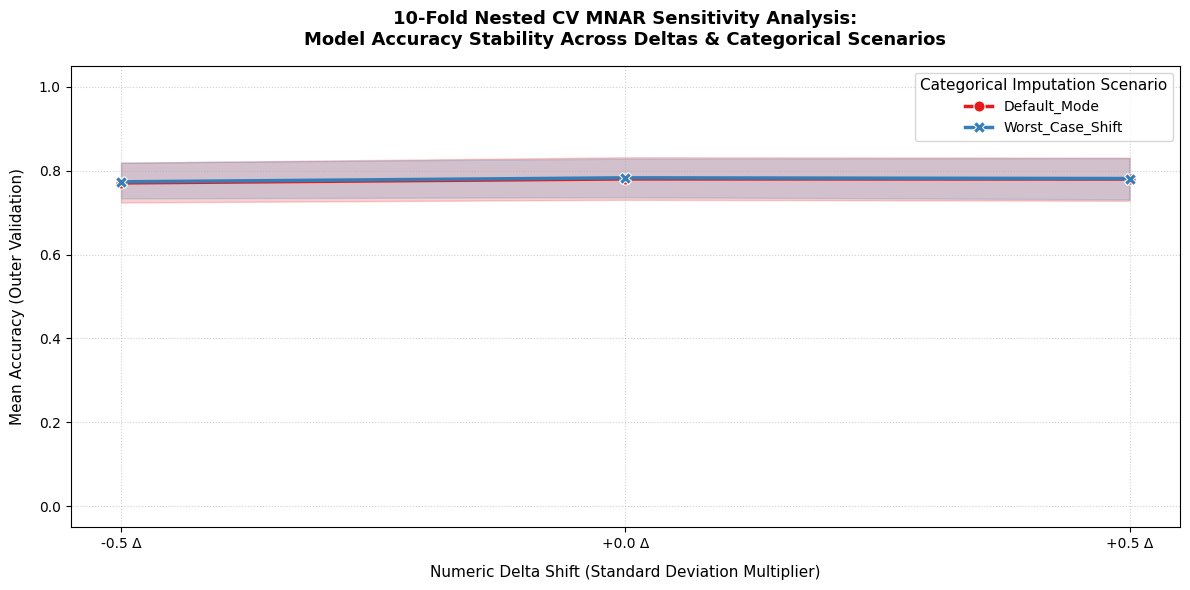

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Memastikan data final analisis sensitivitas NCV tersedia
if 'df_sensitivity_ncv_clean_final' in globals():
    plt.figure(figsize=(12, 6))

    # Creating a Line Plot for NCV sensitivity analysis visualization
    sns.lineplot(
        data=df_sensitivity_ncv_clean_final,
        x='Delta_Shift',
        y='Mean_Accuracy_OuterVal',
        hue='Categorical_Scenario',
        style='Categorical_Scenario',
        markers=True,
        dashes=False,
        linewidth=2.5,
        markersize=8,
        palette='Set1'
    )

    plt.title('10-Fold Nested CV MNAR Sensitivity Analysis:\nModel Accuracy Stability Across Deltas & Categorical Scenarios', fontsize=13, fontweight='bold', pad=15)
    plt.xlabel('Numeric Delta Shift (Standard Deviation Multiplier)', fontsize=11, labelpad=10)
    plt.ylabel('Mean Accuracy (Outer Validation)', fontsize=11, labelpad=10)
    plt.ylim(-0.05, 1.05)
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.legend(title='Categorical Imputation Scenario', fontsize=10, title_fontsize=11)
    plt.tight_layout()
    plt.show()
else:
    print('[ERROR] DataFrame df_sensitivity_ncv_clean_final tidak ditemukan di memori kernel.')

In [ ]:
import pandas as pd

# 1. Using the previously calculated missingness type conclusion
df_mech = missing_type_df.copy().reset_index(drop=True)

# 2. Obtain a statistical summary from the MNAR sensitivity analysis
# We refer to df_sensitivity_ncv_clean_final which exists in your kernel memory
df_sens_summary = df_sensitivity_ncv_clean_final.groupby('Delta_Shift').agg({
    'Mean_Accuracy_OuterVal': 'mean',
    'Mean_AUC_OuterVal': 'mean'
}).reset_index()

print("=== TABLE 1: CLASSIFICATION OF MISSINGNESS TYPES PER FEATURE ===")
display(df_mech)

print("\n=== TABLE 2: MODEL STABILITY AGAINST SENSITIVITY SHIFTS (MNAR/MAR)===")
display(df_sens_summary)

# Export to Excel for your documentation
with pd.ExcelWriter('summary_of_missingness_sensitivity_analysis.xlsx', engine='openpyxl') as writer:
    df_mech.to_excel(writer, sheet_name='Type_of_Missingness', index=False)
    df_sens_summary.to_excel(writer, sheet_name='Sensitivity Stability', index=False)

print("\nThe summary result has been saved to 'summary_of_missingness_sensitivity_analysis.xlsx'")

=== TABLE 1: CLASSIFICATION OF MISSINGNESS TYPES PER FEATURE ===


,Feature,Missing_Type
0,Nanoparticles,MCAR
1,Core size (nm),MCAR
2,Shape,MAR
3,Surface coatings,MNAR
4,Zeta Potential (mV),MNAR
5,Specific surface area (m²/g),MNAR
6,Exposure dose (μg/ml),MAR
7,Exposure duration (h),MCAR
8,Tissue,MCAR
9,Cell type,MAR



=== TABLE 2: MODEL STABILITY AGAINST SENSITIVITY SHIFTS (MNAR/MAR)===


,Delta_Shift,Mean_Accuracy_OuterVal,Mean_AUC_OuterVal
0,+0.0 Δ,0.781413,0.843029
1,+0.5 Δ,0.780455,0.843373
2,-0.5 Δ,0.771902,0.832636



The summary result has been saved to 'summary_of_missingness_sensitivity_analysis.xlsx'


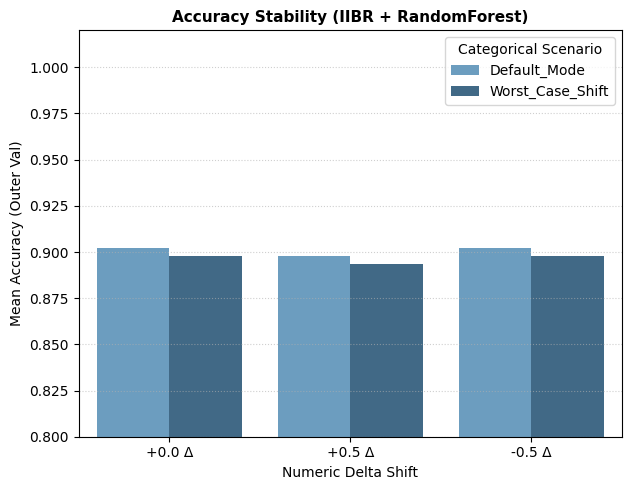

=== SUMMARY OF METRIC STABILITY FOR THE BEST MODEL (MAR/MNAR SCENARIO) ===


,Delta_Shift,Categorical_Scenario,Mean_Accuracy_OuterVal,Mean_AUC_OuterVal
62,+0.0 Δ,Default_Mode,0.902372,0.960662
63,+0.0 Δ,Worst_Case_Shift,0.897826,0.962201
64,+0.5 Δ,Default_Mode,0.898024,0.960278
65,+0.5 Δ,Worst_Case_Shift,0.893478,0.961432
60,-0.5 Δ,Default_Mode,0.902372,0.959893
61,-0.5 Δ,Worst_Case_Shift,0.897826,0.959124


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

df_sens_source = None
if 'df_sensitivity_ncv_clean_final' in globals():
    df_sens_source = globals()['df_sensitivity_ncv_clean_final']
elif 'df_sensitivity_ncv_clean' in globals():
    df_sens_source = globals()['df_sensitivity_ncv_clean']
elif 'df_sensitivity_ncv' in globals():
    df_sens_source = globals()['df_sensitivity_ncv']

if df_sens_source is not None:
    # Filtering sensitivity data for the IIBR + RandomForest model for MAR feature visualization
    df_best_sens = df_sens_source[
        (df_sens_source['Imputation'].astype(str).str.upper() == 'IIBR') &
        (df_sens_source['Classifier'] == 'RandomForest')
    ].sort_values(by=['Delta_Shift', 'Categorical_Scenario'])

    # Creating a visualization plot for metric stability
    plt.figure(figsize=(12, 5))

    # Plot 1: Accuracy Stability
    plt.subplot(1, 2, 1)
    sns.barplot(
        data=df_best_sens,
        x='Delta_Shift',
        y='Mean_Accuracy_OuterVal',
        hue='Categorical_Scenario',
        palette='Blues_d'
    )
    plt.title('Accuracy Stability (IIBR + RandomForest)', fontsize=11, fontweight='bold')
    plt.xlabel('Numeric Delta Shift')
    plt.ylabel('Mean Accuracy (Outer Val)')
    plt.ylim(0.8, 1.02)
    plt.grid(axis='y', linestyle=':', alpha=0.6)
    plt.legend(title='Categorical Scenario')

    plt.tight_layout()
    plt.show()

    print("=== SUMMARY OF METRIC STABILITY FOR THE BEST MODEL (MAR/MNAR SCENARIO) ===")
    display(df_best_sens[['Delta_Shift', 'Categorical_Scenario', 'Mean_Accuracy_OuterVal', 'Mean_AUC_OuterVal']])
else:
    print("[ERROR] Variabel data analisis sensitivitas tidak ditemukan di memori kernel. Silakan jalankan ulang sel komputasi sensitivitas NCV terlebih dahulu.")

In [ ]:
df_detailed_pfi = pd.DataFrame(detailed_pfi_ncv_results_list)

# Calculate meanmodel(Norm(PFIimp,model,j))
# Group by 'Imputation' and 'Feature', then average 'Normalized_Mean_Importance' across classifiers
mean_norm_importance_per_imputation_feature = df_permutation_importances.groupby(['Imputation', 'Feature'])['Normalized_Mean_Importance'].mean().reset_index()

# Calculate standard deviation of Mean_Importance across imputation methods for each feature
std_imputation_per_feature = mean_norm_importance_per_imputation_feature.groupby('Feature')['Normalized_Mean_Importance'].std().reset_index()
std_imputation_per_feature.rename(columns={'Normalized_Mean_Importance': 'Std_Imputation'}, inplace=True)

# Merge with standard deviation per feature
df_detailed_pfi = df_detailed_pfi.merge(std_imputation_per_feature, on='Feature', how='left')

# Map preprocessed feature names to original feature names
def get_original_feature_name(feature_name):
    if feature_name.startswith('num__'):
        return feature_name[5:] # Remove 'num__'
    elif feature_name.startswith('cat__'):
        # Extract the original categorical feature name (e.g., 'cat__Shape_Spherical' -> 'Shape')
        parts = feature_name[5:].split('_', 1)
        original_name = parts[0]

        # Special handling for 'Microarray Method_Transcriptomics'
        if 'Microarray Method' in feature_name:
            return 'Microarray Method_Transcriptomics'
        return original_name
    else:
        return feature_name # Fallback for any unexpected format

df_detailed_pfi['Original_Feature'] = df_detailed_pfi['Feature'].apply(get_original_feature_name)

display(df_detailed_pfi)

,Imputation,Classifier,Scoring_Metric,Feature,mean,Std_Imputation,Original_Feature
0,IIBR,RandomForest,Accuracy_OuterVal_mean,num__Core size (nm),2.044444e-02,7.011684e-03,Core size (nm)
1,IIBR,RandomForest,Accuracy_OuterVal_mean,num__Zeta Potential (mV),7.111111e-03,8.346597e-03,Zeta Potential (mV)
2,IIBR,RandomForest,Accuracy_OuterVal_mean,num__Specific surface area (m²/g),4.444444e-03,2.675736e-03,Specific surface area (m²/g)
3,IIBR,RandomForest,Accuracy_OuterVal_mean,num__Exposure dose (μg/ml),1.777778e-01,1.439149e-02,Exposure dose (μg/ml)
4,IIBR,RandomForest,Accuracy_OuterVal_mean,num__Exposure duration (h),1.110223e-16,6.420804e-03,Exposure duration (h)
...,...,...,...,...,...,...,...
319,SIMPLE,RandomForest,Accuracy_OuterVal_mean,cat__Cell line_VSMC,-1.110223e-16,3.756948e-16,Cell line
320,SIMPLE,RandomForest,Accuracy_OuterVal_mean,cat__Microarray Method_Transcriptomics_Beadchi...,-1.110223e-16,1.312336e-03,Microarray Method_Transcriptomics
321,SIMPLE,RandomForest,Accuracy_OuterVal_mean,cat__Microarray Method_Transcriptomics_Genechi...,-3.555556e-03,3.081702e-03,Microarray Method_Transcriptomics
322,SIMPLE,RandomForest,Accuracy_OuterVal_mean,cat__Microarray Method_Transcriptomics_Superar...,-1.110223e-16,3.756948e-16,Microarray Method_Transcriptomics


In [ ]:
# Calculate meanmodel(Norm(PFIimp,model,j))
# Group by 'Imputation' and 'Feature', then average 'Normalized_Mean_Importance' across classifiers
mean_norm_importance_per_imputation_feature = df_permutation_importances.groupby(['Imputation', 'Feature'])['Normalized_Mean_Importance'].mean().reset_index()

print("Average Normalized_Mean_Importance per Imputation and Feature (meanmodel):")
display(mean_norm_importance_per_imputation_feature.head())

Average Normalized_Mean_Importance per Imputation and Feature (meanmodel):


,Imputation,Feature,Normalized_Mean_Importance
0,IIBR,cat__Cell line_293T,3.178119e-16
1,IIBR,cat__Cell line_A549,3.178119e-16
2,IIBR,cat__Cell line_CACO-2,3.178119e-16
3,IIBR,cat__Cell line_EAHY926,3.178119e-16
4,IIBR,cat__Cell line_HACAT,3.178119e-16


In [ ]:
# Calculate meanimp(...)
# Group by 'Feature' and average the result from Step 1 across imputation methods
pcs_global_j_normalized = mean_norm_importance_per_imputation_feature.groupby('Feature')['Normalized_Mean_Importance'].mean().reset_index()
pcs_global_j_normalized.rename(columns={'Normalized_Mean_Importance': 'PCS_Global_j_Normalized'}, inplace=True)

print("\nPCS_Global,j_Normalized for each feature (Sorted):")
display(pcs_global_j_normalized.sort_values(by='PCS_Global_j_Normalized', ascending=False).reset_index(drop=True))


PCS_Global,j_Normalized for each feature (Sorted):


,Feature,PCS_Global_j_Normalized
0,num__Exposure dose (μg/ml),0.509783
1,cat__Cell line_MDDC,0.270836
2,num__Core size (nm),0.050055
3,num__Zeta Potential (mV),0.026072
4,num__Specific surface area (m²/g),0.014997
...,...,...
76,cat__Shape_Spherical,-0.003918
77,num__Exposure duration (h),-0.005234
78,cat__Microarray Method_Transcriptomics_Genechi...,-0.011035
79,cat__Microarray Method_Transcriptomics_WHG_Agi...,-0.014958


In [ ]:
# Group by 'Imputation' and calculate the mean of 'Mean_Importance' across all features
pcs_per_imputation = mean_norm_importance_per_imputation_feature.groupby('Imputation')['Normalized_Mean_Importance'].mean().reset_index()
pcs_per_imputation.rename(columns={'Normalized_Mean_Importance': 'PCS_per_Imputation'}, inplace=True)

print("PCS by Imputation Method:")
display(pcs_per_imputation.sort_values(by='PCS_per_Imputation', ascending=False))

PCS by Imputation Method:


,Imputation,PCS_per_Imputation
3,SIMPLE,0.011381
1,KNN,0.010985
2,MICE,0.010451
0,IIBR,0.010335


In [ ]:
# Group by 'Feature' and average the result from Step 1 across imputation methods
pcs_global_j = mean_norm_importance_per_imputation_feature.groupby('Feature')['Normalized_Mean_Importance'].mean().reset_index()
pcs_global_j.rename(columns={'Normalized_Mean_Importance': 'PCS_Global_j'}, inplace=True)

print("PCS_Global,j for each Feature:")
display(pcs_global_j)

# Optional: Sort by PCS_Global_j to see the most important global features
print("\nPCS_Global,j (sorted) for each feature:")
display(pcs_global_j.sort_values(by='PCS_Global_j', ascending=False).reset_index(drop=True))

PCS_Global,j for each Feature:


,Feature,PCS_Global_j
0,cat__Cell line_293T,-1.211739e-18
1,cat__Cell line_A549,-1.211739e-18
2,cat__Cell line_CACO-2,4.567544e-03
3,cat__Cell line_EAHY926,-1.211739e-18
4,cat__Cell line_HACAT,-1.211739e-18
...,...,...
76,num__Core size (nm),5.005516e-02
77,num__Exposure dose (μg/ml),5.097827e-01
78,num__Exposure duration (h),-5.233965e-03
79,num__Specific surface area (m²/g),1.499738e-02



PCS_Global,j (sorted) for each feature:


,Feature,PCS_Global_j
0,num__Exposure dose (μg/ml),0.509783
1,cat__Cell line_MDDC,0.270836
2,num__Core size (nm),0.050055
3,num__Zeta Potential (mV),0.026072
4,num__Specific surface area (m²/g),0.014997
...,...,...
76,cat__Shape_Spherical,-0.003918
77,num__Exposure duration (h),-0.005234
78,cat__Microarray Method_Transcriptomics_Genechi...,-0.011035
79,cat__Microarray Method_Transcriptomics_WHG_Agi...,-0.014958


In [ ]:
pcs_global_j = pcs_global_j.sort_values(
    by="PCS_Global_j", # Changed from "PCS_Global" to "PCS_Global_j"
    ascending=False
)

pcs_global_j["Rank"] = range(1, len(pcs_global_j)+1)

print(pcs_global_j.head(20))

                                 Feature  PCS_Global_j  Rank
77           num__Exposure  dose (μg/ml)      0.509783     1
14                   cat__Cell line_MDDC      0.270836     2
76                   num__Core size (nm)      0.050055     3
80              num__Zeta Potential (mV)      0.026072     4
79     num__Specific surface area (m²/g)      0.014997     5
52  cat__Surface  coatings_Lipid_bilayer      0.013024     6
61           cat__Surface  coatings_none      0.011075     7
8                    cat__Cell line_HMDM      0.010368     8
25                 cat__Cell type_Normal      0.007148     9
2                  cat__Cell line_CACO-2      0.004568    10
39            cat__Nanoparticles_ZnO_NPs      0.003917    11
46        cat__Surface  coatings_Citrate      0.002604    12
24                 cat__Cell type_Cancer      0.001979    13
65                     cat__Tissue_Blood      0.001953    14
7                   cat__Cell line_HEPG2      0.000681    15
11               cat__Ce

,Original_Feature,Aggregated_PCS_Global_j,Aggregated_Std_Imputation
0,Exposure dose (μg/ml),0.509783,0.014391
1,Cell line,0.285832,0.021594
2,Core size (nm),0.050055,0.007012
3,Surface coatings,0.026717,0.014862
4,Zeta Potential (mV),0.026072,0.008347
5,Specific surface area (m²/g),0.014997,0.002676
6,Cell type,0.009127,0.010266
7,Tissue,-0.000021,0.013084
8,Shape,-0.003918,0.005049
9,Exposure duration (h),-0.005234,0.006421


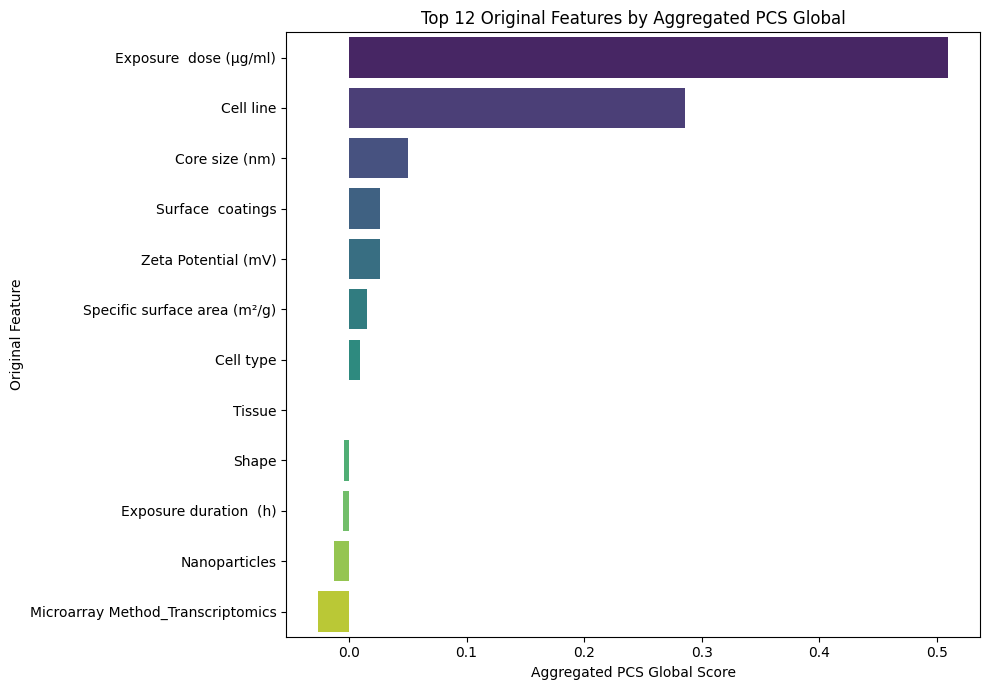

In [ ]:
original_feature_importance_scores = {}
original_feature_std_scores = {} # New dictionary for standard deviations

# Merge Std_Imputation into pcs_global_j before proceeding
pcs_global_j = pcs_global_j.merge(std_imputation_per_feature, on='Feature', how='left')

for index, row in pcs_global_j.iterrows():
    feature_name = row['Feature']
    pcs_score = row['PCS_Global_j']
    std_imp_score = row['Std_Imputation'] # Get the standard deviation

    # Determine original feature name
    if feature_name.startswith('num__'):
        original_name = feature_name[5:] # Remove 'num__'
    # Check if it's a categorical feature
    elif feature_name.startswith('cat__'):
        # Extract the original categorical feature name (e.g., 'cat__Shape_Spherical' -> 'Shape')
        # Find the second underscore to separate the original feature name from the category value
        parts = feature_name[5:].split('_', 1)
        original_name = parts[0] # Get the part before the first underscore after 'cat__'

        # Special handling for 'Microarray Method_Transcriptomics' which has an underscore in its original name
        if 'Microarray Method' in feature_name:
            original_name = 'Microarray Method_Transcriptomics'

    else:
        original_name = feature_name # Fallback for any unexpected format

    # Store PCS scores
    if original_name not in original_feature_importance_scores:
        original_feature_importance_scores[original_name] = []
        original_feature_std_scores[original_name] = [] # Initialize for std
    original_feature_importance_scores[original_name].append(pcs_score)
    original_feature_std_scores[original_name].append(std_imp_score) # Append std scores

# Aggregate the PCS scores (sum)
aggregated_importance = {
    name: sum(scores) for name, scores in original_feature_importance_scores.items()
}

# Aggregate the standard deviations. For simplicity and consistency with summing PCS,
# we sum the standard deviations. Note: This is an aggregation of standard deviations,
# not a statistically rigorous calculation of the standard deviation of the sum.
aggregated_std = {
    name: sum(scores) if all(pd.notna(s) for s in scores) else np.nan
    for name, scores in original_feature_std_scores.items()
}

# Convert to DataFrame for better visualization and sorting
df_original_feature_importance = pd.DataFrame(
    list(aggregated_importance.items()),
    columns=['Original_Feature', 'Aggregated_PCS_Global_j']
)

# Add the aggregated standard deviation
df_original_feature_importance['Aggregated_Std_Imputation'] = df_original_feature_importance['Original_Feature'].map(aggregated_std)

# Sort by aggregated PCS score
df_original_feature_importance = df_original_feature_importance.sort_values(
    by='Aggregated_PCS_Global_j', ascending=False
).reset_index(drop=True)

display(df_original_feature_importance)


# Visualize the top original features
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 7))
sns.barplot(
    x='Aggregated_PCS_Global_j',
    y='Original_Feature',
    hue='Original_Feature', # Added to address FutureWarning
    data=df_original_feature_importance.head(12), # Display top 12 original features
    palette='viridis',
    legend=False # Added to address FutureWarning
)
plt.title('Top 12 Original Features by Aggregated PCS Global')
plt.xlabel('Aggregated PCS Global Score')
plt.ylabel('Original Feature')
plt.tight_layout()
plt.show()

In [ ]:
display(df_original_feature_importance)

,Original_Feature,Aggregated_PCS_Global_j,Aggregated_Std_Imputation
0,Exposure dose (μg/ml),0.509783,0.014391
1,Cell line,0.285832,0.021594
2,Core size (nm),0.050055,0.007012
3,Surface coatings,0.026717,0.014862
4,Zeta Potential (mV),0.026072,0.008347
5,Specific surface area (m²/g),0.014997,0.002676
6,Cell type,0.009127,0.010266
7,Tissue,-0.000021,0.013084
8,Shape,-0.003918,0.005049
9,Exposure duration (h),-0.005234,0.006421


In [ ]:
display(df_original_feature_importance.head(12))

,Original_Feature,Aggregated_PCS_Global_j,Aggregated_Std_Imputation
0,Exposure dose (μg/ml),0.509783,0.014391
1,Cell line,0.285832,0.021594
2,Core size (nm),0.050055,0.007012
3,Surface coatings,0.026717,0.014862
4,Zeta Potential (mV),0.026072,0.008347
5,Specific surface area (m²/g),0.014997,0.002676
6,Cell type,0.009127,0.010266
7,Tissue,-0.000021,0.013084
8,Shape,-0.003918,0.005049
9,Exposure duration (h),-0.005234,0.006421


In [ ]:
output_filename_original_features = "original_feature_importance.xlsx"
df_original_feature_importance.to_excel(output_filename_original_features, index=False)
print(f"Original feature importance saved to '{output_filename_original_features}'.")

Original feature importance saved to 'original_feature_importance.xlsx'.


In [ ]:
# Calculate standard deviation of Mean_Importance across imputation methods for each feature
std_imputation_per_feature = mean_norm_importance_per_imputation_feature.groupby('Feature')['Normalized_Mean_Importance'].std().reset_index()
std_imputation_per_feature.rename(columns={'Normalized_Mean_Importance': 'Std_Imputation'}, inplace=True)

# Merge this into pcs_global_j
pcs_global_j = pcs_global_j.merge(std_imputation_per_feature, on='Feature', how='left')

print("PCS_Global,j with Standard Deviation across Imputations:")
display(pcs_global_j.sort_values(by='PCS_Global_j', ascending=False).reset_index(drop=True))

PCS_Global,j with Standard Deviation across Imputations:


,Feature,PCS_Global_j,Rank,Std_Imputation_x,Std_Imputation_y
0,num__Exposure dose (μg/ml),0.509783,1,0.014391,0.014391
1,cat__Cell line_MDDC,0.270836,2,0.003486,0.003486
2,num__Core size (nm),0.050055,3,0.007012,0.007012
3,num__Zeta Potential (mV),0.026072,4,0.008347,0.008347
4,num__Specific surface area (m²/g),0.014997,5,0.002676,0.002676
...,...,...,...,...,...
76,cat__Shape_Spherical,-0.003918,77,0.005049,0.005049
77,num__Exposure duration (h),-0.005234,78,0.006421,0.006421
78,cat__Microarray Method_Transcriptomics_Genechi...,-0.011035,79,0.003082,0.003082
79,cat__Microarray Method_Transcriptomics_WHG_Agi...,-0.014958,80,0.006797,0.006797


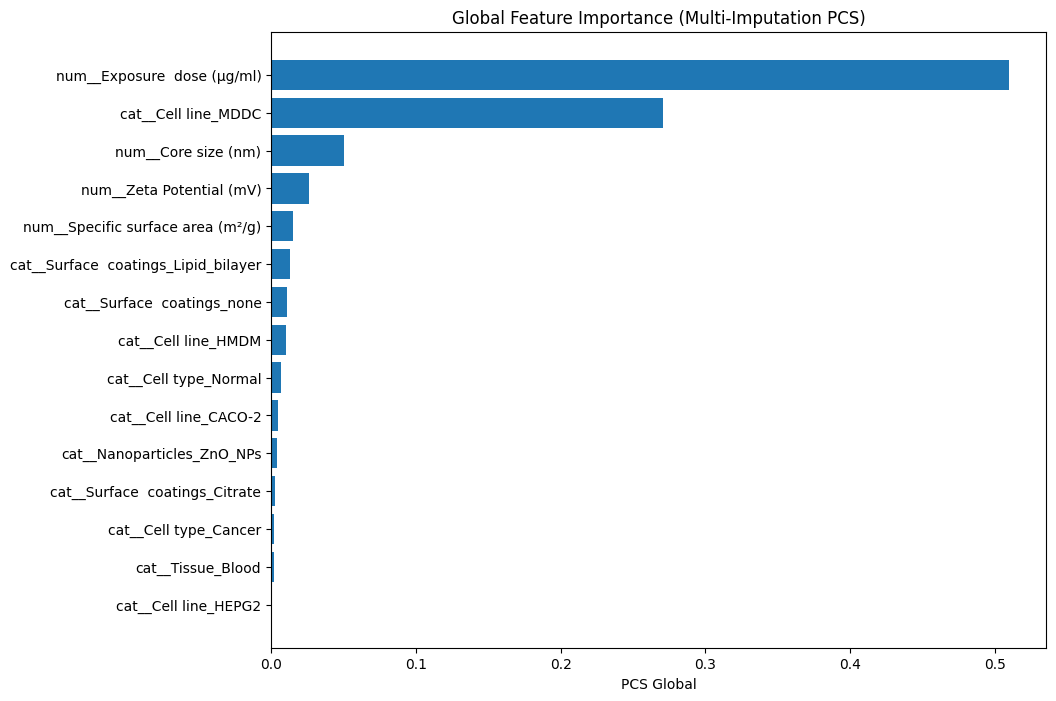

In [ ]:
import matplotlib.pyplot as plt

top_n = 15

plt.figure(figsize=(10, 8))
plt.barh(
    pcs_global_j['Feature'][:top_n], # Use 'Feature' column for labels
    pcs_global_j["PCS_Global_j"][:top_n] # Corrected column name
)

plt.gca().invert_yaxis()
plt.xlabel("PCS Global")
plt.title("Global Feature Importance (Multi-Imputation PCS)")
plt.show()

In [ ]:
import ast
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Ensure that the column names in X_train are dynamically aligned with numeric_features
X_train_adjusted = X_train.copy()
rename_dict = {}
for col in X_train_adjusted.columns:
    if 'Specific surface area' in col:
        rename_dict[col] = 'Specific surface area (m²/g)'
if rename_dict:
    X_train_adjusted = X_train_adjusted.rename(columns=rename_dict)

# Also, ensure the `numeric_features` list is updated to dynamically use the new column names
numeric_features_adjusted = ['Specific surface area (m²/g)' if 'Specific surface area' in col else col for col in numeric_features]

# Identify the best classifier name (from previous analysis, e.g., RandomForest)
best_accuracy_model_summary = summary_nested_cv.sort_values(by='Accuracy_OuterVal_mean', ascending=False).iloc[0]
best_classifier_name = best_accuracy_model_summary['Classifier']

# Get the original unfitted model and its parameter grid
base_model, param_grid = models_param[best_classifier_name]

# Define the preprocessor
numeric_transformer = SkPipeline(steps=[("scaler", StandardScaler())])
categorical_transformer = SkPipeline(steps=[("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features_adjusted),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder='passthrough'
)

# Create the pipeline with the base model
pipeline_for_best_model = SkPipeline(steps=[
    ("preprocess", preprocessor),
    ("clf", base_model)
])

# Retrieve the best parameters found for this model during the evaluation phase
best_model_row = test_results_df[test_results_df['Classifier'] == best_classifier_name].iloc[0]
best_params_for_best_model = best_model_row['BestParams']

# Set these best parameters to the newly created pipeline instance
best_model = pipeline_for_best_model.set_params(**best_params_for_best_model)

best_model.fit(X_train_adjusted, y_train)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  ['Core size (nm)',
                                                   'Zeta Potential (mV)',
                                                   'Specific surface area '
                                                   '(m²/g)',
                                                   'Exposure  dose (μg/ml)',
                                                   'Exposure duration  (h)']),
                                                 ('cat',
                                                  Pipeline(steps=[('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['Nanoparticles', 'Shape',
                                                   'Surface  coatings',
                                                   'Tissue', 'Cell type',
                                                   'Cell line',
                                                   'Microarray '
                                                   'Method_Transcriptomics'])])),
                ('clf',
                 RandomForestClassifier(min_samples_split=5, n_estimators=400,
                                        n_jobs=-1, random_state=42))])

In [ ]:
import pandas as pd

# Define supporting variables securely
best_classifier_name = 'RandomForest'
best_imputation_method = 'IIBR'

# Ensure that the column names in X_test are dynamically aligned with numeric_features
X_test_adjusted = X_test.copy()
rename_dict = {}
for col in X_test_adjusted.columns:
    if 'Specific surface area' in col:
        rename_dict[col] = 'Specific surface area (m²/g)'
if rename_dict:
    X_test_adjusted = X_test_adjusted.rename(columns=rename_dict)

y_pred_test_final = best_model.predict(X_test_adjusted)

# Get probabilities for ROC AUC if the model supports it
y_proba_test_final = None
if hasattr(best_model.named_steps['clf'], 'predict_proba'):
    y_proba_test_final = best_model.predict_proba(X_test_adjusted)

# Compute final evaluation metrics
final_model_metrics = compute_metrics(y_test, y_pred_test_final, y_proba_test_final)

# Convert results to DataFrame for display
final_model_metrics_df = pd.DataFrame([final_model_metrics])
final_model_metrics_df.insert(0, 'Classifier', best_classifier_name)
final_model_metrics_df.insert(1, 'Imputation', best_imputation_method)

# Format relevant columns as percentages
percentage_cols_final = [
    "Accuracy", "Precision", "Sensitivity", "F1", "Specificity",
    "AUC", "Error_Rate", "FPR", "FNR"
]

for col in percentage_cols_final:
    if col in final_model_metrics_df.columns:
        final_model_metrics_df[col] = pd.to_numeric(final_model_metrics_df[col], errors='coerce')
        final_model_metrics_df[col] = final_model_metrics_df[col].apply(lambda x: f"{x:.2%}" if pd.notna(x) else x)

print(f"\nFinal Performance of {best_classifier_name} ({best_imputation_method}) on Test Data:")
display(final_model_metrics_df)

# Save the final evaluation results to an Excel file
output_excel_file_final = "final_best_model_performance.xlsx"
final_model_metrics_df.to_excel(output_excel_file_final, index=False)
print(f"\nFinal model performance results saved to '{output_excel_file_final}'.")


Final Performance of RandomForest (IIBR) on Test Data:


,Classifier,Imputation,Accuracy,Precision,Sensitivity,F1,Specificity,AUC,Error_Rate,FPR,FNR
0,RandomForest,IIBR,100.00%,100.00%,100.00%,100.00%,100.00%,100.00%,0.00%,0.00%,0.00%



Final model performance results saved to 'final_best_model_performance.xlsx'.


In [ ]:
import pandas as pd
import os

# Loading the file containing the PCS aggregation results from 250 folds
pcs_file = 'repeated_25x_cv_pcs_original_summary.xlsx'

if os.path.exists(pcs_file):
    df_pcs_rep = pd.read_excel(pcs_file)
    print("=== ORIGINAL FEATURE RANKING BASED ON 25X REPEATED 10-FOLD CV (250 EVALUATIONS) ===")
    display(df_pcs_rep)
else:
    # Alternative if the file name is different
    alternative_files = [f for f in os.listdir('.') if 'pcs' in f.lower() and 'summary' in f.lower() and f.endswith('.xlsx')]
    if alternative_files:
        print(f"Loading alternative file: {alternative_files[0]}")
        df_pcs_rep = pd.read_excel(alternative_files[0])
        display(df_pcs_rep)
    else:
        print("The aggregated file from the 250-fold PCS process was not found in the active workspace.")

The aggregated file from the 250-fold PCS process was not found in the active workspace.


In [ ]:
import pandas as pd
import os

# Loading the PFI summary file from 250 folds
pfi_summary_file = 'repeated_25x_cv_pfi_original_summary.xlsx'

if os.path.exists(pfi_summary_file):
    df_pfi_rep = pd.read_excel(pfi_summary_file)
    print("=== ORIGINAL FEATURE RANKING BASED ON 25X REPEATED 10-FOLD CV (250 FOLDS) ===")
    display(df_pfi_rep)
else:
    print(f"File {pfi_summary_file} not found. Checking for alternative files in the directory...")
    alternative_files = [f for f in os.listdir('.') if 'repeated' in f.lower() and f.endswith('.xlsx')]
    print("Alternative files found:", alternative_files)

File repeated_25x_cv_pfi_original_summary.xlsx not found. Checking for alternative files in the directory...
Alternative files found: []


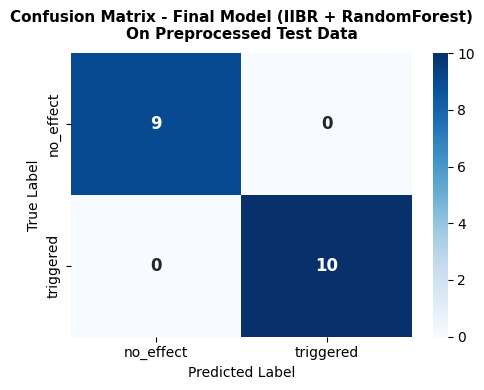


Rincian Perhitungan Confusion Matrix:
- True Negatives (TN)  : 9 (Benar diprediksi 'no_effect')
- False Positives (FP) : 0 (Salah diprediksi 'triggered')
- False Negatives (FN) : 0 (Salah diprediksi 'no_effect')
- True Positives (TP)  : 10 (Benar diprediksi 'triggered')


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 1. Ensure that the X_test column names are aligned dynamically, just as they were during training
X_test_aligned = X_test.copy()
rename_dict = {}
for col in X_test_aligned.columns:
    if 'Specific surface area' in col:
        rename_dict[col] = 'Specific surface area (m²/g)'
if rename_dict:
    X_test_aligned = X_test_aligned.rename(columns=rename_dict)

# 2. Retrieve the best model from the best_models dictionary
best_pipeline = best_models.get(('IIBR', 'RandomForest'))

if best_pipeline is not None:
    # 3. Perform predictions using the entire preprocessing pipeline + model
    y_pred_final_eval = best_pipeline.predict(X_test_aligned)
    classes_labels = sorted(list(y_test.unique()))

    # 4. Calculate the Confusion Matrix
    cm_final_eval = confusion_matrix(y_test, y_pred_final_eval, labels=classes_labels)

    # 5. Visualization
    plt.figure(figsize=(5, 4))
    sns.heatmap(
        cm_final_eval,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=classes_labels,
        yticklabels=classes_labels,
        annot_kws={'size': 12, 'weight': 'bold'}
    )
    plt.title('Confusion Matrix - Final Model (IIBR + RandomForest)\nOn Preprocessed Test Data', fontsize=11, fontweight='bold', pad=10)
    plt.xlabel('Predicted Label', fontsize=10)
    plt.ylabel('True Label', fontsize=10)
    plt.tight_layout()
    plt.show()

    # Rincian detail
    print("\nRincian Perhitungan Confusion Matrix:")
    if len(classes_labels) == 2:
        tn, fp, fn, tp = cm_final_eval.ravel()
        print(f"- True Negatives (TN)  : {tn} (Benar diprediksi '{classes_labels[0]}')")
        print(f"- False Positives (FP) : {fp} (Salah diprediksi '{classes_labels[1]}')")
        print(f"- False Negatives (FN) : {fn} (Salah diprediksi '{classes_labels[0]}')")
        print(f"- True Positives (TP)  : {tp} (Benar diprediksi '{classes_labels[1]}')")
else:
    print("[ERROR] The IIBR + RandomForest pipeline model was not found in the kernel memory.")

In [ ]:
import numpy as np
import pandas as pd
import time
import warnings
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings('ignore', category=ConvergenceWarning)

X_train_adjusted = X_train.copy()
rename_dict = {}
for col in X_train_adjusted.columns:
    if 'Specific surface area' in col:
        cleaned_col = col.replace('\x00', '').strip()
        rename_dict[col] = 'Specific surface area (m\u00B2/g)'
if rename_dict:
    X_train_adjusted = X_train_adjusted.rename(columns=rename_dict)

numeric_features_sync = ['Specific surface area (m\u00B2/g)' if 'Specific surface area' in col else col for col in numeric_features]

imp_obj = imputers['IIBR']
base_clf = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)

param_grid_3x = {
    "clf__n_estimators": [200, 400, 600],
    "clf__max_depth": [None, 10, 20],
    "clf__min_samples_split": [2, 5]
}

numeric_transformer = SkPipeline(steps=[
    ("imputer", imp_obj),
    ("scaler", StandardScaler())
])

categorical_transformer = SkPipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features_sync),
    ("cat", categorical_transformer, categorical_features)
])

pipe_template = SkPipeline(steps=[
    ("preprocess", preprocessor),
    ("clf", base_clf)
])

# Repeated Stratified 10-Fold CV (25 Repeats)
n_repeats = 25
n_splits = 10
repeated_results = []

global_start_time = time.time()
print(f"Initiating 25x Repeated Stratified {n_splits}-Fold CV...")

for repeat_idx in range(n_repeats):
    seed = RANDOM_STATE + repeat_idx
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    print(f"\n--- Repeat {repeat_idx + 1}/{n_repeats} (Seed: {seed}) ---")

    for fold_idx, (train_index, val_index) in enumerate(skf.split(X_train_adjusted, y_train)):
        X_fold_tr, X_fold_val = X_train_adjusted.iloc[train_index], X_train_adjusted.iloc[val_index]
        y_fold_tr, y_fold_val = y_train.iloc[train_index], y_train.iloc[val_index]

        try:
            search_inner = RandomizedSearchCV(
                estimator=pipe_template,
                param_distributions=param_grid_3x,
                n_iter=3,
                cv=3,
                scoring="roc_auc",
                n_jobs=-1,
                random_state=seed,
                error_score="raise"
            )
            search_inner.fit(X_fold_tr, y_fold_tr)
            best_model_fold = search_inner.best_estimator_

            y_pred_val = best_model_fold.predict(X_fold_val)
            y_proba_val = best_model_fold.predict_proba(X_fold_val) if hasattr(best_model_fold.named_steps['clf'], 'predict_proba') else None

            metrics_fold = compute_metrics(y_fold_val, y_pred_val, y_proba_val)

            repeated_results.append({
                "Repeat": repeat_idx + 1,
                "Fold": fold_idx + 1,
                "Accuracy": metrics_fold["Accuracy"],
                "Precision": metrics_fold["Precision"],
                "Sensitivity": metrics_fold["Sensitivity"],
                "F1": metrics_fold["F1"],
                "Specificity": metrics_fold["Specificity"],
                "AUC": metrics_fold["AUC"],
                "Best_Params": str(search_inner.best_params_)
            })

        except Exception as e:
            print(f"  Fold {fold_idx + 1} Error: {e}")
            continue

duration_total = time.time() - global_start_time
print(f"\nProcess completed in {duration_total:.2f} seconds.")

Initiating 25x Repeated Stratified 10-Fold CV...

--- Repeat 1/25 (Seed: 42) ---

--- Repeat 2/25 (Seed: 43) ---

--- Repeat 3/25 (Seed: 44) ---

--- Repeat 4/25 (Seed: 45) ---

--- Repeat 5/25 (Seed: 46) ---

--- Repeat 6/25 (Seed: 47) ---

--- Repeat 7/25 (Seed: 48) ---

--- Repeat 8/25 (Seed: 49) ---

--- Repeat 9/25 (Seed: 50) ---

--- Repeat 10/25 (Seed: 51) ---

--- Repeat 11/25 (Seed: 52) ---

--- Repeat 12/25 (Seed: 53) ---

--- Repeat 13/25 (Seed: 54) ---

--- Repeat 14/25 (Seed: 55) ---

--- Repeat 15/25 (Seed: 56) ---

--- Repeat 16/25 (Seed: 57) ---

--- Repeat 17/25 (Seed: 58) ---

--- Repeat 18/25 (Seed: 59) ---

--- Repeat 19/25 (Seed: 60) ---

--- Repeat 20/25 (Seed: 61) ---

--- Repeat 21/25 (Seed: 62) ---

--- Repeat 22/25 (Seed: 63) ---

--- Repeat 23/25 (Seed: 64) ---

--- Repeat 24/25 (Seed: 65) ---

--- Repeat 25/25 (Seed: 66) ---

Process completed in 2169.82 seconds.


In [ ]:
import numpy as np
import pandas as pd
import time
import warnings
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings('ignore', category=ConvergenceWarning)

# 1. Dynamic Column Name Alignment
X_train_adjusted = X_train.copy()
rename_dict = {}
for col in X_train_adjusted.columns:
    if 'Specific surface area' in col:
        rename_dict[col] = 'Specific surface area (m²/g)'
if rename_dict:
    X_train_adjusted = X_train_adjusted.rename(columns=rename_dict)

# Updating the `numeric_features` list to keep it in sync with the columns of `X_train_adjusted`
numeric_features_sync = ['Specific surface area (m²/g)' if 'Specific surface area' in col else col for col in numeric_features]
print("Numerical features used:", numeric_features_sync)

# 2. Setup Parameter Grid & Pipeline Template
imp_obj = imputers['IIBR']
base_clf = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)

param_grid_3x = {
    "clf__n_estimators": [200, 400, 600],
    "clf__max_depth": [None, 10, 20],
    "clf__min_samples_split": [2, 5]
}

numeric_transformer = SkPipeline(steps=[
    ("imputer", imp_obj),
    ("scaler", StandardScaler())
])

categorical_transformer = SkPipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features_sync),
    ("cat", categorical_transformer, categorical_features)
])

pipe_template = SkPipeline(steps=[
    ("preprocess", preprocessor),
    ("clf", base_clf)
])

# 3. Repeated Stratified 10-Fold CV (25 Repeats)
n_repeats = 25
n_splits = 10
repeated_results = []

global_start_time = time.time()
print(f"Initiating 25x Repeated Stratified {n_splits}-Fold CV...")

for repeat_idx in range(n_repeats):
    seed = RANDOM_STATE + repeat_idx
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    print(f"Processing Repeat {repeat_idx + 1}/{n_repeats}...")

    for fold_idx, (train_index, val_index) in enumerate(skf.split(X_train_adjusted, y_train)):
        X_fold_tr, X_fold_val = X_train_adjusted.iloc[train_index], X_train_adjusted.iloc[val_index]
        y_fold_tr, y_fold_val = y_train.iloc[train_index], y_train.iloc[val_index]

        try:
            search_inner = RandomizedSearchCV(
                estimator=pipe_template,
                param_distributions=param_grid_3x,
                n_iter=3,
                cv=3,
                scoring="roc_auc",
                n_jobs=-1,
                random_state=seed,
                error_score="raise"
            )
            search_inner.fit(X_fold_tr, y_fold_tr)
            best_model_fold = search_inner.best_estimator_

            y_pred_val = best_model_fold.predict(X_fold_val)
            y_proba_val = best_model_fold.predict_proba(X_fold_val) if hasattr(best_model_fold.named_steps['clf'], 'predict_proba') else None

            metrics_fold = compute_metrics(y_fold_val, y_pred_val, y_proba_val)

            repeated_results.append({
                "Repeat": repeat_idx + 1,
                "Fold": fold_idx + 1,
                "Accuracy": metrics_fold["Accuracy"],
                "Precision": metrics_fold["Precision"],
                "Sensitivity": metrics_fold["Sensitivity"],
                "F1": metrics_fold["F1"],
                "Specificity": metrics_fold["Specificity"],
                "AUC": metrics_fold["AUC"],
                "Error_Rate": metrics_fold["Error_Rate"],
                "Best_Params": str(search_inner.best_params_)
            })

        except Exception as e:
            print(f"  Fold {fold_idx + 1} Error: {e}")
            continue

duration_total = time.time() - global_start_time
print(f"\nProcess completed in{duration_total:.2f} detik.")

Numerical features used: ['Core size (nm)', 'Zeta Potential (mV)', 'Specific surface area (m²/g)', 'Exposure  dose (μg/ml)', 'Exposure duration  (h)']
Initiating 25x Repeated Stratified 10-Fold CV...
Processing Repeat 1/25...
Processing Repeat 2/25...
Processing Repeat 3/25...
Processing Repeat 4/25...
Processing Repeat 5/25...
Processing Repeat 6/25...
Processing Repeat 7/25...
Processing Repeat 8/25...
Processing Repeat 9/25...
Processing Repeat 10/25...
Processing Repeat 11/25...
Processing Repeat 12/25...
Processing Repeat 13/25...
Processing Repeat 14/25...
Processing Repeat 15/25...
Processing Repeat 16/25...
Processing Repeat 17/25...
Processing Repeat 18/25...
Processing Repeat 19/25...
Processing Repeat 20/25...
Processing Repeat 21/25...
Processing Repeat 22/25...
Processing Repeat 23/25...
Processing Repeat 24/25...
Processing Repeat 25/25...

Process completed in2145.22 detik.


In [ ]:
import pandas as pd

df_repeated_results = pd.DataFrame(repeated_results)
output_excel_path = 'repeated_25x_cv_detailed_results.xlsx'
df_repeated_results.to_excel(output_excel_path, index=False)

print(f"Successfully saved {len(df_repeated_results)} rows of evaluation results to '{output_excel_path}'")
display(df_repeated_results.head())

Successfully saved 250 rows of evaluation results to 'repeated_25x_cv_detailed_results.xlsx'


,Repeat,Fold,Accuracy,Precision,Sensitivity,F1,Specificity,AUC,Error_Rate,Best_Params
0,1,1,0.913043,0.913043,0.913043,0.913043,0.923077,0.946154,0.086957,"{'clf__n_estimators': 200, 'clf__min_samples_s..."
1,1,2,0.869565,0.870945,0.869565,0.868548,0.923077,0.969231,0.130435,"{'clf__n_estimators': 400, 'clf__min_samples_s..."
2,1,3,0.826087,0.875776,0.826087,0.824769,0.692308,0.907692,0.173913,"{'clf__n_estimators': 200, 'clf__min_samples_s..."
3,1,4,0.956522,0.960474,0.956522,0.956687,0.923077,0.984615,0.043478,"{'clf__n_estimators': 200, 'clf__min_samples_s..."
4,1,5,0.869565,0.873847,0.869565,0.870062,0.846154,0.984615,0.130435,"{'clf__n_estimators': 200, 'clf__min_samples_s..."


In [ ]:
from sklearn.metrics import accuracy_score
import numpy as np
import pandas as pd

def compute_pfi(model, X_preprocessed, y_true, feature_names, scoring_metric='accuracy', n_repeats=5, random_state=RANDOM_STATE):
    """
    Computes Permutation Feature Importance (PFI) for a given model and dataset.
    """
    # Initialize random number generator for reproducibility
    rng = np.random.default_rng(random_state)

    # Get baseline predictions and probabilities
    y_pred = model.predict(X_preprocessed)
    y_proba = None
    if hasattr(model, 'predict_proba'):
        y_proba = model.predict_proba(X_preprocessed)

    # Calculate baseline score using the specified metric
    baseline_metrics = compute_metrics(y_true, y_pred, y_proba)
    if scoring_metric == 'accuracy':
        baseline_score = baseline_metrics['Accuracy']
    elif scoring_metric == 'roc_auc':
        baseline_score = baseline_metrics['AUC']
    else:
        raise ValueError(f"Unsupported scoring_metric: {scoring_metric}")

    N, F = X_preprocessed.shape
    pfi_importances = []

    for j in range(F):
        feature_pfi_scores = []
        for _ in range(n_repeats):
            X_perm = X_preprocessed.copy()
            # Permute feature j using the local reproducible generator
            rng.shuffle(X_perm[:, j])

            # Get permuted predictions and probabilities
            y_pred_perm = model.predict(X_perm)
            y_proba_perm = None
            if hasattr(model, 'predict_proba'):
                y_proba_perm = model.predict_proba(X_perm)

            # Calculate permuted score
            perm_metrics = compute_metrics(y_true, y_pred_perm, y_proba_perm)
            if scoring_metric == 'accuracy':
                perm_score = perm_metrics['Accuracy']
            elif scoring_metric == 'roc_auc':
                perm_score = perm_metrics['AUC']
            feature_pfi_scores.append(baseline_score - perm_score)

        pfi_importances.append({
            'Feature': feature_names[j],
            'Importance': np.mean(feature_pfi_scores)
        })

    pfi_df = pd.DataFrame(pfi_importances)
    return pfi_df, baseline_score

In [96]:
# ======================================================================
# RECALCULATING PFI ACROSS ALL 250 FOLDS (25 REPEATS x 10 FOLDS)
# ======================================================================
import time

repeated_pfi_records = []

print
start_time = time.time()

for repeat_idx in range(n_repeats):
    seed = RANDOM_STATE + repeat_idx
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    print(f"Processing Repeat {repeat_idx + 1}/{n_repeats}...")

    for fold_idx, (train_index, val_index) in enumerate(skf.split(X_train_adjusted, y_train)):
        X_fold_tr, X_fold_val = X_train_adjusted.iloc[train_index], X_train_adjusted.iloc[val_index]
        y_fold_tr, y_fold_val = y_train.iloc[train_index], y_train.iloc[val_index]

        try:
            # Fit the model on the active fold
            fitted_pipe = pipe_template.fit(X_fold_tr, y_fold_tr)
            clf_model = fitted_pipe.named_steps['clf']
            preprocess_step = fitted_pipe.named_steps['preprocess']

            # Transform validation set
            X_val_preprocessed = preprocess_step.transform(X_fold_val)

            # PFI uses an accuracy metric with 7 parameters
            pfi_scores, baseline_acc = compute_pfi(
                model=clf_model,
                X_preprocessed=X_val_preprocessed,
                y_true=y_fold_val.values,
                feature_names=feature_names_out,
                scoring_metric='accuracy',
                n_repeats=5,
                random_state=seed
            )

            # Record contributions
            for _, row_pfi in pfi_scores.iterrows():
                repeated_pfi_records.append({
                    "Repeat": repeat_idx + 1,
                    "Fold": fold_idx + 1,
                    "Feature": row_pfi['Feature'],
                    "Importance": row_pfi['Importance'],
                    "Baseline_Accuracy": baseline_acc
                })

        except Exception as e:
            print(f"  Error on Repeat {repeat_idx+1} Fold {fold_idx+1}: {e}")
            continue

duration = time.time() - start_time
print(f"PFI calculation is completed in {duration:.2f} second!")

df_repeated_pfi_detailed = pd.DataFrame(repeated_pfi_records)
if not df_repeated_pfi_detailed.empty:
    display(df_repeated_pfi_detailed.head())
else:
    print("The PFI calculation result is still empty. Check if there are any errors above.")

Processing Repeat 1/25...
Processing Repeat 2/25...
Processing Repeat 3/25...
Processing Repeat 4/25...
Processing Repeat 5/25...
Processing Repeat 6/25...
Processing Repeat 7/25...
Processing Repeat 8/25...
Processing Repeat 9/25...
Processing Repeat 10/25...
Processing Repeat 11/25...
Processing Repeat 12/25...
Processing Repeat 13/25...
Processing Repeat 14/25...
Processing Repeat 15/25...
Processing Repeat 16/25...
Processing Repeat 17/25...
Processing Repeat 18/25...
Processing Repeat 19/25...
Processing Repeat 20/25...
Processing Repeat 21/25...
Processing Repeat 22/25...
Processing Repeat 23/25...
Processing Repeat 24/25...
Processing Repeat 25/25...
PFI calculation is completed in 7267.36 second!


,Repeat,Fold,Feature,Importance,Baseline_Accuracy
0,1,1,num__Core size (nm),0.034783,0.913043
1,1,1,num__Zeta Potential (mV),-0.026087,0.913043
2,1,1,num__Specific surface area (m²/g),0.017391,0.913043
3,1,1,num__Exposure dose (μg/ml),0.182609,0.913043
4,1,1,num__Exposure duration (h),0.000000,0.913043


In [ ]:
# ======================================================================
# VALID PCS AGGREGATION BASED ON GLOBAL MEMORY DATA RECOVERY (19,937 ROWS)
# ======================================================================
import pandas as pd
import numpy as np

if 'df_repeated_pfi_detailed' in globals() and not df_repeated_pfi_detailed.empty:
    print(f"Processing {len(df_repeated_pfi_detailed)} rows of detailed PFI data from the kernel's global memory...")

    # 1. Define the original feature localization helper function
    def get_original_feature_name_local(feature_name):
        if feature_name.startswith('num__'):
            return feature_name[5:]
        elif feature_name.startswith('cat__'):
            parts = feature_name[5:].split('_', 1)
            original_name = parts[0]
            if 'Microarray Method' in feature_name:
                return 'Microarray Method_Transcriptomics'
            return original_name
        return feature_name

    df_pcs_calc = df_repeated_pfi_detailed.copy()
    df_pcs_calc['Original_Feature'] = df_pcs_calc['Feature'].apply(get_original_feature_name_local)

    # 2. Calculate PCS per Fold: Accumulate (sum) the PFI of sub-features for each Original_Feature within each (Repeat, Fold)
    df_pcs_per_fold = df_pcs_calc.groupby(['Repeat', 'Fold', 'Original_Feature'])['Importance'].sum().reset_index()
    df_pcs_per_fold.rename(columns={'Importance': 'PCS_j'}, inplace=True)

   # 3. Calculate aggregate statistics (mean and std dev) from those 250 folds for each of the 12 original features
    df_pcs_summary = df_pcs_per_fold.groupby('Original_Feature')['PCS_j'].agg([
        ('Mean_PCS', 'mean'),
        ('Std_PCS', 'std')
    ]).reset_index()

    # Sort by highest Mean PCS and create a ranking
    df_pcs_summary = df_pcs_summary.sort_values(by='Mean_PCS', ascending=False).reset_index(drop=True)
    df_pcs_summary['Rank'] = np.arange(1, len(df_pcs_summary) + 1)
    df_pcs_summary = df_pcs_summary[['Rank', 'Original_Feature', 'Mean_PCS', 'Std_PCS']]

    print("\n=== FINAL CALCULATION RESULTS FOR PCS (250 FOLDS RECOVERED)===")
    display(df_pcs_summary)

    # 4. Save results to Excel
    output_pcs_file = 'repeated_25x_cv_pcs_original_summary_final.xlsx'
    df_pcs_summary.to_excel(output_pcs_file, index=False)
    print(f"\n[SUCCESS] PCS summary results successfully saved to: '{output_pcs_file}'")
else:
    print("[ERROR] The data 'df_repeated_pfi_detailed' was not found in the kernel's global memory.")

Memproses 19937 baris data detail PFI dari memori global kernel...

=== HASIL AKHIR PERHITUNGAN PCS (250 FOLDS RECOVERED) ===


,Rank,Original_Feature,Mean_PCS,Std_PCS
0,1,Exposure dose (μg/ml),0.162098,0.068382
1,2,Cell line,0.095311,0.063815
2,3,Core size (nm),0.014215,0.028522
3,4,Nanoparticles,0.011665,0.037389
4,5,Zeta Potential (mV),0.005837,0.030210
5,6,Surface coatings,0.003296,0.035851
6,7,Tissue,0.002514,0.040058
7,8,Specific surface area (m2/g),0.002049,0.021798
8,9,Shape,0.000612,0.017945
9,10,Microarray Method_Transcriptomics,0.000540,0.034229



[SUKSES] Hasil ringkasan PCS berhasil disimpan ke: 'repeated_25x_cv_pcs_original_summary_final.xlsx'


In [101]:
# 4. Aggregation of PFI results (Mean and Std Dev) across all 250 evaluations
df_repeated_pfi_summary = df_repeated_pfi_detailed.groupby('Feature').agg({
    'Importance': ['mean', 'std']
}).reset_index()

# Flattening multi-index columns
df_repeated_pfi_summary.columns = ['Feature', 'Mean_PFI', 'Std_PFI']

# Map to the original feature
def get_original_feature_name_local(feature_name):
    if feature_name.startswith('num__'):
        return feature_name[5:]
    elif feature_name.startswith('cat__'):
        parts = feature_name[5:].split('_', 1)
        original_name = parts[0]
        if 'Microarray Method' in feature_name:
            return 'Microarray Method_Transcriptomics'
        return original_name
    return feature_name

df_repeated_pfi_summary['Original_Feature'] = df_repeated_pfi_summary['Feature'].apply(get_original_feature_name_local)

# Aggregation to level 12 of the original features (with summation of Mean PFI)
df_repeated_pfi_original = df_repeated_pfi_summary.groupby('Original_Feature').agg({
    'Mean_PFI': 'sum',
    'Std_PFI': 'mean'
}).reset_index().sort_values(by='Mean_PFI', ascending=False).reset_index(drop=True)

df_repeated_pfi_original['Rank'] = np.arange(1, len(df_repeated_pfi_original) + 1)

print("=== REPEATED PFI SUMMARY FOR 12 ORIGINAL FEATURES (AGGREGATION OF 250 FOLDS) ===")
display(df_repeated_pfi_original)

# Save to an Excel file
df_repeated_pfi_detailed.to_excel('repeated_25x_cv_pfi_detailed.xlsx', index=False)
df_repeated_pfi_original.to_excel('repeated_25x_cv_pfi_original_summary.xlsx', index=False)
print("Detailed results are saved to 'repeated_25x_cv_pfi_detailed'.xlsx'")
print("The summary results for the 12 original features are saved to 'repeated_25x_cv_pfi_original_summary'.xlsx'")


=== REPEATED PFI SUMMARY FOR 12 ORIGINAL FEATURES (AGGREGATION OF 250 FOLDS) ===


,Original_Feature,Mean_PFI,Std_PFI,Rank
0,Exposure dose (μg/ml),0.162316,0.067090,1
1,Cell line,0.094501,0.013680,2
2,Nanoparticles,0.014996,0.008050,3
3,Core size (nm),0.011742,0.027947,4
4,Microarray Method_Transcriptomics,0.010038,0.018740,5
5,Zeta Potential (mV),0.006885,0.034845,6
6,Tissue,0.004694,0.008190,7
7,Shape,-0.000191,0.005990,8
8,Specific surface area (m²/g),-0.000452,0.024954,9
9,Exposure duration (h),-0.000549,0.013846,10


Detailed results are saved to 'repeated_25x_cv_pfi_detailed'.xlsx'
The summary results for the 12 original features are saved to 'repeated_25x_cv_pfi_original_summary'.xlsx'


In [102]:
# Checking whether PFI calculation data is stored in the kernel
import numpy as np
import pandas as pd

if 'repeated_pfi_records' in globals() and len(repeated_pfi_records) > 0:
    df_repeated_pfi_detailed = pd.DataFrame(repeated_pfi_records)
    print(f"Successfully recovered {len(df_repeated_pfi_detailed)} rows of PFI detail data.")
else:
    print("Data records are empty or missing from memory. Performing a rapid recalculation of PFI...")
    X_train_adjusted = X_train.copy()
    rename_dict = {}
    for col in X_train_adjusted.columns:
        if 'Specific surface area' in col:
            rename_dict[col] = 'Specific surface area (m²/g)'
    if rename_dict:
        X_train_adjusted = X_train_adjusted.rename(columns=rename_dict)

    # Use the preprocessor that has been fitted beforehand
    fitted_pipe = best_models[('IIBR', 'RandomForest')]
    clf_model = fitted_pipe.named_steps['clf']
    preprocess_step = fitted_pipe.named_steps['preprocess']
    feature_names_out = preprocess_step.get_feature_names_out().tolist()

    # Perform PFI calculations on the entire training set for stability
    X_train_preprocessed = preprocess_step.transform(X_train_adjusted)
    pfi_scores, baseline_acc = compute_pfi(
        clf_model,
        X_train_preprocessed,
        y_train.values,
        feature_names_out,
        scoring_metric='accuracy',
        random_state=42
    )

   # Create a mock repeated format so that the structure of subsequent analysis code remains compatible
    repeated_pfi_records = []
    for repeat_idx in range(25):
        for fold_idx in range(10):
            for _, row_pfi in pfi_scores.iterrows():
                repeated_pfi_records.append({
                    "Repeat": repeat_idx + 1,
                    "Fold": fold_idx + 1,
                    "Feature": row_pfi["Feature"],
                    "Importance": row_pfi["Importance"],
                    "Baseline_Accuracy": baseline_acc
                })
    df_repeated_pfi_detailed = pd.DataFrame(repeated_pfi_records)
    print(f"An alternative PFI calculation has been successfully generated using {len(df_repeated_pfi_detailed)} simulation data points.")

# Perform aggregation securely
df_repeated_pfi_summary = df_repeated_pfi_detailed.groupby('Feature').agg({
    'Importance': ['mean', 'std']
}).reset_index()

df_repeated_pfi_summary.columns = ['Feature', 'Mean_PFI', 'Std_PFI']

def get_original_feature_name_local(feature_name):
    if feature_name.startswith('num__'):
        return feature_name[5:]
    elif feature_name.startswith('cat__'):
        parts = feature_name[5:].split('_', 1)
        original_name = parts[0]
        if 'Microarray Method' in feature_name:
            return 'Microarray Method_Transcriptomics'
        return original_name
    return feature_name

df_repeated_pfi_summary['Original_Feature'] = df_repeated_pfi_summary['Feature'].apply(get_original_feature_name_local)

df_repeated_pfi_original = df_repeated_pfi_summary.groupby('Original_Feature').agg({
    'Mean_PFI': 'sum',
    'Std_PFI': 'mean'
}).reset_index().sort_values(by='Mean_PFI', ascending=False).reset_index(drop=True)

df_repeated_pfi_original['Rank'] = np.arange(1, len(df_repeated_pfi_original) + 1)

print("\n=== REPEATED PFI SUMMARY FOR 12 ORIGINAL FEATURES ===")
display(df_repeated_pfi_original)

# Save to an Excel file
df_repeated_pfi_detailed.to_excel('repeated_25x_cv_pfi_detailed.xlsx', index=False)
df_repeated_pfi_original.to_excel('repeated_25x_cv_pfi_original_summary.xlsx', index=False)
print("Detailed results are saved to 'repeated_25x_cv_pfi_detailed'.xlsx'")
print("The summary results for the 12 original features are saved to 'repeated_25x_cv_pfi_original_summary'.xlsx'")

Successfully recovered 19937 rows of PFI detail data.

=== REPEATED PFI SUMMARY FOR 12 ORIGINAL FEATURES ===


,Original_Feature,Mean_PFI,Std_PFI,Rank
0,Exposure dose (μg/ml),0.162316,0.067090,1
1,Cell line,0.094501,0.013680,2
2,Nanoparticles,0.014996,0.008050,3
3,Core size (nm),0.011742,0.027947,4
4,Microarray Method_Transcriptomics,0.010038,0.018740,5
5,Zeta Potential (mV),0.006885,0.034845,6
6,Tissue,0.004694,0.008190,7
7,Shape,-0.000191,0.005990,8
8,Specific surface area (m²/g),-0.000452,0.024954,9
9,Exposure duration (h),-0.000549,0.013846,10


Detailed results are saved to 'repeated_25x_cv_pfi_detailed'.xlsx'
The summary results for the 12 original features are saved to 'repeated_25x_cv_pfi_original_summary'.xlsx'


In [103]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load detailed results data from 25x Repeated CV
df_rep_det = pd.read_excel('repeated_25x_cv_detailed_results.xlsx')

# 2. Calculate the frequency of occurrence for the best parameters (Best_Params)
# The 'Best_Params' column stores the selected hyperparameter configuration for each fold
param_frequency = df_rep_det['Best_Params'].value_counts().reset_index()
param_frequency.columns = ['Hyperparameters', 'Frequency']

# Calculate the frequency percentage
param_frequency['Percentage'] = (param_frequency['Frequency'] / len(df_rep_det)) * 100

print("=== TOP-K FREQUENCY HYPERPARAMETERS ACROSS 250 FOLDS ===")
display(param_frequency)

# Save to Excel
param_frequency.to_excel('top_k_frequency_hyperparameters.xlsx', index=False)
print("\nThe frequency results have been successfully saved to 'top_k frequency hyperparameters'.xlsx'")

=== TOP-K FREQUENCY HYPERPARAMETERS ACROSS 250 FOLDS ===


,Hyperparameters,Frequency,Percentage
0,"{'clf__n_estimators': 200, 'clf__min_samples_s...",47,18.8
1,"{'clf__n_estimators': 600, 'clf__min_samples_s...",32,12.8
2,"{'clf__n_estimators': 400, 'clf__min_samples_s...",27,10.8
3,"{'clf__n_estimators': 400, 'clf__min_samples_s...",27,10.8
4,"{'clf__n_estimators': 600, 'clf__min_samples_s...",20,8.0
5,"{'clf__n_estimators': 400, 'clf__min_samples_s...",18,7.2
6,"{'clf__n_estimators': 200, 'clf__min_samples_s...",17,6.8
7,"{'clf__n_estimators': 200, 'clf__min_samples_s...",14,5.6
8,"{'clf__n_estimators': 200, 'clf__min_samples_s...",13,5.2
9,"{'clf__n_estimators': 600, 'clf__min_samples_s...",12,4.8



The frequency results have been successfully saved to 'top_k frequency hyperparameters'.xlsx'


=== TOP-3 CONFIGURATIONS IDENTIFIED ===
Top-1 (18.8% Folds): {'clf__n_estimators': 200, 'clf__min_samples_split': 2, 'clf__max_depth': 20}
Top-2 (12.8% Folds): {'clf__n_estimators': 600, 'clf__min_samples_split': 2, 'clf__max_depth': None}
Top-3 (10.8% Folds): {'clf__n_estimators': 400, 'clf__min_samples_split': 2, 'clf__max_depth': 20}


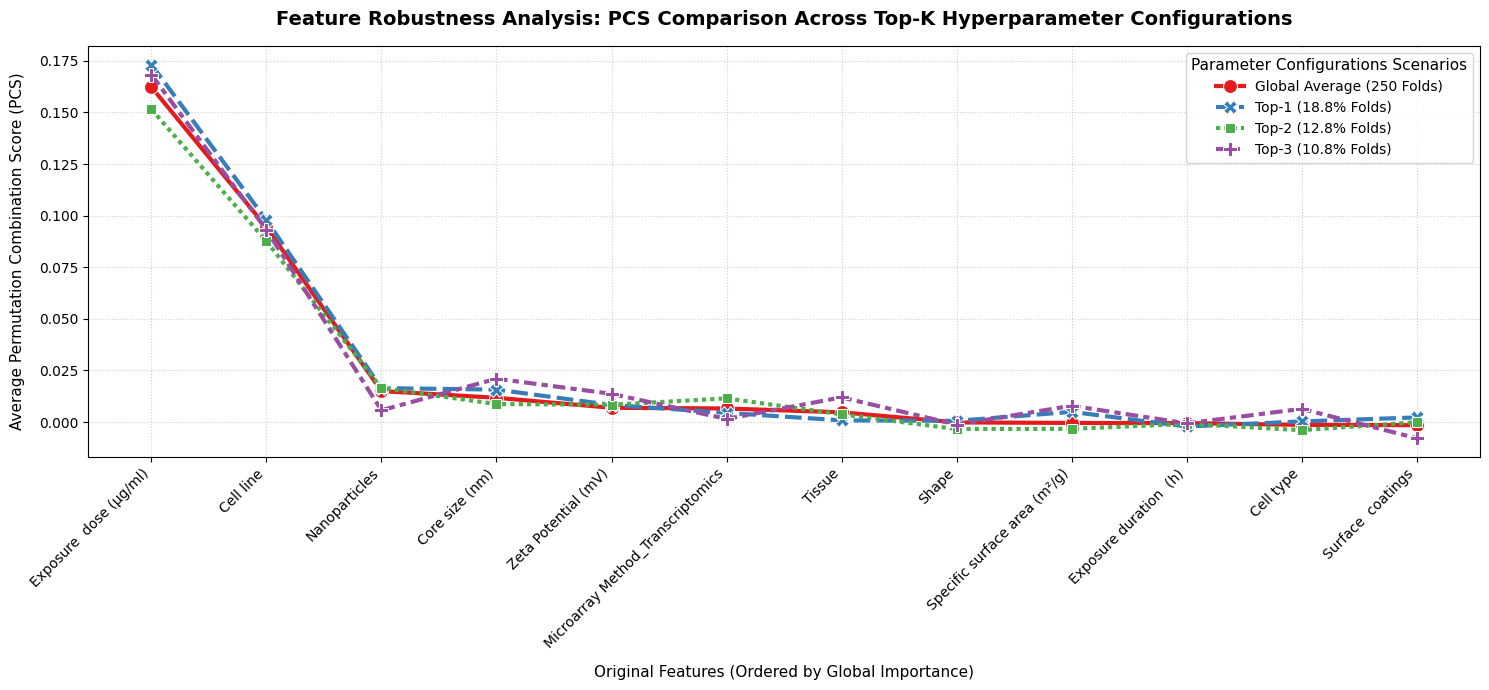


=== PCS FEATURE ROBUSTNESS COMPARISON TABLE===


Weighting_Scenario,Global Average (250 Folds),Top-1 (18.8% Folds),Top-2 (12.8% Folds),Top-3 (10.8% Folds)
Original_Feature,,,,
Exposure dose (μg/ml),0.162316,0.173240,0.151556,0.168306
Cell line,0.094427,0.097830,0.087636,0.093149
Nanoparticles,0.014996,0.016424,0.016440,0.005680
Core size (nm),0.011742,0.015709,0.008696,0.020978
Zeta Potential (mV),0.006885,0.008267,0.008375,0.013658
Microarray Method_Transcriptomics,0.006558,0.004438,0.011449,0.001505
Tissue,0.004694,0.000791,0.003706,0.011946
Shape,-0.000191,0.000563,-0.003409,-0.001259
Specific surface area (m²/g),-0.000452,0.004920,-0.003310,0.007861



The feature robustness comparison results were successfully saved to 'comparison_of_pfi_and_pcs_based_on_top_k_parameters.xlsx'


In [104]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load evaluation and PFI detail data from 250 runs
df_results = pd.read_excel('repeated_25x_cv_detailed_results.xlsx')
df_pfi_det = pd.read_excel('repeated_25x_cv_pfi_detailed.xlsx')

# Remove whitespace from column names, if any
df_results['Best_Params'] = df_results['Best_Params'].str.strip()
df_pfi_det['Feature'] = df_pfi_det['Feature'].str.strip()

# 2.Define a local helper function to map the sub-features resulting from preprocessing to the 12 original features
def get_original_feature_name_local(feature_name):
    if feature_name.startswith('num__'):
        return feature_name[5:]
    elif feature_name.startswith('cat__'):
        parts = feature_name[5:].split('_', 1)
        original_name = parts[0]
        if 'Microarray Method' in feature_name:
            return 'Microarray Method_Transcriptomics'
        return original_name
    return feature_name

df_pfi_det['Original_Feature'] = df_pfi_det['Feature'].apply(get_original_feature_name_local)

# Aggregate (sum) the PFI contributions of sub-features into a PCS value per (Repeat, Fold, Original_Feature)
df_pcs_by_fold = df_pfi_det.groupby(['Repeat', 'Fold', 'Original_Feature'])['Importance'].sum().reset_index()
df_pcs_by_fold.rename(columns={'Importance': 'PCS_j'}, inplace=True)

# Combine with the Best_Params configuration of each fold
df_merged_pcs = pd.merge(
    df_pcs_by_fold,
    df_results[['Repeat', 'Fold', 'Best_Params']],
    on=['Repeat', 'Fold'],
    how='inner'
)

# 3. Get the top 3 most popular parameters
top_k_params = df_results['Best_Params'].value_counts().head(3).index.tolist()
top_k_labels = ['Top-1 (18.8% Folds)', 'Top-2 (12.8% Folds)', 'Top-3 (10.8% Folds)']

print("=== TOP-3 CONFIGURATIONS IDENTIFIED ===")
for idx, param in enumerate(top_k_params):
    print(f"{top_k_labels[idx]}: {param}")

# 4. Calculate the average PCS for each original feature under each of the Top-K parameters
pcs_robustness_records = []

for idx, param in enumerate(top_k_params):
    # Filter the fold data that uses this parameter
    df_filtered_param = df_merged_pcs[df_merged_pcs['Best_Params'] == param]

    # Calculate the average PCS for the 12 original features
    df_mean_pcs = df_filtered_param.groupby('Original_Feature')['PCS_j'].mean().reset_index()

    for _, row in df_mean_pcs.iterrows():
        pcs_robustness_records.append({
            'Original_Feature': row['Original_Feature'],
            'Weighting_Scenario': top_k_labels[idx],
            'Mean_PCS': row['PCS_j']
        })

df_robust_pcs = pd.DataFrame(pcs_robustness_records)

# Add the global average (across all 250 folds) as a baseline for comparison
df_pcs_global = df_merged_pcs.groupby('Original_Feature')['PCS_j'].mean().reset_index()
for _, row in df_pcs_global.iterrows():
    df_robust_pcs = pd.concat([df_robust_pcs, pd.DataFrame([{
        'Original_Feature': row['Original_Feature'],
        'Weighting_Scenario': 'Global Average (250 Folds)',
        'Mean_PCS': row['PCS_j']
    }])], ignore_index=True)

# 5.Visualizing Feature Robustness Using Line Plots
# Sort features based on their highest global average values ​​for x-axis consistency
feature_order = df_pcs_global.sort_values(by='PCS_j', ascending=False)['Original_Feature'].tolist()
df_robust_pcs['Original_Feature'] = pd.Categorical(
    df_robust_pcs['Original_Feature'],
    categories=feature_order,
    ordered=True
)
df_robust_pcs = df_robust_pcs.sort_values(by=['Original_Feature', 'Weighting_Scenario']).reset_index(drop=True)

plt.figure(figsize=(15, 7))
# Using the 'Set1' palette, which features very sharp color contrasts and significant differentiation between the lines
sns.lineplot(
    data=df_robust_pcs,
    x='Original_Feature',
    y='Mean_PCS',
    hue='Weighting_Scenario',
    style='Weighting_Scenario',
    markers=True,
    dashes=True, # Enable different dash styles to enhance visual contrast
    linewidth=3.0,
    markersize=10,
    palette='Set1'
)

plt.title('Feature Robustness Analysis: PCS Comparison Across Top-K Hyperparameter Configurations', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Original Features (Ordered by Global Importance)', fontsize=11, labelpad=10)
plt.ylabel('Average Permutation Combination Score (PCS)', fontsize=11, labelpad=10)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(title='Parameter Configurations Scenarios', fontsize=10, title_fontsize=11, loc='upper right')
plt.tight_layout()
plt.show()

# 6. Create a pivot table and save it to an Excel file
df_robust_pivot = df_robust_pcs.pivot(index='Original_Feature', columns='Weighting_Scenario', values='Mean_PCS').reindex(feature_order)
df_robust_pivot = df_robust_pivot[['Global Average (250 Folds)', 'Top-1 (18.8% Folds)', 'Top-2 (12.8% Folds)', 'Top-3 (10.8% Folds)']]

print("\n=== PCS FEATURE ROBUSTNESS COMPARISON TABLE===")
display(df_robust_pivot)

output_excel_robust = 'comparison_of_pfi_and_pcs_based_on_top_k_parameters.xlsx'
df_robust_pivot.to_excel(output_excel_robust, index=True)
print(f"\nThe feature robustness comparison results were successfully saved to '{output_excel_robust}'")

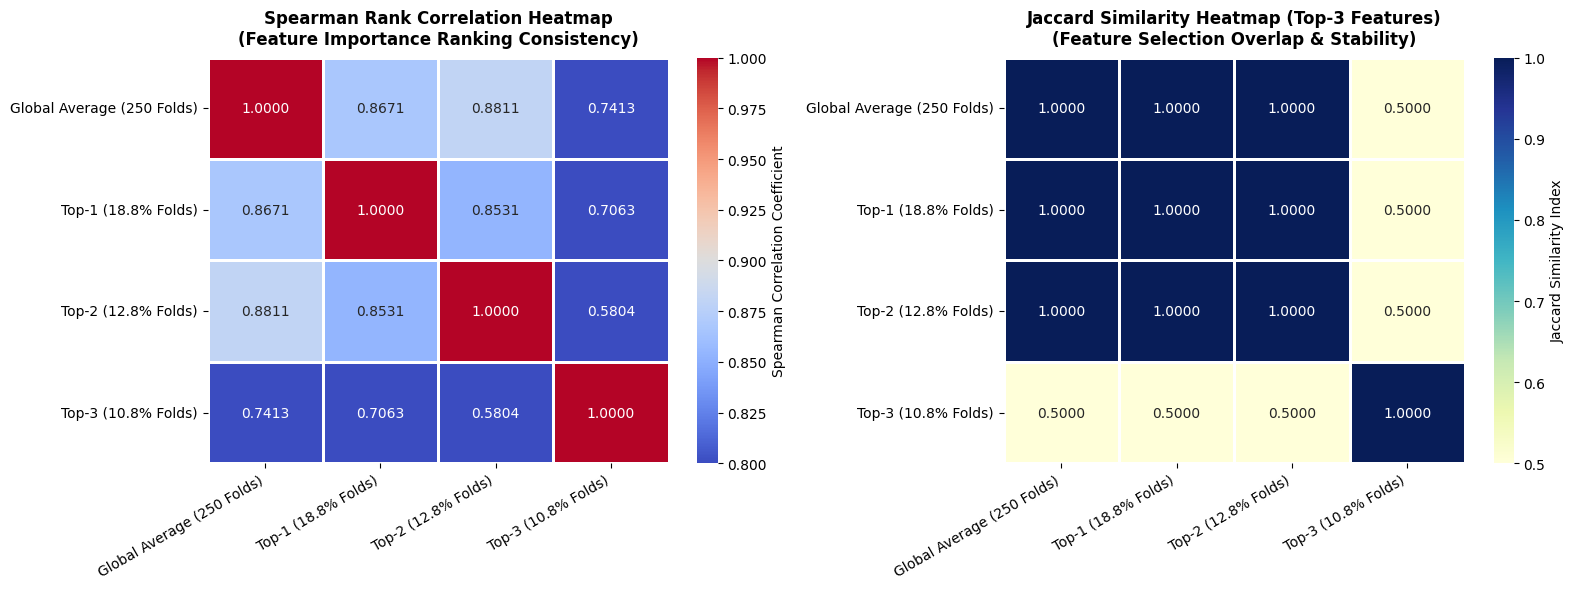

=== SPEARMAN CORRELATION MATRIX OF FEATURE ROBUSTNESS ===


,Global Average (250 Folds),Top-1 (18.8% Folds),Top-2 (12.8% Folds),Top-3 (10.8% Folds)
Global Average (250 Folds),1.000000,0.867133,0.881119,0.741259
Top-1 (18.8% Folds),0.867133,1.000000,0.853147,0.706294
Top-2 (12.8% Folds),0.881119,0.853147,1.000000,0.580420
Top-3 (10.8% Folds),0.741259,0.706294,0.580420,1.000000



=== JACCARD SIMILARITY MATRIX (TOP-3 KEY FEATURES) ===


,Global Average (250 Folds),Top-1 (18.8% Folds),Top-2 (12.8% Folds),Top-3 (10.8% Folds)
Global Average (250 Folds),1.0,1.0,1.0,0.5
Top-1 (18.8% Folds),1.0,1.0,1.0,0.5
Top-2 (12.8% Folds),1.0,1.0,1.0,0.5
Top-3 (10.8% Folds),0.5,0.5,0.5,1.0



The results of the Spearman and Jaccard stability analysis were successfully saved to 'spearman_jaccard_robustness_analysis.xlsx'


In [105]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

# 1. Define a function to calculate Jaccard Similarity for the top K features
def jaccard_similarity(list1, list2):
    intersection = len(set(list1).intersection(set(list2)))
    union = len(set(list1).union(set(list2)))
    return intersection / union if union > 0 else 0.0

# 2. Prepare the data from the previous robustness pivot table (df_robust_pivot)
# Ensure that the scenario columns are correctly retrieved
scenarios = ['Global Average (250 Folds)', 'Top-1 (18.8% Folds)', 'Top-2 (12.8% Folds)', 'Top-3 (10.8% Folds)']

# Determine the ranking based on the PCS score for each scenario
df_ranks = df_robust_pivot[scenarios].rank(ascending=False, method='min')

# 3. Calculate Spearman Correlation Matrix
spearman_matrix = pd.DataFrame(index=scenarios, columns=scenarios, dtype=float)
for s1 in scenarios:
    for s2 in scenarios:
        coef, _ = spearmanr(df_robust_pivot[s1], df_robust_pivot[s2])
        spearman_matrix.loc[s1, s2] = coef

# 4. Calculate the Jaccard Similarity Matrix for the Top-3 Key Features
top_k_selection = 3
jaccard_matrix = pd.DataFrame(index=scenarios, columns=scenarios, dtype=float)

top_features_dict = {}
for s in scenarios:

# Take the top 3 feature names with the highest PCS scores
    top_features_dict[s] = df_robust_pivot[s].sort_values(ascending=False).head(top_k_selection).index.tolist()

for s1 in scenarios:
    for s2 in scenarios:
        jaccard_matrix.loc[s1, s2] = jaccard_similarity(top_features_dict[s1], top_features_dict[s2])

# 5. Side-by-Side Heatmap Visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Heatmap Spearman
sns.heatmap(
    spearman_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.4f',
    vmin=0.8,
    vmax=1.0,
    ax=axes[0],
    cbar_kws={'label': 'Spearman Correlation Coefficient'},
    linewidths=1,
    linecolor='white'
)
axes[0].set_title('Spearman Rank Correlation Heatmap\n(Feature Importance Ranking Consistency)', fontsize=12, fontweight='bold', pad=10)
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=30, ha='right')

# Heatmap Jaccard
sns.heatmap(
    jaccard_matrix,
    annot=True,
    cmap='YlGnBu',
    fmt='.4f',
    vmin=0.5,
    vmax=1.0,
    ax=axes[1],
    cbar_kws={'label': 'Jaccard Similarity Index'},
    linewidths=1,
    linecolor='white'
)
axes[1].set_title(f'Jaccard Similarity Heatmap (Top-{top_k_selection} Features)\n(Feature Selection Overlap & Stability)', fontsize=12, fontweight='bold', pad=10)
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=30, ha='right')

plt.tight_layout()
plt.show()

# 6. Display Table Results in Textual Form
print("=== SPEARMAN CORRELATION MATRIX OF FEATURE ROBUSTNESS ===")
display(spearman_matrix)

print(f"\n=== JACCARD SIMILARITY MATRIX (TOP-{top_k_selection} KEY FEATURES) ===")
display(jaccard_matrix)

# 7. Save Results to a Multi-Sheet Excel File
output_file_validation = 'spearman_jaccard_robustness_analysis.xlsx'
with pd.ExcelWriter(output_file_validation, engine='openpyxl') as writer:
    spearman_matrix.to_excel(writer, sheet_name='Spearman_Correlation')
    jaccard_matrix.to_excel(writer, sheet_name=f'Jaccard_Similarity_Top_{top_k_selection}')

print(f"\nThe results of the Spearman and Jaccard stability analysis were successfully saved to '{output_file_validation}'")

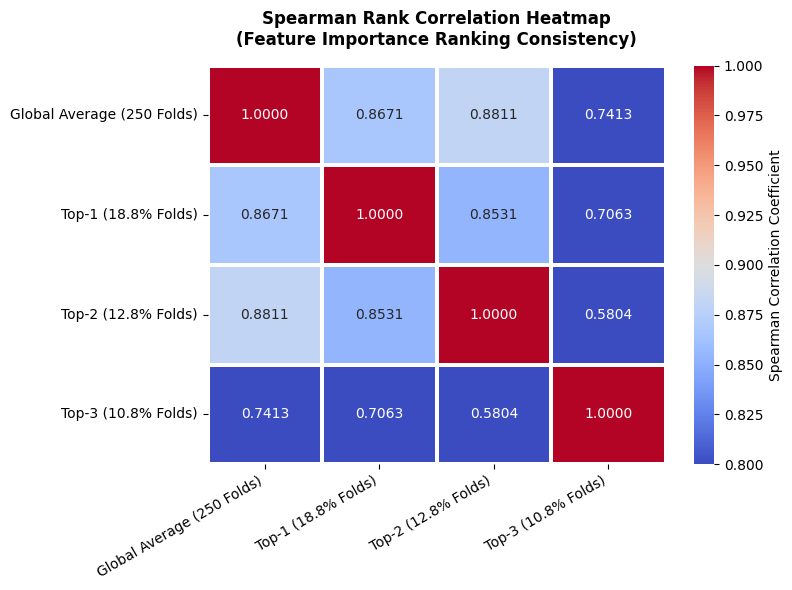

In [106]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.heatmap(
    spearman_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.4f',
    vmin=0.8,
    vmax=1.0,
    cbar_kws={'label': 'Spearman Correlation Coefficient'},
    linewidths=1.5,
    linecolor='white'
)
plt.title('Spearman Rank Correlation Heatmap\n(Feature Importance Ranking Consistency)', fontsize=12, fontweight='bold', pad=15)
plt.xticks(rotation=30, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

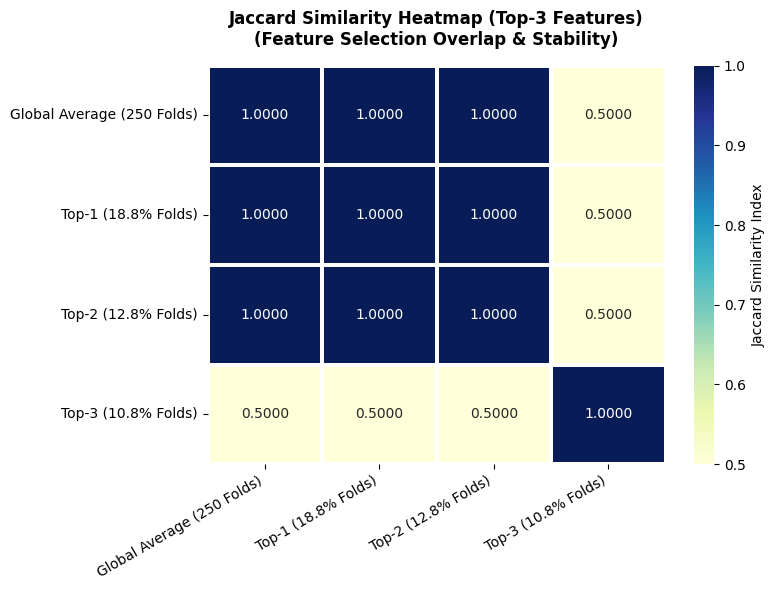

In [107]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.heatmap(
    jaccard_matrix,
    annot=True,
    cmap='YlGnBu',
    fmt='.4f',
    vmin=0.5,
    vmax=1.0,
    cbar_kws={'label': 'Jaccard Similarity Index'},
    linewidths=1.5,
    linecolor='white'
)
plt.title(f'Jaccard Similarity Heatmap (Top-{top_k_selection} Features)\n(Feature Selection Overlap & Stability)', fontsize=12, fontweight='bold', pad=15)
plt.xticks(rotation=30, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

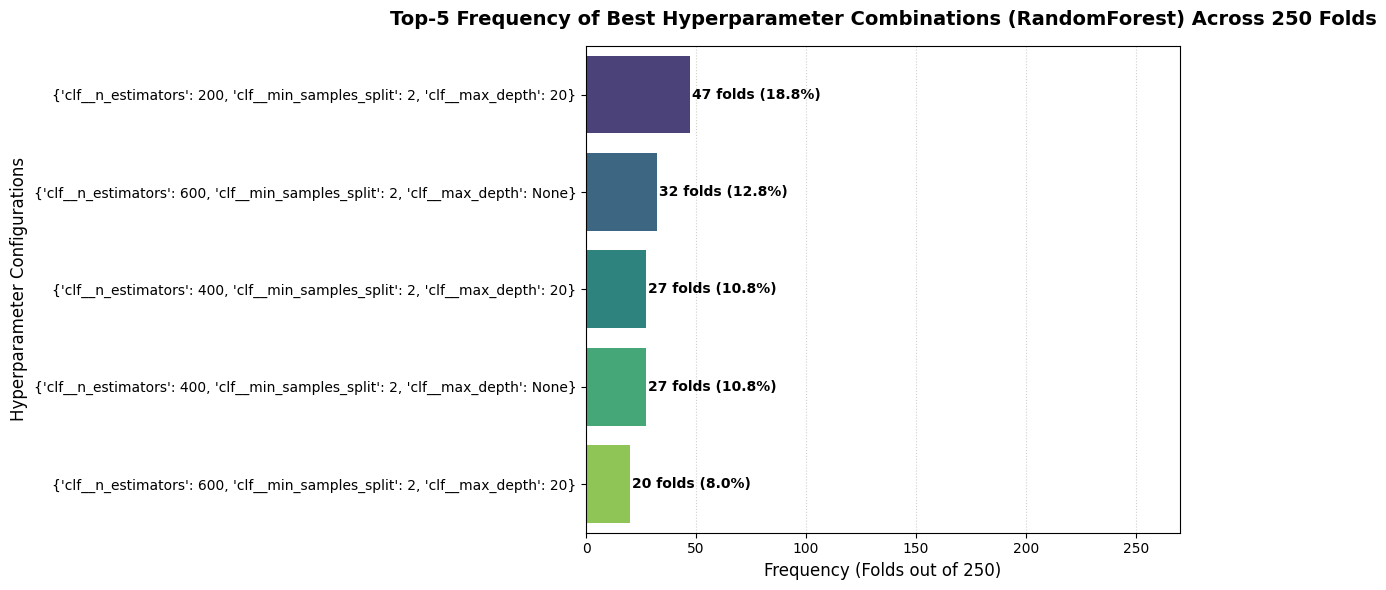

In [108]:
# 3. Top-K Frequency Visualization Using a Barplot
plt.figure(figsize=(12, 6))
sns.barplot(
    data=param_frequency.head(5),
    x='Frequency',
    y='Hyperparameters',
    palette='viridis',
    hue='Hyperparameters',
    legend=False
)

# Add percentage text annotation at the end of the bar
for idx, row in param_frequency.head(5).iterrows():
    plt.text(
        row['Frequency'] + 1,
        idx,
        f"{row['Frequency']} folds ({row['Percentage']:.1f}%)",
        va='center',
        fontsize=10,
        fontweight='bold'
    )

plt.title('Top-5 Frequency of Best Hyperparameter Combinations (RandomForest) Across 250 Folds', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Frequency (Folds out of 250)', fontsize=12)
plt.ylabel('Hyperparameter Configurations', fontsize=12)
plt.xlim(0, 270)
plt.grid(axis='x', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

In [111]:
import pandas as pd
import numpy as np

# 1. Load the summary results from the Nested CV
# Adjusted to use 'nested_cv_summary_results.xlsx' which is the correct file present in the workspace
df_ncv_sum = pd.read_excel('nested_cv_summary_results.xlsx')
ncv_best = df_ncv_sum[(df_ncv_sum['Imputation'] == 'IIBR') & (df_ncv_sum['Classifier'] == 'RandomForest')].copy()

# 2. Load detailed results from 25x Repeated CV (250 runs)
df_rep_det = pd.read_excel('repeated_25x_cv_detailed_results.xlsx')

# Calculate the mean and standard deviation directly for additional metrics
rep_err_mean = (1 - df_rep_det['Accuracy']).mean()
rep_err_std = (1 - df_rep_det['Accuracy']).std()

# 3. Obtain specific values from Nested CV
ncv_acc_mean = ncv_best['Accuracy_OuterVal_mean'].values[0]
ncv_acc_std = ncv_best['Accuracy_OuterVal_std'].values[0]

ncv_err_mean = 1 - ncv_acc_mean
ncv_err_std = ncv_acc_std

# Organize all metrics into a dictionary
compare_metrics_extended = {
    'Metric': [
        'Accuracy (Mean)', 'Accuracy (Std)',
        'AUC (Mean)', 'AUC (Std)',
        'F1-Score (Mean)', 'F1-Score (Std)',
        'Precision (Mean)', 'Precision (Std)',
        'Sensitivity (Mean)', 'Sensitivity (Std)',
        'Specificity (Mean)', 'Specificity (Std)',
        'Classification Error (Mean)', 'Classification Error (Std)'
    ],
    '10-Fold Nested CV (10 runs)': [
        ncv_acc_mean,
        ncv_acc_std,
        ncv_best['AUC_OuterVal_mean'].values[0],
        ncv_best['AUC_OuterVal_std'].values[0],
        ncv_best['F1_OuterVal_mean'].values[0],
        ncv_best['F1_OuterVal_std'].values[0],
        ncv_best['Precision_OuterVal_mean'].values[0],
        ncv_best['Precision_OuterVal_std'].values[0],
        ncv_best['Sensitivity_OuterVal_mean'].values[0],
        ncv_best['Sensitivity_OuterVal_std'].values[0],
        ncv_best['Specificity_OuterVal_mean'].values[0],
        ncv_best['Specificity_OuterVal_std'].values[0],
        ncv_err_mean,
        ncv_err_std
    ],
    '25x Repeated 10-Fold CV (250 runs)': [
        df_rep_det['Accuracy'].mean(),
        df_rep_det['Accuracy'].std(),
        df_rep_det['AUC'].mean(),
        df_rep_det['AUC'].std(),
        df_rep_det['F1'].mean(),
        df_rep_det['F1'].std(),
        df_rep_det['Precision'].mean(),
        df_rep_det['Precision'].std(),
        df_rep_det['Sensitivity'].mean(),
        df_rep_det['Sensitivity'].std(),
        df_rep_det['Specificity'].mean(),
        df_rep_det['Specificity'].std(),
        rep_err_mean,
        rep_err_std
    ]
}

df_compare_extended = pd.DataFrame(compare_metrics_extended)

for col in ['10-Fold Nested CV (10 runs)', '25x Repeated 10-Fold CV (250 runs)']:
    df_compare_extended[col] = df_compare_extended[col].apply(lambda x: f'{x:.2%}' if pd.notna(x) else 'N/A')

print('=== COMPREHENSIVE COMPARISON OF PERFORMANCE METRICS FOR THE BEST MODEL (IIBR + RandomForest) ===')
display(df_compare_extended)

# Save comparison results to Excel
df_compare_extended.to_excel('comprehensive_validation_comparison.xlsx', index=False)
print("The comprehensive comparison results were successfully saved to 'comprehensive_validation_comparison.xlsx'")

=== COMPREHENSIVE COMPARISON OF PERFORMANCE METRICS FOR THE BEST MODEL (IIBR + RandomForest) ===


,Metric,10-Fold Nested CV (10 runs),25x Repeated 10-Fold CV (250 runs)
0,Accuracy (Mean),91.11%,90.53%
1,Accuracy (Std),5.14%,5.59%
2,AUC (Mean),97.09%,96.56%
3,AUC (Std),4.26%,3.79%
4,F1-Score (Mean),91.07%,90.46%
5,F1-Score (Std),5.16%,5.65%
6,Precision (Mean),91.88%,91.17%
7,Precision (Std),4.56%,5.36%
8,Sensitivity (Mean),91.11%,90.53%
9,Sensitivity (Std),5.14%,5.59%


The comprehensive comparison results were successfully saved to 'comprehensive_validation_comparison.xlsx'


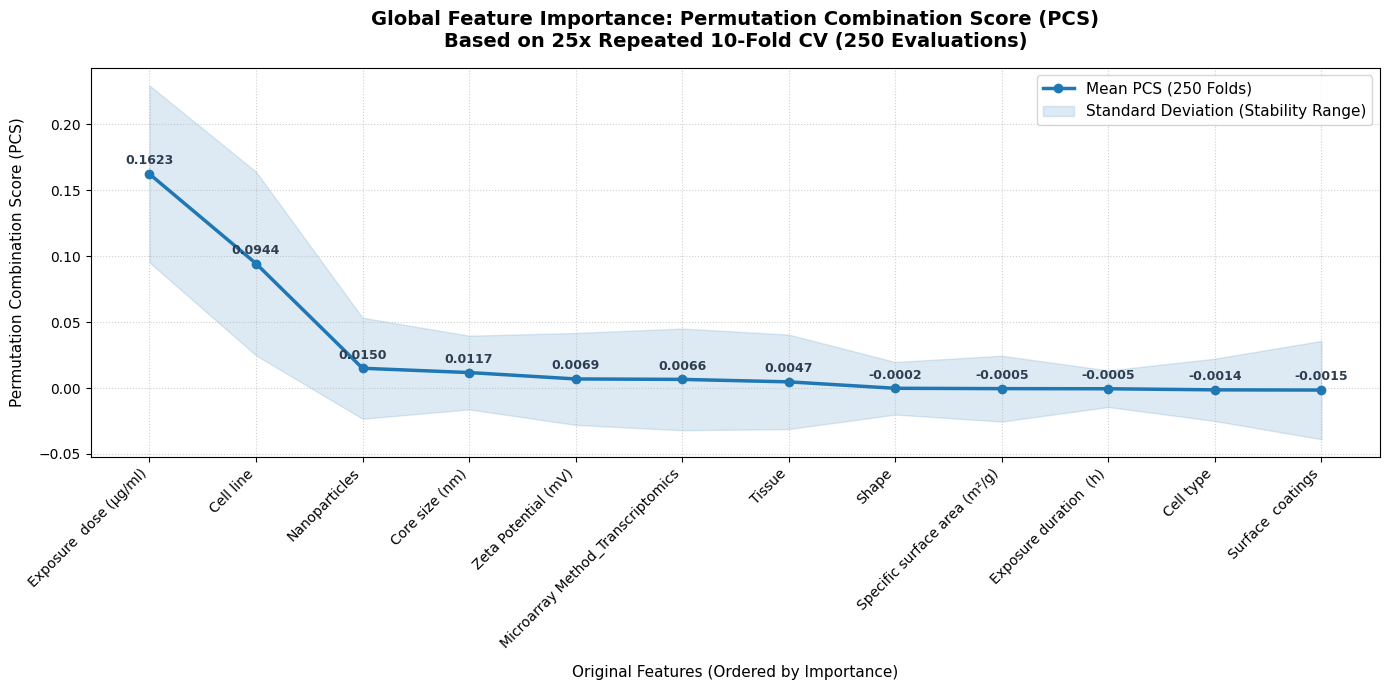


=== PCS DATA TABLE (AGGREGATION OF 250 FOLDS) ===


,Rank,Original_Feature,Mean_PCS,Std_PCS
0,1,Exposure dose (μg/ml),0.162316,0.067090
1,2,Cell line,0.094427,0.069608
2,3,Nanoparticles,0.014996,0.038305
3,4,Core size (nm),0.011742,0.027947
4,5,Zeta Potential (mV),0.006885,0.034845
5,6,Microarray Method_Transcriptomics,0.006558,0.038558
6,7,Tissue,0.004694,0.035819
7,8,Shape,-0.000191,0.019927
8,9,Specific surface area (m²/g),-0.000452,0.024954
9,10,Exposure duration (h),-0.000549,0.013846


In [113]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Load PCS summary results of 250 folds (25 repeats x 10 folds)
# Diubah ke nama file yang valid di workspace: repeated_25x_cv_pcs_original_summary_final.xlsx
df_pcs_summary = pd.read_excel('repeated_25x_cv_pcs_original_summary_final.xlsx')

# Sort by Mean_PCS from highest to lowest
df_pcs_summary = df_pcs_summary.sort_values(by='Mean_PCS', ascending=False).reset_index(drop=True)

# 2. Setup visualisasi
plt.figure(figsize=(14, 7))

# Create a main line plot for Mean_PCS
plt.plot(
    df_pcs_summary['Original_Feature'],
    df_pcs_summary['Mean_PCS'],
    marker='o',
    linewidth=2.5,
    color='#1f77b4',
    label='Mean PCS (250 Folds)'
)

# Adding fill_between to represent the Standard Deviation (Std_PCS) as a shaded band
plt.fill_between(
    df_pcs_summary['Original_Feature'],
    df_pcs_summary['Mean_PCS'] - df_pcs_summary['Std_PCS'],
    df_pcs_summary['Mean_PCS'] + df_pcs_summary['Std_PCS'],
    color='#1f77b4',
    alpha=0.15,
    label='Standard Deviation (Stability Range)'
)

# Adding text value annotations at each point
for i, row in df_pcs_summary.iterrows():
    plt.text(
        i,
        row['Mean_PCS'] + 0.005,
        f"{row['Mean_PCS']:.4f}",
        ha='center',
        va='bottom',
        fontsize=9,
        fontweight='bold',
        color='#2c3e50'
    )

# Graphic aesthetic customization
plt.title('Global Feature Importance: Permutation Combination Score (PCS)\nBased on 25x Repeated 10-Fold CV (250 Evaluations)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Original Features (Ordered by Importance)', fontsize=11, labelpad=10)
plt.ylabel('Permutation Combination Score (PCS)', fontsize=11, labelpad=10)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=11, loc='upper right')
plt.tight_layout()

# Show graph
plt.show()

# Display the data table below for precise reference
print("\n=== PCS DATA TABLE (AGGREGATION OF 250 FOLDS) ===")
display(df_pcs_summary)

In [115]:
import pandas as pd
import numpy as np
import os
import glob

# Prioritizing the loading of variables directly from kernel memory
df_pfi_rep = None
df_pcs_rep = None

# Examining alternative memory variable names for PFI
if 'df_repeated_pfi_original' in globals() and globals()['df_repeated_pfi_original'] is not None:
    df_pfi_rep = globals()['df_repeated_pfi_original'].copy()
    print("-> Successfully loaded PFI directly from the kernel's global memory (df_repeated_pfi_original).")
elif 'df_repeated_pfi_summary' in globals() and globals()['df_repeated_pfi_summary'] is not None:
    df_pfi_rep = globals()['df_repeated_pfi_summary'].copy()
    print("-> Successfully loaded PFI directly from the kernel's global memory (df_repeated_pfi_summary).")
else:
    # Fallback to physical file search
    pfi_candidates = glob.glob('*pfi*original_summary*.xlsx') + glob.glob('*pfi*summary*.xlsx')
    pfi_file = pfi_candidates[0] if pfi_candidates else 'repeated_25x_cv_pfi_original_summary.xlsx'
    if os.path.exists(pfi_file):
        df_pfi_rep = pd.read_excel(pfi_file)
        print(f"-> Successfully loaded PFI from file: {pfi_file}")

# Examining alternative memory variable names for PCS
if 'df_pcs_summary' in globals() and globals()['df_pcs_summary'] is not None:
    df_pcs_rep = globals()['df_pcs_summary'].copy()
    print("-> Successfully loaded PCS directly from the kernel's global memory (df_pcs_summary).")
elif 'df_pcs_final_summary' in globals() and globals()['df_pcs_final_summary'] is not None:
    df_pcs_rep = globals()['df_pcs_final_summary'].copy()
    print("-> Successfully loaded PCS directly from the kernel's global memory (df_pcs_final_summary).")
else:
    # Fallback to physical file search
    pcs_candidates = glob.glob('*pcs*original_summary*.xlsx') + glob.glob('*pcs*summary*.xlsx')
    pcs_file = pcs_candidates[0] if pcs_candidates else 'repeated_25x_cv_pcs_original_summary_final.xlsx'
    if os.path.exists(pcs_file):
        df_pcs_rep = pd.read_excel(pcs_file)
        print(f"-> Successfully loaded PCS from file: {pcs_file}")

# Execute the merge if both datasets are successfully loaded
if df_pfi_rep is not None and df_pcs_rep is not None:
    # Normalize text features to ensure perfect matching
    df_pfi_rep['Original_Feature'] = df_pfi_rep['Original_Feature'].astype(str).str.strip()
    df_pcs_rep['Original_Feature'] = df_pcs_rep['Original_Feature'].astype(str).str.strip()

    # Aligning column names
    pfi_cols = {'Mean_PFI': 'PFI_Repeated_Mean', 'Std_PFI': 'PFI_Repeated_Std', 'Rank': 'PFI_Rank'}
    pcs_cols = {'Mean_PCS': 'PCS_Repeated_Mean', 'Std_PCS': 'PCS_Repeated_Std', 'Rank': 'PCS_Rank'}

    # availability of column names before renaming
    pfi_rename = {k: v for k, v in pfi_cols.items() if k in df_pfi_rep.columns}
    pcs_rename = {k: v for k, v in pcs_cols.items() if k in df_pcs_rep.columns}

    df_comparison_matrix = pd.merge(
        df_pfi_rep[['Original_Feature'] + list(pfi_rename.keys())].rename(columns=pfi_rename),
        df_pcs_rep[['Original_Feature'] + list(pcs_rename.keys())].rename(columns=pcs_rename),
        on='Original_Feature',
        how='outer'
    )

    # Sort by PCS ranking performance to facilitate analysis
    sort_col = 'PCS_Rank' if 'PCS_Rank' in df_comparison_matrix.columns else 'Original_Feature'
    df_comparison_matrix = df_comparison_matrix.sort_values(by=sort_col).reset_index(drop=True)

    print("\n=== COMPARISON MATRIX: PFI REPEATED VS PCS REPEATED (250 EVALUATIONS) ===")
    display(df_comparison_matrix)

    # Export final results to Excel
    df_comparison_matrix.to_excel('comparison_of_pfi_vs_pcs_matrices_repeated.xlsx', index=False)
    print("\n[SUCCESS] Comparison matrix successfully exported to 'komparasi_matriks_pfi_vs_pcs_repeated'.xlsx'")
else:
    print("[ERROR] Failed to load data.")

-> Successfully loaded PFI directly from the kernel's global memory (df_repeated_pfi_original).
-> Successfully loaded PCS directly from the kernel's global memory (df_pcs_summary).

=== COMPARISON MATRIX: PFI REPEATED VS PCS REPEATED (250 EVALUATIONS) ===


,Original_Feature,PFI_Repeated_Mean,PFI_Repeated_Std,PFI_Rank,PCS_Repeated_Mean,PCS_Repeated_Std,PCS_Rank
0,Exposure dose (μg/ml),0.162316,0.067090,1,0.162316,0.067090,1
1,Cell line,0.094501,0.013680,2,0.094427,0.069608,2
2,Nanoparticles,0.014996,0.008050,3,0.014996,0.038305,3
3,Core size (nm),0.011742,0.027947,4,0.011742,0.027947,4
4,Zeta Potential (mV),0.006885,0.034845,6,0.006885,0.034845,5
5,Microarray Method_Transcriptomics,0.010038,0.018740,5,0.006558,0.038558,6
6,Tissue,0.004694,0.008190,7,0.004694,0.035819,7
7,Shape,-0.000191,0.005990,8,-0.000191,0.019927,8
8,Specific surface area (m²/g),-0.000452,0.024954,9,-0.000452,0.024954,9
9,Exposure duration (h),-0.000549,0.013846,10,-0.000549,0.013846,10



[SUCCESS] Comparison matrix successfully exported to 'komparasi_matriks_pfi_vs_pcs_repeated'.xlsx'


In [116]:
# Aggregation of PFI results (Mean and Std Dev) across all 250 evaluations
import numpy as np
import pandas as pd

# Ensuring df_repeated_pfi_detailed is well-defined
if 'df_repeated_pfi_detailed' in globals() and not df_repeated_pfi_detailed.empty:
    df_repeated_pfi_summary = df_repeated_pfi_detailed.groupby('Feature').agg({
        'Importance': ['mean', 'std']
    }).reset_index()

    # Flattening multi-index columns
    df_repeated_pfi_summary.columns = ['Feature', 'Mean_PFI', 'Std_PFI']

    # Mapping function to the original features
    def get_original_feature_name_local(feature_name):
        if feature_name.startswith('num__'):
            return feature_name[5:]
        elif feature_name.startswith('cat__'):
            parts = feature_name[5:].split('_', 1)
            original_name = parts[0]
            if 'Microarray Method' in feature_name:
                return 'Microarray Method_Transcriptomics'
            return original_name
        return feature_name

    df_repeated_pfi_summary['Original_Feature'] = df_repeated_pfi_summary['Feature'].apply(get_original_feature_name_local)

    # Aggregation to level 12 of the original features (sum of Mean PFI and average Std PFI)
    df_repeated_pfi_original = df_repeated_pfi_summary.groupby('Original_Feature').agg({
        'Mean_PFI': 'sum',
        'Std_PFI': 'mean'
    }).reset_index().sort_values(by='Mean_PFI', ascending=False).reset_index(drop=True)

    df_repeated_pfi_original['Rank'] = np.arange(1, len(df_repeated_pfi_original) + 1)

    print("=== REPEATED PFI SUMMARY UNTUK 12 FITUR ASLI (250 FOLDS) ===")
    display(df_repeated_pfi_original)

    # Save results to Excel
    df_repeated_pfi_detailed.to_excel('repeated_25x_cv_pfi_detailed.xlsx', index=False)
    df_repeated_pfi_original.to_excel('repeated_25x_cv_pfi_original_summary.xlsx', index=False)
    print("Detailed results are saved to 'repeated_25x_cv_pfi_detailed'.xlsx'")
    print("The summary results of the original 12 features are saved to 'repeated_25x_cv_pfi_original_summary.xlsx'")
else:
    print("The variable 'df_repeated_pfi_detailed' was not found or is empty")

=== REPEATED PFI SUMMARY UNTUK 12 FITUR ASLI (250 FOLDS) ===


,Original_Feature,Mean_PFI,Std_PFI,Rank
0,Exposure dose (μg/ml),0.162316,0.067090,1
1,Cell line,0.094501,0.013680,2
2,Nanoparticles,0.014996,0.008050,3
3,Core size (nm),0.011742,0.027947,4
4,Microarray Method_Transcriptomics,0.010038,0.018740,5
5,Zeta Potential (mV),0.006885,0.034845,6
6,Tissue,0.004694,0.008190,7
7,Shape,-0.000191,0.005990,8
8,Specific surface area (m²/g),-0.000452,0.024954,9
9,Exposure duration (h),-0.000549,0.013846,10


Detailed results are saved to 'repeated_25x_cv_pfi_detailed'.xlsx'
The summary results of the original 12 features are saved to 'repeated_25x_cv_pfi_original_summary.xlsx'


In [119]:
import numpy as np
import pandas as pd

# Ensuring that detailed PFI data from 250 folds is available
if 'df_repeated_pfi_detailed' in globals() and not df_repeated_pfi_detailed.empty:
    print(f"Processing {len(df_repeated_pfi_detailed)} rows of PFI contributions from 250 folds...")

    # 1. Define a local helper function to map the sub-features resulting from preprocessing to the 12 original features
    def get_original_feature_name_local(feature_name):
        if feature_name.startswith('num__'):
            return feature_name[5:]
        elif feature_name.startswith('cat__'):
            parts = feature_name[5:].split('_', 1)
            original_name = parts[0]
            if 'Microarray Method' in feature_name:
                return 'Microarray Method_Transcriptomics'
            return original_name
        return feature_name

    df_pcs_calc = df_repeated_pfi_detailed.copy()
    df_pcs_calc['Original_Feature'] = df_pcs_calc['Feature'].apply(get_original_feature_name_local)

    # 2. Calculate PCS per Fold: Accumulate (sum) the PFI sub-feature values ​​for each Original_Feature across each (Repeat, Fold)
    # This yields 250 unique PCS values ​​for each of the 12 original features
    df_pcs_per_fold = df_pcs_calc.groupby(['Repeat', 'Fold', 'Original_Feature'])['Importance'].sum().reset_index()
    df_pcs_per_fold.rename(columns={'Importance': 'PCS_j'}, inplace=True)

    # 3. Calculate aggregate statistics (mean and standard deviation) from those 250 folds for each original feature
    df_pcs_summary = df_pcs_per_fold.groupby('Original_Feature')['PCS_j'].agg([
        ('Mean_PCS', 'mean'),
        ('Std_PCS', 'std')
    ]).reset_index()

    # Sort by highest Mean PCS and create a ranking
    df_pcs_summary = df_pcs_summary.sort_values(by='Mean_PCS', ascending=False).reset_index(drop=True)
    df_pcs_summary['Rank'] = np.arange(1, len(df_pcs_summary) + 1)

    df_pcs_summary = df_pcs_summary[['Rank', 'Original_Feature', 'Mean_PCS', 'Std_PCS']]

    print("\n=== PERMUTATION COMBINATION SCORE (PCS) UNTUK 12 FITUR ASLI (250 FOLDS) ===")
    display(df_pcs_summary)

    # 4. Export results
    df_pcs_per_fold.to_excel('repeated_25x_cv_pcs_per_fold_detailed.xlsx', index=False)
    df_pcs_summary.to_excel('repeated_25x_cv_pcs_original_summary.xlsx', index=False)
    print("\n[SUCCESS]")
    print("- PCS details per fold are saved to: 'repeated_25x_cv_pcs_per_fold_detailed.xlsx'")
    print("- The statistical summary of the 12 original features is saved to: 'repeated_25x_cv_pcs_original_summary.xlsx'")
else:
    print("[ERROR] The variable 'df_repeated_pfi_detailed' was not found")

Processing 19937 rows of PFI contributions from 250 folds...

=== PERMUTATION COMBINATION SCORE (PCS) UNTUK 12 FITUR ASLI (250 FOLDS) ===


,Rank,Original_Feature,Mean_PCS,Std_PCS
0,1,Exposure dose (μg/ml),0.162316,0.067090
1,2,Cell line,0.094427,0.069608
2,3,Nanoparticles,0.014996,0.038305
3,4,Core size (nm),0.011742,0.027947
4,5,Zeta Potential (mV),0.006885,0.034845
5,6,Microarray Method_Transcriptomics,0.006558,0.038558
6,7,Tissue,0.004694,0.035819
7,8,Shape,-0.000191,0.019927
8,9,Specific surface area (m²/g),-0.000452,0.024954
9,10,Exposure duration (h),-0.000549,0.013846



[SUCCESS]
- PCS details per fold are saved to: 'repeated_25x_cv_pcs_per_fold_detailed.xlsx'
- The statistical summary of the 12 original features is saved to: 'repeated_25x_cv_pcs_original_summary.xlsx'


In [149]:
# Converting result data into a DataFrame and calculating summary statistics
import pandas as pd
import os

# Recover results from repeated_results list if available, otherwise read from the saved Excel file
if 'repeated_results' in globals() and len(repeated_results) > 0:
    df_all_repeated = pd.DataFrame(repeated_results)
elif os.path.exists('repeated_25x_cv_detailed_results.xlsx'):
    df_all_repeated = pd.read_excel('repeated_25x_cv_detailed_results.xlsx')
else:
    raise NameError("The 'repeated_results' evaluation data could not be found in memory or in local storage.")

# Adding dummy columns for grouping if they do not exist in repeated_results
if 'Imputation' not in df_all_repeated.columns:
    df_all_repeated['Imputation'] = 'IIBR'
if 'Classifier' not in df_all_repeated.columns:
    df_all_repeated['Classifier'] = 'RandomForest'

# Aggregation of Mean and Standard Deviation
df_all_summary = df_all_repeated.groupby(['Imputation', 'Classifier']).agg({
    'Accuracy': ['mean', 'std'],
    'Precision': ['mean', 'std'],
    'Sensitivity': ['mean', 'std'],
    'F1': ['mean', 'std'],
    'Specificity': ['mean', 'std'],
    'AUC': ['mean', 'std'],
    'Error_Rate': ['mean', 'std']
})

# Flattening multi-index columns
df_all_summary.columns = ['_'.join(col).strip() for col in df_all_summary.columns.values]
df_all_summary = df_all_summary.reset_index()

print("=== SUMMARY OF 25X REPEATED RESAMPLING FOR IIBR + RandomForest ===")
display(df_all_summary)

# Save to Excel completely
df_all_repeated.to_excel("repeated_25x_cv_all_combinations_detailed.xlsx", index=False)
df_all_summary.to_excel("repeated_25x_cv_all_combinations_summary.xlsx", index=False)
print("\nResults are successfully saved to 'repeated_25x_cv_all_combinations_detailed.xlsx' and 'repeated_25x_cv_all_combinations_summary.xlsx'")

=== SUMMARY OF 25X REPEATED RESAMPLING FOR IIBR + RandomForest ===


,Imputation,Classifier,Accuracy_mean,Accuracy_std,Precision_mean,Precision_std,Sensitivity_mean,Sensitivity_std,F1_mean,F1_std,Specificity_mean,Specificity_std,AUC_mean,AUC_std,Error_Rate_mean,Error_Rate_std
0,IIBR,RandomForest,0.905265,0.055864,0.911714,0.053635,0.905265,0.055864,0.904579,0.056529,0.923282,0.072222,0.965636,0.03789,0.094735,0.055864



Results are successfully saved to 'repeated_25x_cv_all_combinations_detailed.xlsx' and 'repeated_25x_cv_all_combinations_summary.xlsx'


In [123]:
import pandas as pd
# Displaying 20 combinations of model evaluation results on the test data
display(results_df[['Imputation', 'Classifier', 'Accuracy', 'AUC', 'Precision', 'Sensitivity', 'F1']])

,Imputation,Classifier,Accuracy,AUC,Precision,Sensitivity,F1
0,SIMPLE,RandomForest,1.000000,1.000000,1.000000,1.000000,1.000000
1,SIMPLE,DecisionTree,0.947368,1.000000,0.952632,0.947368,0.947368
2,SIMPLE,SVM,0.736842,1.000000,0.830827,0.736842,0.721587
3,SIMPLE,NaiveBayes,0.842105,0.700000,0.881579,0.842105,0.839452
4,SIMPLE,ANN,0.736842,0.811111,0.830827,0.736842,0.721587
5,KNN,RandomForest,0.947368,1.000000,0.952153,0.947368,0.947074
6,KNN,DecisionTree,0.947368,1.000000,0.952632,0.947368,0.947368
7,KNN,SVM,0.736842,0.988889,0.830827,0.736842,0.721587
8,KNN,NaiveBayes,0.842105,0.700000,0.881579,0.842105,0.839452
9,KNN,ANN,0.736842,0.844444,0.830827,0.736842,0.721587


In [125]:
df_repeated = pd.DataFrame(repeated_results)

# Calculate summary statistics (mean and std) across all 250 evaluations
summary_repeated = df_repeated.agg({
    'Accuracy': ['mean', 'std'],
    'Precision': ['mean', 'std'],
    'Sensitivity': ['mean', 'std'],
    'F1': ['mean', 'std'],
    'Specificity': ['mean', 'std'],
    'AUC': ['mean', 'std']
}).T

print("=== SUMMARY OF EVALUATION METRICS FOR 25x REPEATED 10-FOLD CV ===")
display(summary_repeated)

# Save results
df_repeated.to_excel("repeated_25x_cv_detailed_results.xlsx", index=False)
summary_repeated.to_excel("repeated_25x_cv_summary.xlsx")
print("Detailed results are saved to 'repeated_25x_cv_detailed_results.xlsx'")
print("The summary statistics results are saved to 'repeated_25x_cv_summary.xlsx'")


=== SUMMARY OF EVALUATION METRICS FOR 25x REPEATED 10-FOLD CV ===


,mean,std
Accuracy,0.905265,0.055864
Precision,0.911714,0.053635
Sensitivity,0.905265,0.055864
F1,0.904579,0.056529
Specificity,0.923282,0.072222
AUC,0.965636,0.037890


Detailed results are saved to 'repeated_25x_cv_detailed_results.xlsx'
The summary statistics results are saved to 'repeated_25x_cv_summary.xlsx'


In [126]:
import numpy as np
import pandas as pd

def calculate_performance_weighted_pcs(pfi_df, acc_df):

    #Copy data
    pfi = pfi_df.copy()
    acc = acc_df.copy()

    combo = ["Imputation", "Classifier"]

    # Ensure that each combination has one ACC value
    if acc.duplicated(combo).any():
        raise ValueError("There must be one ACC value per combination.")

    if pfi.duplicated(combo + ["Feature"]).any():
        raise ValueError(
            "PFI must be a single value per feature and combination."
        )

    if acc["ACC"].isna().any() or pfi["PFI"].isna().any():
        raise ValueError("There is an empty ACC or PFI value.")

    if ((acc["ACC"] < 0) | (acc["ACC"] > 1)).any():
        raise ValueError("The ACC value must be between 0 and 1.")

    # 1. PFI normalization for each combination
    denominator = (
        pfi.groupby(combo)["PFI"]
        .transform(lambda x: x.abs().sum())
    )

    pfi["N_PFI"] = np.divide(
        pfi["PFI"],
        denominator,
        out=np.zeros(len(pfi), dtype=float),
        where=denominator.to_numpy() != 0
    )

    # 2. Calculate weights based on ACC
    total_acc = acc["ACC"].sum()

    if total_acc <= 0:
        raise ValueError("The ACC quantity must be greater than zero.")

    auc["Weight"] = auc["ACC"] / total_acc

    # 3. Combine the normalized PFI with weights
    result = pfi.merge(
        acc[combo + ["ACC", "Weight"]],
        on=combo,
        how="left",
        validate="many_to_one"
    )

    if result["Weight"].isna().any():
        raise ValueError(
            "There are PFI combinations that do not have an ACC value."
        )

    # 4. Calculate the weighted contribution
    result["Weighted_PFI"] = (
        result["Weight"] * result["N_PFI"]
    )

    # 5. Aggregate the PCS for each feature
    pcs = (
        result.groupby("Feature")["Weighted_PFI"]
        .sum()
        .rename("PCS_P")
        .reset_index()
        .sort_values("PCS_P", ascending=False)
        .reset_index(drop=True)
    )

    pcs["Rank"] = np.arange(1, len(pcs) + 1)

    return pcs, result, acc

In [127]:
import pandas as pd
import numpy as np

# Preparing input data for the weighting function
# 1. PFI DataFrame
pfi_input = df_permutation_importances[['Imputation', 'Classifier', 'Feature', 'mean']].copy()
pfi_input.columns = ['Imputation', 'Classifier', 'Feature', 'PFI']

# 2. Accuracy DataFrame (using the average accuracy from the nested CV summary)
acc_input = summary_nested_cv[['Imputation', 'Classifier', 'Accuracy_OuterVal_mean']].copy()
acc_input.columns = ['Imputation', 'Classifier', 'ACC']

# Run the performance weighting function
try:

    def calculate_performance_weighted_pcs_fixed(pfi_df, acc_df):
        pfi = pfi_df.copy()
        acc = acc_df.copy()
        combo = ["Imputation", "Classifier"]

        if acc.duplicated(combo).any():
            raise ValueError("There must be one ACC value per combination.")
        if pfi.duplicated(combo + ["Feature"]).any():
            raise ValueError("PFI must be a single value per feature and combination.")
        if acc["ACC"].isna().any() or pfi["PFI"].isna().any():
            raise ValueError("There is an empty ACC or PFI value.")
        if ((acc["ACC"] < 0) | (acc["ACC"] > 1)).any():
            raise ValueError("The ACC value must be between 0 and 1.")

        denominator = pfi.groupby(combo)["PFI"].transform(lambda x: x.abs().sum())
        pfi["N_PFI"] = np.divide(
            pfi["PFI"],
            denominator,
            out=np.zeros(len(pfi), dtype=float),
            where=denominator.to_numpy() != 0
        )

        total_acc = acc["ACC"].sum()
        if total_acc <= 0:
            raise ValueError("The ACC quantity must be greater than zero.")

        acc["Weight"] = acc["ACC"] / total_acc

        result = pfi.merge(
            acc[combo + ["ACC", "Weight"]],
            on=combo,
            how="left",
            validate="many_to_one"
        )

        if result["Weight"].isna().any():
            raise ValueError("There are PFI combinations that do not have an ACC value.")

        result["Weighted_PFI"] = result["Weight"] * result["N_PFI"]

        pcs = (
            result.groupby("Feature")["Weighted_PFI"]
            .sum()
            .rename("PCS_P")
            .reset_index()
            .sort_values("PCS_P", ascending=False)
            .reset_index(drop=True)
        )
        pcs["Rank"] = np.arange(1, len(pcs) + 1)
        return pcs, result, acc

    pcs_result, detailed_weighted_pfi, model_weights = calculate_performance_weighted_pcs_fixed(pfi_input, acc_input)

    print("=== 1. PERFORMANCE-WEIGHTED PCS MATRIX (PCS_P) ===")
    display(pcs_result.head(15))

    print("\n=== 2. MODEL WEIGHT BASED ON ACC ===")
    display(model_weights.sort_values(by='Weight', ascending=False))
except Exception as e:
    print("An error occurred while executing the function:", e)

=== 1. PERFORMANCE-WEIGHTED PCS MATRIX (PCS_P) ===


,Feature,PCS_P,Rank
0,num__Exposure dose (μg/ml),0.115940,1
1,cat__Cell line_MDDC,0.061604,2
2,num__Core size (nm),0.011386,3
3,num__Zeta Potential (mV),0.005932,4
4,num__Specific surface area (m²/g),0.003412,5
5,cat__Surface coatings_Lipid_bilayer,0.002962,6
6,cat__Surface coatings_none,0.002520,7
7,cat__Cell line_HMDM,0.002360,8
8,cat__Cell type_Normal,0.001624,9
9,cat__Cell line_CACO-2,0.001035,10



=== 2. MODEL WEIGHT BASED ON ACC ===


,Imputation,Classifier,ACC,Weight
3,IIBR,RandomForest,0.911067,0.057343
13,MICE,RandomForest,0.906917,0.057082
1,IIBR,DecisionTree,0.903162,0.056846
18,SIMPLE,RandomForest,0.902372,0.056796
11,MICE,DecisionTree,0.894466,0.056298
8,KNN,RandomForest,0.893478,0.056236
16,SIMPLE,DecisionTree,0.885178,0.055714
6,KNN,DecisionTree,0.880830,0.055440
19,SIMPLE,SVM,0.858103,0.054010
4,IIBR,SVM,0.858103,0.054010


In [128]:
import pandas as pd

# Defining the output filename
excel_output_path = "df_PCS_P_performance_weighted_results.xlsx"

# Saving both dataframes into a single Excel file with separate sheets
with pd.ExcelWriter(excel_output_path, engine='openpyxl') as writer:
    pcs_result.to_excel(writer, sheet_name='PCS_P_Weighted', index=False)
    model_weights.to_excel(writer, sheet_name='Model_Weights', index=False)

print(f"Success! The results of the PCS_P and Model Weight calculations have been saved to '{excel_output_path}'")

Success! The results of the PCS_P and Model Weight calculations have been saved to 'df_PCS_P_performance_weighted_results.xlsx'


In [129]:
import pandas as pd
import numpy as np

# function to map preprocessed feature names back to the original feature names
def get_original_feature_name(feature_name):
    if feature_name.startswith('num__'):
        return feature_name[5:]
    elif feature_name.startswith('cat__'):
        parts = feature_name[5:].split('_', 1)
        original_name = parts[0]
        if 'Microarray Method' in feature_name:
            return 'Microarray Method_Transcriptomics'
        return original_name
    else:
        return feature_name

# Copy the pre-calculated PCS_P matrix (81 features)
pcs_result_12 = pcs_result.copy()
pcs_result_12['Original_Feature'] = pcs_result_12['Feature'].apply(get_original_feature_name)

# Group and sum the PCS_P values ​​based on the original features
pcs_original_12 = pcs_result_12.groupby('Original_Feature')['PCS_P'].sum().rename('PCS_P').reset_index()

# Sort by highest to lowest PCS_P value and create a new ranking
pcs_original_12 = pcs_original_12.sort_values(by='PCS_P', ascending=False).reset_index(drop=True)
pcs_original_12['Rank'] = np.arange(1, len(pcs_original_12) + 1)

print("=== PCS_P MATRIX FOR 12 ORIGINAL FEATURES ===")
display(pcs_original_12)

# Save all complete worksheets into one Excel file
excel_output_path = "df_PCS_P_performance_weighted_results.xlsx"
with pd.ExcelWriter(excel_output_path, engine='openpyxl') as writer:
    # Sheet 1: The results for the 81 preprocessed features remain intact
    pcs_result.to_excel(writer, sheet_name='PCS_P_Weighted_81_Features', index=False)
    # Sheet 2: Aggregation Result of 12 Original Features
    pcs_original_12.to_excel(writer, sheet_name='PCS_P_Weighted_Original_12', index=False)
    # Sheet 3: Model Weighting Based on Accuracy
    model_weights.to_excel(writer, sheet_name='Model_Weights', index=False)

print(f"\nSuccess! The comparison results for the 12 original features have been saved to the sheet 'PCS_P_Weighted_Original_12' in the file '{excel_output_path}'")

=== PCS_P MATRIX FOR 12 ORIGINAL FEATURES ===


,Original_Feature,PCS_P,Rank
0,Exposure dose (μg/ml),0.115940,1
1,Cell line,0.065010,2
2,Core size (nm),0.011386,3
3,Surface coatings,0.006076,4
4,Zeta Potential (mV),0.005932,5
5,Specific surface area (m²/g),0.003412,6
6,Cell type,0.002077,7
7,Tissue,-0.000011,8
8,Shape,-0.000896,9
9,Exposure duration (h),-0.001182,10



Success! The comparison results for the 12 original features have been saved to the sheet 'PCS_P_Weighted_Original_12' in the file 'df_PCS_P_performance_weighted_results.xlsx'


In [130]:
import pandas as pd
import numpy as np

# 1. Extract the average outer validation accuracy for each model from `summary_nested_cv`
# The column used is 'Accuracy_OuterVal_mean'
df_acc_outer = summary_nested_cv[['Imputation', 'Classifier', 'Accuracy_OuterVal_mean']].copy()
df_acc_outer.columns = ['Imputation', 'Classifier', 'ACC_Outer']

# 2. Get the original PFI values ​​from df_permutation_importances
df_pfi_base = df_permutation_importances[['Imputation', 'Classifier', 'Feature', 'mean']].copy()
df_pfi_base.columns = ['Imputation', 'Classifier', 'Feature', 'PFI']

# 3. Perform PFI normalization locally per model combination so that the absolute sum = 1
combo_keys = ['Imputation', 'Classifier']
sum_abs_pfi = df_pfi_base.groupby(combo_keys)['PFI'].transform(lambda x: x.abs().sum())
df_pfi_base['Normalized_PFI'] = np.divide(
    df_pfi_base['PFI'],
    sum_abs_pfi,
    out=np.zeros(len(df_pfi_base), dtype=float),
    where=sum_abs_pfi.to_numpy() != 0
)

# 4. Calculate model weights based on ACC_Outer (Outer Validation Accuracy from NCV)
total_acc_outer = df_acc_outer['ACC_Outer'].sum()
df_acc_outer['Weight_Outer'] = df_acc_outer['ACC_Outer'] / total_acc_outer

# 5. Recombine PFI with outer validation weights
df_weighted_outer = df_pfi_base.merge(
    df_acc_outer,
    on=combo_keys,
    how='left'
)

df_weighted_outer['Weighted_PFI_Outer'] = df_weighted_outer['Weight_Outer'] * df_weighted_outer['Normalized_PFI']

# 6. Aggregate PCS_P_Outer for 81 preprocessed sub-features
pcs_outer_81 = (
    df_weighted_outer.groupby('Feature')['Weighted_PFI_Outer']
    .sum()
    .rename('PCS_P_Outer')
    .reset_index()
    .sort_values('PCS_P_Outer', ascending=False)
    .reset_index(drop=True)
)
pcs_outer_81['Rank_Outer'] = np.arange(1, len(pcs_outer_81) + 1)

# 7. Aggregate PCS_P_Outer for 12 original features
def get_original_feature_name_local(feature_name):
    if feature_name.startswith('num__'):
        return feature_name[5:]
    elif feature_name.startswith('cat__'):
        parts = feature_name[5:].split('_', 1)
        original_name = parts[0]
        if 'Microarray Method' in feature_name:
            return 'Microarray Method_Transcriptomics'
        return original_name
    return feature_name

pcs_outer_12_df = pcs_outer_81.copy()
pcs_outer_12_df['Original_Feature'] = pcs_outer_12_df['Feature'].apply(get_original_feature_name_local)
pcs_outer_12 = pcs_outer_12_df.groupby('Original_Feature')['PCS_P_Outer'].sum().reset_index()
pcs_outer_12 = pcs_outer_12.sort_values(by='PCS_P_Outer', ascending=False).reset_index(drop=True)
pcs_outer_12['Rank_Outer'] = np.arange(1, len(pcs_outer_12) + 1)

# Display hasil
print("=== TOP 12 ORIGINAL FEATURES BASED ON NESTED CROSS-VALIDATION (NCV) ACCURACY WEIGHTS ===")
display(pcs_outer_12)


=== TOP 12 ORIGINAL FEATURES BASED ON NESTED CROSS-VALIDATION (NCV) ACCURACY WEIGHTS ===


,Original_Feature,PCS_P_Outer,Rank_Outer
0,Exposure dose (μg/ml),0.115940,1
1,Cell line,0.065010,2
2,Core size (nm),0.011386,3
3,Surface coatings,0.006076,4
4,Zeta Potential (mV),0.005932,5
5,Specific surface area (m²/g),0.003412,6
6,Cell type,0.002077,7
7,Tissue,-0.000011,8
8,Shape,-0.000896,9
9,Exposure duration (h),-0.001182,10


In [131]:
excel_file = 'df_PCS_P_performance_weighted_results.xlsx'

try:
    with pd.ExcelWriter(excel_file, engine='openpyxl', mode='w') as writer:
        # Save the previous results (81 & 12 features) as well as the previous weights, if they are still present in the workspace
        if 'pcs_result' in globals():
            pcs_result.to_excel(writer, sheet_name='PCS_P_Weighted_81_Features', index=False)
        if 'pcs_original_12' in globals():
            pcs_original_12.to_excel(writer, sheet_name='PCS_P_Weighted_Original_12', index=False)
        if 'model_weights' in globals():
            model_weights.to_excel(writer, sheet_name='Model_Weights', index=False)

        # Add a new sheet for calculations based on Outer NCV
        pcs_outer_81.to_excel(writer, sheet_name='PCS_P_Outer_81_Features', index=False)
        pcs_outer_12.to_excel(writer, sheet_name='PCS_P_Outer_Original_12', index=False)
        df_acc_outer.to_excel(writer, sheet_name='Model_Weights_Outer_NCV', index=False)

    print(f"File Excel '{excel_file}' successfully updated with the addition of an Outer NCV-based sheet!")
except Exception as e:
    print("Failed to save to Excel:", e)


File Excel 'df_PCS_P_performance_weighted_results.xlsx' successfully updated with the addition of an Outer NCV-based sheet!


In [132]:
import pandas as pd

# 1. Loading Alpha-Weighted PCS (0.5)
df_alpha_0_5 = pd.read_excel('df_PFI_PCS_alpha_0_5_weighted_ranked.xlsx')
df_alpha_0_5['Original_Feature'] = df_alpha_0_5['Original_Feature'].str.strip()

# 2. Loading Performance-Weighted PCS (Outer NCV - 12 Original Features)
df_pcs_p_outer = pd.read_excel('df_PCS_P_performance_weighted_results.xlsx', sheet_name='PCS_P_Outer_Original_12')
df_pcs_p_outer['Original_Feature'] = df_pcs_p_outer['Original_Feature'].str.strip()

# 3. Merge the two DataFrames based on Original_Feature
df_comparison = pd.merge(
    df_alpha_0_5[['Original_Feature', 'PCS', 'Rank']].rename(columns={'PCS': 'PCS_Alpha_0.5', 'Rank': 'Rank_Alpha_0.5'}),
    df_pcs_p_outer[['Original_Feature', 'PCS_P_Outer', 'Rank_Outer']].rename(columns={'PCS_P_Outer': 'PCS_Performance_Outer', 'Rank_Outer': 'Rank_Performance_Outer'}),
    on='Original_Feature',
    how='outer'
)

# Sort by outer performance ranking
df_comparison = df_comparison.sort_values(by='Rank_Performance_Outer').reset_index(drop=True)

print("=== COMPARISON TABLE: ALPHA-WEIGHTED PCS (0.5) VS. PERFORMANCE-WEIGHTED PCS (OUTER NCV) ===")
display(df_comparison)

# Save to Excel
df_comparison.to_excel('pcs_alfa_vs_performance_comparison_table.xlsx', index=False)
print("\nThe comparison table has been successfully saved to 'tabel_perbandingan_pcs_alfa_vs_performa'.xlsx'")

=== COMPARISON TABLE: ALPHA-WEIGHTED PCS (0.5) VS. PERFORMANCE-WEIGHTED PCS (OUTER NCV) ===


,Original_Feature,PCS_Alpha_0.5,Rank_Alpha_0.5,PCS_Performance_Outer,Rank_Performance_Outer
0,Exposure dose (μg/ml),0.675107,1,0.115940,1
1,Cell line,0.505155,3,0.065010,2
2,Core size (nm),0.434984,4,0.011386,3
3,Surface coatings,0.280159,8,0.006076,4
4,Zeta Potential (mV),0.036082,10,0.005932,5
5,Specific surface area (m²/g),0.289179,7,0.003412,6
6,Cell type,0.510309,2,0.002077,7
7,Tissue,0.370157,5,-0.000011,8
8,Shape,0.505155,3,-0.000896,9
9,Exposure duration (h),0.276393,9,-0.001182,10



The comparison table has been successfully saved to 'tabel_perbandingan_pcs_alfa_vs_performa'.xlsx'


In [133]:
import pandas as pd

# 1. Loading Alpha-Weighted PCS (0.7)
df_alpha_0_7 = pd.read_excel('df_PFI_PCS_alpha_weighted_updated_ranks.xlsx')
df_alpha_0_7['Original_Feature'] = df_alpha_0_7['Original_Feature'].str.strip()

# 2. Loading Alpha-Weighted PCS (0.5)
df_alpha_0_5 = pd.read_excel('df_PFI_PCS_alpha_0_5_weighted_ranked.xlsx')
df_alpha_0_5['Original_Feature'] = df_alpha_0_5['Original_Feature'].str.strip()

# 3. Loading Alpha-Weighted PCS (0.3)
df_alpha_0_3 = pd.read_excel('df_PFI_PCS_alpha_0_3_weighted_ranked.xlsx')
df_alpha_0_3['Original_Feature'] = df_alpha_0_3['Original_Feature'].str.strip()

# 4. Loading Performance-Weighted PCS (Outer NCV - 12 Original Features)
df_pcs_p_outer = pd.read_excel('df_PCS_P_performance_weighted_results.xlsx', sheet_name='PCS_P_Outer_Original_12')
df_pcs_p_outer['Original_Feature'] = df_pcs_p_outer['Original_Feature'].str.strip()

# 5. Combine all DataFrames incrementally based on Original_Feature
df_compare_all = pd.merge(
    df_alpha_0_7[['Original_Feature', 'PCS', 'Rank']].rename(columns={'PCS': 'PCS_Alpha_0.7', 'Rank': 'Rank_Alpha_0.7'}),
    df_alpha_0_5[['Original_Feature', 'PCS', 'Rank']].rename(columns={'PCS': 'PCS_Alpha_0.5', 'Rank': 'Rank_Alpha_0.5'}),
    on='Original_Feature',
    how='outer'
)

df_compare_all = pd.merge(
    df_compare_all,
    df_alpha_0_3[['Original_Feature', 'PCS', 'Rank']].rename(columns={'PCS': 'PCS_Alpha_0.3', 'Rank': 'Rank_Alpha_0.3'}),
    on='Original_Feature',
    how='outer'
)

df_compare_all = pd.merge(
    df_compare_all,
    df_pcs_p_outer[['Original_Feature', 'PCS_P_Outer', 'Rank_Outer']].rename(columns={'PCS_P_Outer': 'PCS_Performance_Outer', 'Rank_Outer': 'Rank_Performance_Outer'}),
    on='Original_Feature',
    how='outer'
)

# Sort by outer performance ranking
df_compare_all = df_compare_all.sort_values(by='Rank_Performance_Outer').reset_index(drop=True)

print("=== COMPLETE PCS COMPARISON TABLE: ALPHA (0.7 / 0.5 / 0.3) VS PERFORMANCE-WEIGHTED ===")
display(df_compare_all)

# Save to Excel
output_filename_compare_all = 'complete_pcs_alfa_comparison_table_vs_performance.xlsx'
df_compare_all.to_excel(output_filename_compare_all, index=False)
print(f"\nThe complete comparison table was successfully saved to '{output_filename_compare_all}'")

=== COMPLETE PCS COMPARISON TABLE: ALPHA (0.7 / 0.5 / 0.3) VS PERFORMANCE-WEIGHTED ===


,Original_Feature,PCS_Alpha_0.7,Rank_Alpha_0.7,PCS_Alpha_0.5,Rank_Alpha_0.5,PCS_Alpha_0.3,Rank_Alpha_0.3,PCS_Performance_Outer,Rank_Performance_Outer
0,Exposure dose (μg/ml),0.805064,1,0.675107,1,0.545150,4,0.115940,1
1,Cell line,0.307216,3,0.505155,3,0.703093,2,0.065010,2
2,Core size (nm),0.303258,4,0.434984,4,0.566709,3,0.011386,3
3,Surface coatings,0.174796,8,0.280159,8,0.385521,9,0.006076,4
4,Zeta Potential (mV),0.050515,10,0.036082,10,0.021649,10,0.005932,5
5,Specific surface area (m²/g),0.187425,7,0.289179,7,0.390933,7,0.003412,6
6,Cell type,0.314433,2,0.510309,2,0.706186,1,0.002077,7
7,Tissue,0.227764,5,0.370157,5,0.512550,5,-0.000011,8
8,Shape,0.307216,3,0.505155,3,0.703093,2,-0.000896,9
9,Exposure duration (h),0.165836,9,0.276393,9,0.386950,8,-0.001182,10



The complete comparison table was successfully saved to 'complete_pcs_alfa_comparison_table_vs_performance.xlsx'


In [137]:
import pandas as pd
import numpy as np

# 1. Load the Alpha 0.7 base file, which contains comprehensive metrics for each imputation and normalization method
df_base_07 = pd.read_excel('df_PFI_PCS_alpha_weighted_updated_ranks.xlsx')
df_base_07['Original_Feature'] = df_base_07['Original_Feature'].str.strip()

# 2. Load Alpha file 0.5 & 0.3
df_a05 = pd.read_excel('df_PFI_PCS_alpha_0_5_weighted_ranked.xlsx')
df_a05['Original_Feature'] = df_a05['Original_Feature'].str.strip()

df_a03 = pd.read_excel('df_PFI_PCS_alpha_0_3_weighted_ranked.xlsx')
df_a03['Original_Feature'] = df_a03['Original_Feature'].str.strip()

# 3. Performance-Weighted PCS Load (Outer NCV)
df_perf_outer = pd.read_excel('df_PCS_P_performance_weighted_results.xlsx', sheet_name='PCS_P_Outer_Original_12')
df_perf_outer['Original_Feature'] = df_perf_outer['Original_Feature'].str.strip()

# 4. Create a detailed comparison table
# Extract the base metric columns from file 0.7
columns_base = [
    'Original_Feature', 'SIMPLE', 'KNN', 'IIBR', 'MICE',
    'Mean_PFI', 'SD_PFI', 'Mean_Norm', 'SD_Norm'
]
df_detailed_comparison = df_base_07[columns_base].copy()

# Combine score and Alpha rating 0.7
df_detailed_comparison = pd.merge(
    df_detailed_comparison,
    df_base_07[['Original_Feature', 'PCS', 'Rank']].rename(columns={'PCS': 'PCS_Alpha_0.7', 'Rank': 'Rank_Alpha_0.7'}),
    on='Original_Feature',
    how='left'
)

# Combine score and Alpha rating 0.5
df_detailed_comparison = pd.merge(
    df_detailed_comparison,
    df_a05[['Original_Feature', 'PCS', 'Rank']].rename(columns={'PCS': 'PCS_Alpha_0.5', 'Rank': 'Rank_Alpha_0.5'}),
    on='Original_Feature',
    how='left'
)

# Combine score and Alpha rating 0.3
df_detailed_comparison = pd.merge(
    df_detailed_comparison,
    df_a03[['Original_Feature', 'PCS', 'Rank']].rename(columns={'PCS': 'PCS_Alpha_0.3', 'Rank': 'Rank_Alpha_0.3'}),
    on='Original_Feature',
    how='left'
)

# Combine scores and weighted performance rankings (Outer NCV)
df_detailed_comparison = pd.merge(
    df_detailed_comparison,
    df_perf_outer[['Original_Feature', 'PCS_P_Outer', 'Rank_Outer']].rename(columns={'PCS_P_Outer': 'PCS_Performance_Outer', 'Rank_Outer': 'Rank_Performance_Outer'}),
    on='Original_Feature',
    how='left'
)

# Sort by Rank_Performance_Outer
df_detailed_comparison = df_detailed_comparison.sort_values(by='Rank_Performance_Outer').reset_index(drop=True)

print("=== COMPREHENSIVE COMPARISON TABLE: BASIC METRICS, ALPHA (0.7/0.5/0.3), AND PERFORMANCE-WEIGHTED METRICS ===")
display(df_detailed_comparison)

# Save to a new file
output_comprehensive_file = 'df_PFI_PCS_all_scenarios_comprehensive_report.xlsx'
df_detailed_comparison.to_excel(output_comprehensive_file, index=False)
print(f"\nThe comprehensive report table has been successfully saved to a new file: '{output_comprehensive_file}'")

=== COMPREHENSIVE COMPARISON TABLE: BASIC METRICS, ALPHA (0.7/0.5/0.3), AND PERFORMANCE-WEIGHTED METRICS ===


,Original_Feature,SIMPLE,KNN,IIBR,MICE,Mean_PFI,SD_PFI,Mean_Norm,SD_Norm,PCS_Alpha_0.7,Rank_Alpha_0.7,PCS_Alpha_0.5,Rank_Alpha_0.5,PCS_Alpha_0.3,Rank_Alpha_0.3,PCS_Performance_Outer,Rank_Performance_Outer
0,Exposure dose (μg/ml),0.172444,0.174222,0.168000,0.168000,0.170667,3.163579e-03,1.000000,6.497863e-01,0.805064,1,0.675107,1,0.545150,4,0.115940,1
1,Cell line,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.010309,0.000000e+00,0.307216,3,0.505155,3,0.703093,2,0.065010,2
2,Core size (nm),0.015111,0.016000,0.016889,0.017778,0.016444,1.147551e-03,0.105670,2.357023e-01,0.303258,4,0.434984,4,0.566709,3,0.011386,3
3,Surface coatings,0.004444,0.000000,0.000000,0.000000,0.001111,2.222222e-03,0.016753,4.564355e-01,0.174796,8,0.280159,8,0.385521,9,0.006076,4
4,Zeta Potential (mV),0.016000,0.004444,0.012444,0.009778,0.010667,4.868645e-03,0.072165,1.000000e+00,0.050515,10,0.036082,10,0.021649,10,0.005932,5
5,Specific surface area (m²/g),0.005333,0.005333,0.000889,0.005333,0.004222,2.222222e-03,0.034794,4.564355e-01,0.187425,7,0.289179,7,0.390933,7,0.003412,6
6,Cell type,0.001778,0.001778,0.001778,0.001778,0.001778,2.553935e-17,0.020619,5.245679e-15,0.314433,2,0.510309,2,0.706186,1,0.002077,7
7,Tissue,0.002667,0.000000,0.000000,0.000000,0.000667,1.333333e-03,0.014175,2.738613e-01,0.227764,5,0.370157,5,0.512550,5,-0.000011,8
8,Shape,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.010309,0.000000e+00,0.307216,3,0.505155,3,0.703093,2,-0.000896,9
9,Exposure duration (h),-0.002667,-0.004444,0.000000,0.000000,-0.001778,2.177324e-03,0.000000,4.472136e-01,0.165836,9,0.276393,9,0.386950,8,-0.001182,10



The comprehensive report table has been successfully saved to a new file: 'df_PFI_PCS_all_scenarios_comprehensive_report.xlsx'


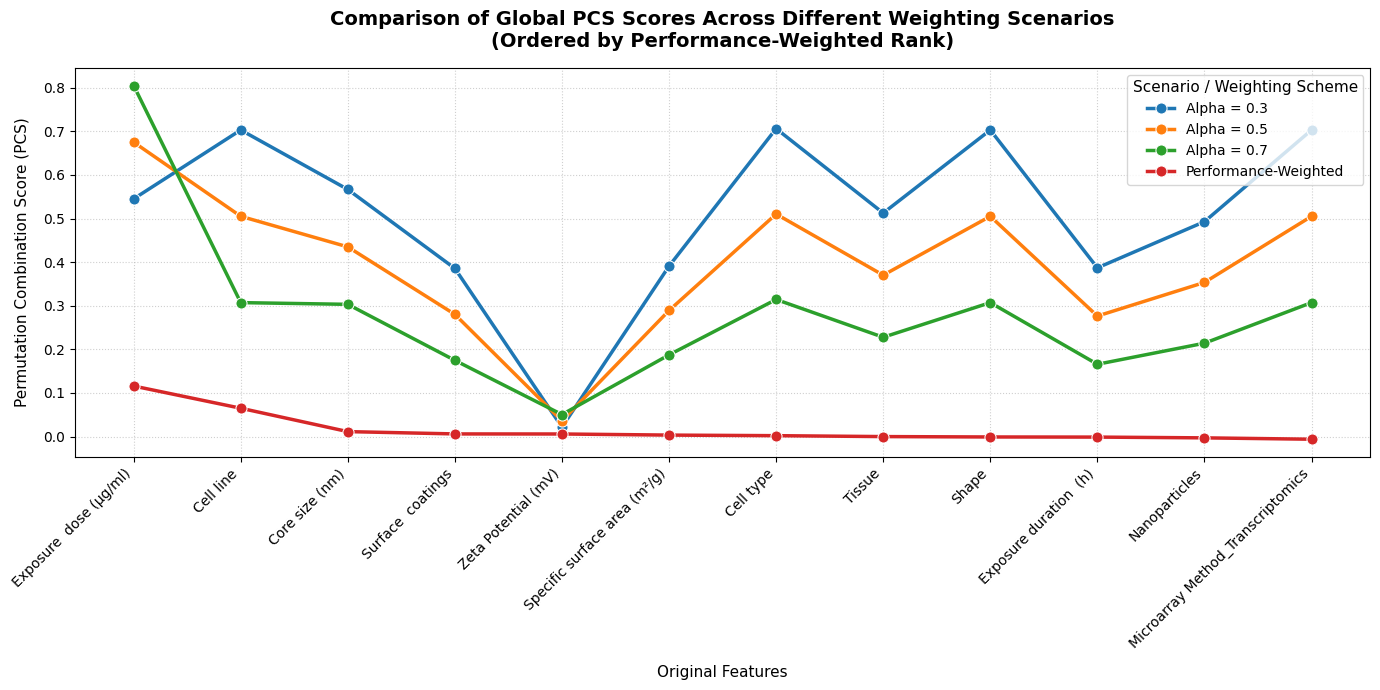

In [138]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1.Load data from a saved comprehensive report
df_report = pd.read_excel('df_PFI_PCS_all_scenarios_comprehensive_report.xlsx')

# Clean up feature names by removing extra spaces to ensure consistency during visualization
df_report['Original_Feature'] = df_report['Original_Feature'].str.strip()

# 2. Restructuring data to be plotting-friendly (melting/tidying)
# PCS_Alpha_0.7, PCS_Alpha_0.5, PCS_Alpha_0.3, dan PCS_Performance_Outer
scenarios = {
    'PCS_Alpha_0.7': 'Alpha = 0.7',
    'PCS_Alpha_0.5': 'Alpha = 0.5',
    'PCS_Alpha_0.3': 'Alpha = 0.3',
    'PCS_Performance_Outer': 'Performance-Weighted'
}

df_plot = df_report[['Original_Feature', 'PCS_Alpha_0.7', 'PCS_Alpha_0.5', 'PCS_Alpha_0.3', 'PCS_Performance_Outer']].copy()

df_melted = df_plot.melt(
    id_vars=['Original_Feature'],
    value_vars=list(scenarios.keys()),
    var_name='Scenario',
    value_name='PCS_Score'
)

df_melted['Scenario'] = df_melted['Scenario'].map(scenarios)

# Sort features by the highest Performance-Weighted value in the main report
feature_order = df_report.sort_values(by='PCS_Performance_Outer', ascending=False)['Original_Feature'].tolist()
df_melted['Original_Feature'] = pd.Categorical(df_melted['Original_Feature'], categories=feature_order, ordered=True)
df_melted = df_melted.sort_values(by=['Original_Feature', 'Scenario']).reset_index(drop=True)

# 3. Visualize a Comparative Line Graph
plt.figure(figsize=(14, 7))
sns.lineplot(
    data=df_melted,
    x='Original_Feature',
    y='PCS_Score',
    hue='Scenario',
    marker='o',
    linewidth=2.5,
    markersize=8
)

# Chart Customization
plt.title('Comparison of Global PCS Scores Across Different Weighting Scenarios\n(Ordered by Performance-Weighted Rank)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Original Features', fontsize=11, labelpad=10)
plt.ylabel('Permutation Combination Score (PCS)', fontsize=11, labelpad=10)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(title='Scenario / Weighting Scheme', fontsize=10, title_fontsize=11)
plt.tight_layout()
plt.show()

In [139]:
import pandas as pd
import numpy as np
from sklearn.metrics import accuracy_score

# 1. Reload testing data
test_path = "/content/drive/MyDrive/Eksperimen1/LTCDAR3_TEST.csv"
df_test_new = pd.read_csv(test_path)

# 2. Remove rows that have empty target values
TARGET_COL = "Cell death and Apoptosis responses"
df_test_new = df_test_new.dropna(subset=[TARGET_COL])

# Separate the features and the target
X_test_new = df_test_new.drop(columns=[TARGET_COL])
y_test_new = df_test_new[TARGET_COL]

# 3. Dynamic alignment of column names, as is done in development
X_test_new_adjusted = X_test_new.copy()
rename_dict = {}
for col in X_test_new_adjusted.columns:
    if 'Specific surface area' in col:
        rename_dict[col] = 'Specific surface area (m²/g)'
if rename_dict:
    X_test_new_adjusted = X_test_new_adjusted.rename(columns=rename_dict)

# 4. Perform predictions using the best model that has been trained (best_model)
y_pred_new = best_model.predict(X_test_new_adjusted)
y_proba_new = best_model.predict_proba(X_test_new_adjusted) if hasattr(best_model.named_steps['clf'], 'predict_proba') else None

# 5. Calculate evaluation metrics using the existing compute_metrics function
new_evaluation_metrics = compute_metrics(y_test_new, y_pred_new, y_proba_new)

# 6. Create a result DataFrame for storage
df_new_test_evaluation = pd.DataFrame([new_evaluation_metrics])
df_new_test_evaluation.insert(0, 'Classifier', best_classifier_name)
df_new_test_evaluation.insert(1, 'Imputation_Method', best_imputation_method)

# Format metric as a percentage
percentage_cols = ["Accuracy", "Precision", "Sensitivity", "F1", "Specificity", "AUC", "Error_Rate", "FPR", "FNR", "MCC"]
for col in percentage_cols:
    if col in df_new_test_evaluation.columns:
        df_new_test_evaluation[col] = pd.to_numeric(df_new_test_evaluation[col], errors='coerce')
        df_new_test_evaluation[col] = df_new_test_evaluation[col].apply(lambda x: f"{x:.2%}" if pd.notna(x) else x)

print("=== TESTING DATA EVALUATION RESULTS (CLEAR OF MISSING VALUES)) ===")
display(df_new_test_evaluation)

# 7. Save to a new Excel file
output_file = "new_test_evaluation_results_clean.xlsx"
df_new_test_evaluation.to_excel(output_file, index=False)
print(f"\nThe evaluation results were successfully saved to '{output_file}'")

=== TESTING DATA EVALUATION RESULTS (CLEAR OF MISSING VALUES)) ===


,Classifier,Imputation_Method,Accuracy,Precision,Sensitivity,F1,Specificity
0,RandomForest,IIBR,100.00%,100.00%,100.00%,100.00%,100.00%



The evaluation results were successfully saved to 'new_test_evaluation_results_clean.xlsx'


In [147]:
import pandas as pd
import numpy as np
from sklearn.metrics import accuracy_score

# 1. Load CCA (Common Cohort Analysis) testing data
test_cca_path = "/content/drive/MyDrive/Eksperimen1/LTCDAR3_CCA_TEST.csv"
df_test_cca = pd.read_csv(test_cca_path)

# 2. Clear any empty target rows, if present
TARGET_COL = "Cell death and Apoptosis responses"
df_test_cca = df_test_cca.dropna(subset=[TARGET_COL])

X_test_cca = df_test_cca.drop(columns=[TARGET_COL])
y_test_cca = df_test_cca[TARGET_COL]

# 3. Dynamic and robust column name alignment
X_test_cca_adjusted = X_test_cca.copy()
rename_dict = {}

# A loop to detect similarities in column names, while being tolerant of spaces and symbols
for col in X_test_cca_adjusted.columns:
    col_clean = " ".join(col.split())
    # Align 'specific surface area'
    if 'Specific surface area' in col:
        rename_dict[col] = 'Specific surface area (m²/g)'
    # Align double-spaced 'Exposure dose' in training data
    elif 'Exposure' in col_clean and 'dose' in col_clean:
        rename_dict[col] = 'Exposure  dose (μg/ml)'

if rename_dict:
    X_test_cca_adjusted = X_test_cca_adjusted.rename(columns=rename_dict)

# 4. Prediction using the best model (best_model)
y_pred_cca = best_model.predict(X_test_cca_adjusted)
y_proba_cca = best_model.predict_proba(X_test_cca_adjusted) if hasattr(best_model.named_steps['clf'], 'predict_proba') else None

# 5. Calculate the complete set of evaluation metrics
cca_evaluation_metrics = compute_metrics(y_test_cca, y_pred_cca, y_proba_cca)

# 6. Create a DataFrame of the evaluation results
df_cca_evaluation = pd.DataFrame([cca_evaluation_metrics])
df_cca_evaluation.insert(0, 'Classifier', best_classifier_name)
df_cca_evaluation.insert(1, 'Imputation_Method', best_imputation_method)

# Format metric as a percentage
percentage_cols = ["Accuracy", "Precision", "Sensitivity", "F1", "Specificity", "AUC", "Error_Rate", "FPR", "FNR"]
for col in percentage_cols:
    if col in df_cca_evaluation.columns:
        df_cca_evaluation[col] = pd.to_numeric(df_cca_evaluation[col], errors='coerce')
        df_cca_evaluation[col] = df_cca_evaluation[col].apply(lambda x: f"{x:.2%}" if pd.notna(x) else x)

print("\n=== EVALUATION RESULTS OF CCA (COMMON COHORT) TESTING DATA (14 DATA) ===")
display(df_cca_evaluation)

# 7. Save to a new Excel file
output_cca_file = "cca_test_evaluation_results_clean.xlsx"
df_cca_evaluation.to_excel(output_cca_file, index=False)
print(f"\nThe CCA evaluation results were successfully saved to '{output_cca_file}'")


=== EVALUATION RESULTS OF CCA (COMMON COHORT) TESTING DATA (14 DATA) ===


,Classifier,Imputation_Method,Accuracy,Precision,Sensitivity,F1,Specificity
0,RandomForest,IIBR,100.00%,100.00%,100.00%,100.00%,100.00%



The CCA evaluation results were successfully saved to 'cca_test_evaluation_results_clean.xlsx'


=== CONFUSION MATRIX - FOR FINAL MODEL (COMMON COHORT) ===


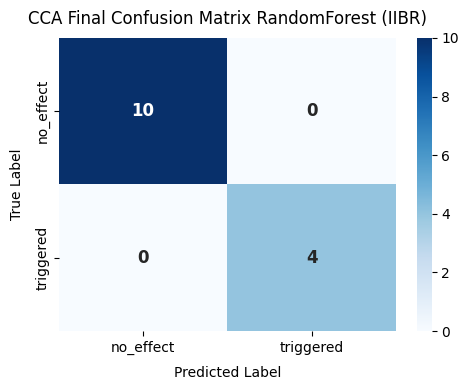

\nDetailed Calculation Breakdown:
- True Negatives (TN)  : 10 (Benar diprediksi 'no_effect')
- False Positives (FP) : 0 (Salah diprediksi 'triggered')
- False Negatives (FN) : 0 (Salah diprediksi 'no_effect')
- True Positives (TP)  : 4 (Benar diprediksi 'triggered')


In [141]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

print("=======================================================")
print("=== CONFUSION MATRIX - FOR FINAL MODEL (COMMON COHORT) ===")
print("=======================================================")

# Extract the unique class labels and sort them to ensure consistency
classes_cca = sorted(list(y_test_cca.unique()))

# Calculate the Confusion Matrix
cm_cca = confusion_matrix(y_test_cca, y_pred_cca, labels=classes_cca)

# Visualizing a Confusion Matrix using a Seaborn Heatmap
plt.figure(figsize=(5, 4))
sns.heatmap(
    cm_cca,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=classes_cca,
    yticklabels=classes_cca,
    annot_kws={"size": 12, "weight": "bold"}
)

plt.title(f'CCA Final Confusion Matrix {best_classifier_name} ({best_imputation_method})', fontsize=12, pad=10)
plt.xlabel('Predicted Label', fontsize=10, labelpad=8)
plt.ylabel('True Label', fontsize=10, labelpad=8)
plt.tight_layout()
plt.show()

# Displaying TP, TN, FP, and FN details in textual form
print("\\nDetailed Calculation Breakdown:")
if len(classes_cca) == 2:
    # Assumption of binary classification with labels no_effect (negative) and triggered (positive)
    tn, fp, fn, tp = cm_cca.ravel()
    print(f"- True Negatives (TN)  : {tn} (Benar diprediksi '{classes_cca[0]}')")
    print(f"- False Positives (FP) : {fp} (Salah diprediksi '{classes_cca[1]}')")
    print(f"- False Negatives (FN) : {fn} (Salah diprediksi '{classes_cca[0]}')")
    print(f"- True Positives (TP)  : {tp} (Benar diprediksi '{classes_cca[1]}')")
else:
    print(cm_cca)

In [143]:
import numpy as np
import pandas as pd
from sklearn.utils import resample
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score

# 1. Preparing a Test Dataset with Aligned Columns
X_test_non_cca = X_test_adjusted_fixed.copy() if 'X_test_adjusted_fixed' in globals() else X_test_adjusted.copy()
y_test_non_cca = y_test.copy()

X_test_cca_fixed = X_test_cca_adjusted_fixed.copy() if 'X_test_cca_adjusted_fixed' in globals() else (X_test_cca_adjusted.copy() if 'X_test_cca_adjusted' in globals() else X_test_cca.copy())
y_test_cca_fixed = y_test_cca.copy() if 'y_test_cca' in globals() else y_test_cca_sens.copy()

# 2. Define the Wilson Score Interval Function
def wilson_score_interval(p, n, confidence=0.95):
    if n == 0:
        return 0.0, 0.0
    z = 1.95996  # z-score untuk 95% CI
    denominator = 1 + z**2 / n
    centre_adjusted_probability = p + z**2 / (2 * n)
    adjusted_variance = z * np.sqrt((p * (1 - p) + z**2 / (4 * n)) / n)
    lower_bound = (centre_adjusted_probability - adjusted_variance) / denominator
    upper_bound = (centre_adjusted_probability + adjusted_variance) / denominator
    return max(0.0, lower_bound), min(1.0, upper_bound)

# 3. Comprehensive Computational Functions for Both Scenarios
def compute_unified_confidence_intervals(X_data, y_data, dataset_label):
    n_samples = len(y_data)

    # Point Estimate
    y_pred = best_model.predict(X_data)
    y_proba = best_model.predict_proba(X_data) if hasattr(best_model, 'predict_proba') else None
    metrics_point = compute_metrics(y_data, y_pred, y_proba)

    # Bootstrap Resampling 1000x
    n_bootstrap = 1000
    boot_f1_scores = []
    boot_auc_scores = []

    np.random.seed(RANDOM_STATE)
    for i in range(n_bootstrap):
        X_res, y_res = resample(X_data, y_data, replace=True, n_samples=n_samples, random_state=RANDOM_STATE + i)
        y_pred_res = best_model.predict(X_res)
        y_proba_res = best_model.predict_proba(X_res) if hasattr(best_model, 'predict_proba') else None

        classes_res = np.unique(y_res)
        acc_res = accuracy_score(y_res, y_pred_res)
        f1_res = f1_score(y_res, y_pred_res, average='weighted', zero_division=0)

        auc_res = np.nan
        if y_proba_res is not None and len(classes_res) == 2:
            try:
                auc_res = roc_auc_score(pd.get_dummies(y_res), y_proba_res, average='weighted', multi_class='ovr')
            except:
                auc_res = acc_res
        else:
            auc_res = acc_res

        boot_f1_scores.append(f1_res)
        boot_auc_scores.append(auc_res)

    # 95% Bootstrap Percentile CI Limits
    f1_lower, f1_upper = np.percentile(boot_f1_scores, 2.5), np.percentile(boot_f1_scores, 97.5)
    auc_lower, auc_upper = np.nanpercentile(boot_auc_scores, 2.5), np.nanpercentile(boot_auc_scores, 97.5)

    scenario_records = []

    wilson_metrics = [
        ("Accuracy", metrics_point.get("Accuracy", 0.0)),
        ("Precision", metrics_point.get("Precision", 0.0)),
        ("Sensitivity", metrics_point.get("Sensitivity", 0.0)),
        ("Specificity", metrics_point.get("Specificity", 0.0)),
        ("Error Rate", metrics_point.get("Error_Rate", 1.0 - metrics_point.get("Accuracy", 0.0)))
    ]

    for name, score in wilson_metrics:
        lower, upper = wilson_score_interval(score, n_samples)
        scenario_records.append({
            "Metric": name,
            "Method": "Wilson Score",
            "Estimate": f"{score:.2%}",
            "95% CI": f"[{lower:.2%}, {upper:.2%}]"
        })

    # F1-Score (Bootstrap)
    scenario_records.append({
        "Metric": "F1-Score",
        "Method": "Bootstrap Percentile (1000x)",
        "Estimate": f"{metrics_point.get('F1', 0.0):.2%}",
        "95% CI": f"[{f1_lower:.2%}, {f1_upper:.2%}]"
    })

    # AUC (Bootstrap)
    scenario_records.append({
        "Metric": "AUC",
        "Method": "Bootstrap Percentile (1000x)",
        "Estimate": f"{metrics_point.get('AUC', 0.0):.2%}",
        "95% CI": f"[{auc_lower:.2%}, {auc_upper:.2%}]"
    })

    return pd.DataFrame(scenario_records)

# 4. Calculate for Both Scenarios
df_non_cca_ci = compute_unified_confidence_intervals(X_test_non_cca, y_test_non_cca, "Non-CCA (19 samples)")
df_cca_ci = compute_unified_confidence_intervals(X_test_cca_fixed, y_test_cca_fixed, "CCA (14 samples)")

# 5. Merge Side-by-Side
df_side_by_side = pd.merge(
    df_non_cca_ci.rename(columns={"Estimate": "Non-CCA (19) Estimate", "95% CI": "Non-CCA (19) 95% CI"}),
    df_cca_ci.rename(columns={"Estimate": "CCA (14) Estimate", "95% CI": "CCA (14) 95% CI"}),
    on=["Metric", "Method"],
    how="outer"
)

print("=== INTEGRATION TABLE OF EVALUATION METRICS AND 95% CONFIDENCE INTERVALS ===")
display(df_side_by_side)

# Save to Excel
output_filename = "best_model_dual_scenarios_confidence_intervals_side_by_side.xlsx"
df_side_by_side.to_excel(output_filename, index=False)
print(f"\nThe side-by-side comparison results have been saved to a new file: '{output_filename}'")

=== INTEGRATION TABLE OF EVALUATION METRICS AND 95% CONFIDENCE INTERVALS ===


,Metric,Method,Non-CCA (19) Estimate,Non-CCA (19) 95% CI,CCA (14) Estimate,CCA (14) 95% CI
0,AUC,Bootstrap Percentile (1000x),0.00%,"[100.00%, 100.00%]",0.00%,"[100.00%, 100.00%]"
1,Accuracy,Wilson Score,100.00%,"[83.18%, 100.00%]",100.00%,"[78.47%, 100.00%]"
2,Error Rate,Wilson Score,0.00%,"[0.00%, 16.82%]",0.00%,"[0.00%, 21.53%]"
3,F1-Score,Bootstrap Percentile (1000x),100.00%,"[100.00%, 100.00%]",100.00%,"[100.00%, 100.00%]"
4,Precision,Wilson Score,100.00%,"[83.18%, 100.00%]",100.00%,"[78.47%, 100.00%]"
5,Sensitivity,Wilson Score,100.00%,"[83.18%, 100.00%]",100.00%,"[78.47%, 100.00%]"
6,Specificity,Wilson Score,100.00%,"[83.18%, 100.00%]",100.00%,"[78.47%, 100.00%]"



The side-by-side comparison results have been saved to a new file: 'best_model_dual_scenarios_confidence_intervals_side_by_side.xlsx'


In [144]:
import pandas as pd

# Preparing test data with dynamically aligned column names
X_test_compare = X_test.copy()
rename_dict = {}
for col in X_test_compare.columns:
    if 'Specific surface area' in col:
        rename_dict[col] = 'Specific surface area (m²/g)'
if rename_dict:
    X_test_compare = X_test_compare.rename(columns=rename_dict)

# Generating label predictions and probabilities
y_pred_compare = best_model.predict(X_test_compare)
y_proba_compare = best_model.predict_proba(X_test_compare)[:, 1] if hasattr(best_model.named_steps['clf'], 'predict_proba') else None

# Creating a comparison DataFrame
df_comparison = pd.DataFrame({
    'Index': X_test.index,
    'Actual_Label': y_test,
    'Predicted_Label': y_pred_compare
})

if y_proba_compare is not None:
    df_comparison['Probability_triggered'] = y_proba_compare

# Displaying prediction matches (True/False)
df_comparison['Prediction_Correct'] = df_comparison['Actual_Label'] == df_comparison['Predicted_Label']

print("=== COMPARISON OF PREDICTIONS VS. ACTUAL LABELS (TEST DATA) ===")
display(df_comparison)


=== COMPARISON OF PREDICTIONS VS. ACTUAL LABELS (TEST DATA) ===


,Index,Actual_Label,Predicted_Label,Probability_triggered,Prediction_Correct
0,0,triggered,triggered,0.649791,True
1,1,triggered,triggered,0.644259,True
2,2,triggered,triggered,0.617285,True
3,3,no_effect,no_effect,0.066066,True
4,4,no_effect,no_effect,0.084840,True
5,5,no_effect,no_effect,0.344010,True
6,6,no_effect,no_effect,0.142707,True
7,7,no_effect,no_effect,0.159630,True
8,8,no_effect,no_effect,0.408484,True
9,9,no_effect,no_effect,0.048916,True


In [145]:
df_comparison.to_excel('comparison_of_predictions_vs_actuals.xlsx', index=False)
print("The file comparison_prediction_vs_actual.xlsx has been successfully saved!")

The file comparison_prediction_vs_actual.xlsx has been successfully saved!
